<h1 style="font-weight:900; color:#0E2841; color:var(--vscode-foreground, #0E2841); margin:0.4em 0 0.2em; overflow:hidden;"><span style="float:right"><span class="modulchip" style="font-size:0.55em; font-weight:bold; letter-spacing:0.02em; border:1.5px solid #B8860B; color:#B8860B; padding:1px 8px; border-radius:10px; margin-left:12px; vertical-align:0.35em; white-space:nowrap;">M2 · Data-Science-Werkzeugkasten</span></span>Lerneinheit 5 · scikit-learn und der Übergang zu PyTorch</h1>

<div style="font-size:0.8em; color:#5a6472; color:var(--vscode-descriptionForeground, #5a6472); margin-top:-4px;">Version 1.1</div>

<span style="color:#5a6472; color:var(--vscode-descriptionForeground, #5a6472); font-size:0.9em;">Tensor to GPU – Programmierkonzepte für KI · Prof. Dr. Stephan Kurpjuweit · Hochschule Worms · © 2026</span>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Lernziele</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Nach dieser Lerneinheit können Sie …</p>
<ul style="list-style:none; padding-left:0.2em; margin:6px 0 0;">
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>Merkmale und Zielgröße getrennt anlegen und gemeinsam in Trainings- und Testteil aufteilen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>begründen, warum alles, was aus Daten gelernt wird, nur aus dem Trainingsteil stammen darf,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>erklären, was bei der Konfiguration eines Transformers festgelegt wird, was er in <code style="color:inherit;">fit</code> lernt und was er in <code style="color:inherit;">transform</code> anwendet, und gelernte Attribute an ihrem Namen erkennen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>einen eigenen Transformer schreiben, der mit <code style="color:inherit;">fit</code> und <code style="color:inherit;">transform</code> in einer <code style="color:inherit;">Pipeline</code> läuft, und die Grenze dieser Lösung benennen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>Lücken füllen, Kategorien als Zahlen kodieren und Merkmale skalieren,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>die Spaltenzahl nach der Vorverarbeitung vorhersagen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>mit <code style="color:inherit;">Pipeline</code> und <code style="color:inherit;">ColumnTransformer</code> numerische und kategoriale Spalten getrennt vorverarbeiten und ein Modell anhängen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>ein Modell mit einer Baseline und der Accuracy auf dem Testteil bewerten,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>ein NumPy-Array als Tensor mit festgelegtem Datentyp und festgelegter Form bereitstellen,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>eine <code style="color:inherit;">Dataset</code>-Klasse mit <code style="color:inherit;">__len__</code> und <code style="color:inherit;">__getitem__</code> schreiben,</li>
<li style="margin:3px 0;"><span style="display:inline-block; width:1.3em; font-size:1.05em; color:#9A7514;">&#9744;</span>mit <code style="color:inherit;">DataLoader</code>, <code style="color:inherit;">iter</code> und <code style="color:inherit;">next</code> Batches der erwarteten Form erzeugen.</li>
</ul>

</div>
</div>

In der letzten Lerneinheit ist aus einer unsauberen Datei eine bereinigte Tabelle geworden. In dieser Lerneinheit machen wir aus der Tabelle die Eingabe für ein Modell. Am Ende liegen die Daten in der Form vor, in der wir sie in der nächsten Lerneinheit für das Training eines neuronalen Netzes brauchen: als Tensoren, die ein `DataLoader` in Batches ausgibt. Ein Batch ist ein Stapel von Beispielen, das letzte Kapitel dieser Lerneinheit erklärt ihn genauer. Dazwischen liegen drei weitere Schritte:

1. Umformungen (Lücken füllen, Kategorien in Zahlen wandeln, Merkmale skalieren), Kapitel <a href="#kap-ein-transformer-zwei-methoden">5.2</a> und <a href="#kap-zusammensetzen-pipeline-und-columntransformer">5.3</a>,
2. ein erstes Modell, das wir mit einer Metrik bewerten und mit einer Baseline vergleichen, Kapitel <a href="#kap-modell-baseline-und-metrik">5.4</a>,
3. der Übergang von NumPy zu PyTorch, Kapitel <a href="#kap-vom-array-zum-tensor">5.5</a> und <a href="#kap-dataset-und-dataloader-batches-auf-abruf">5.6</a>.

Die Bibliothek für die Umformungen und das Modell ist scikit-learn, die verbreitete Bibliothek für klassisches maschinelles Lernen in Python, die Sie im Werkzeugkasten von LE03 schon gesehen haben. Der Pflichtstoff steht im Fließtext, in den Aufgaben und in den Kästen „Überblick“ zu den verwendeten Werkzeugen. Die Boxen „Vertiefung“ und die Codezellen, die mit „Zur Vertiefung“ beginnen, sind Lesestoff für danach. Der Stempel „nicht prüfungsrelevant“ sagt, welche davon nicht geprüft werden.

Neben dem Datenpfad zieht sich ein zweiter Gedanke durch die Lerneinheit, ein Programmierkonzept: Bibliotheken in Python verlangen von einem Objekt selten eine bestimmte Klasse, sondern bestimmte Methoden mit passendem Verhalten. scikit-learn verlangt von einem Transformer `fit` und `transform`, der `DataLoader` von einem Dataset `__len__` und `__getitem__`. Bei der Liste und beim `DataLoader` ruft `iter(...)` die Methode `__iter__` auf und liefert einen Iterator, von dem die `for`-Schleife dann `__next__` verlangt. Sie begegnen dieser Idee an drei Stellen und sehen jedes Mal auch, wo sie nicht mehr ausreicht. Die Sondermethoden `__len__` und `__getitem__` kennen Sie aus der Klasse `Corpus` in LE02. Vererbung und `super().__init__()` kommen in dieser Lerneinheit an einer Stelle vor. Ausführlich behandelt sie Grundkurs Teil 4, der diese Lerneinheit begleitet.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Inhalt</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<ul style="margin:0; padding-left:1.2em;"><li style="margin:5px 0;">5.1&nbsp;&nbsp;<a href="#kap-was-ein-modell-braucht" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Was ein Modell braucht</a></li><li style="margin:5px 0;">5.2&nbsp;&nbsp;<a href="#kap-ein-transformer-zwei-methoden" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Ein Transformer, zwei Methoden</a></li><li style="margin:5px 0;">5.3&nbsp;&nbsp;<a href="#kap-zusammensetzen-pipeline-und-columntransformer" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Zusammensetzen: Pipeline und ColumnTransformer</a></li><li style="margin:5px 0;">5.4&nbsp;&nbsp;<a href="#kap-modell-baseline-und-metrik" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Modell, Baseline und Metrik</a></li><li style="margin:5px 0;">5.5&nbsp;&nbsp;<a href="#kap-vom-array-zum-tensor" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Vom Array zum Tensor</a></li><li style="margin:5px 0;">5.6&nbsp;&nbsp;<a href="#kap-dataset-und-dataloader-batches-auf-abruf" style="color:#1a1a1a; text-decoration:none; border-bottom:1px solid #E8B029;">Dataset und DataLoader: Batches auf Abruf</a></li></ul>

</div>
</div>

Die Landkarte zeigt den Weg dieser Lerneinheit von der bereinigten Tabelle links bis zum Batch unten. Links steht die bereinigte Tabelle `df` mit elf Spalten, aus der wir die Merkmale `X` (sieben Spalten) und die Zielspalte `y` auswählen. Der erste Pfeil ist die Trennung in Trainings- und Testteil. Danach läuft der Trainingsteil durch die Vorverarbeitung, die aus sieben Spalten zwölf Zahlenspalten macht, und in das Modell. Der Testteil läuft nur durch `transform`, aus ihm wird nichts gelernt. Der untere Zweig führt dieselben zwölf Spalten als Tensor in ein `Dataset` und einen `DataLoader`, der Batches von 64 Zeilen liefert. Die Zahlen an den Kästen sind die Formen der Objekte an dieser Stelle, die Kapitelnummern über den Kästen sagen, wo jedes Objekt entsteht.

## <a id="kap-was-ein-modell-braucht"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">5.1&nbsp;&nbsp;Was ein Modell braucht</span>

Die Ladezelle stellt die bereinigte Titanic-Tabelle mit 1309 Passagieren und elf Spalten bereit. Sie ist das Ergebnis von `clean_titanic` aus der letzten Lerneinheit. Die zweite Zelle richtet die Bibliotheken ein und prüft wie in LE04 die pandas-Version. Führen Sie beide einfach aus.

In [ ]:
# Kursdaten bereitstellen — nutzt data/, lädt Fehlendes aus dem Kursrepo nach
from pathlib import Path
from urllib.request import urlretrieve
for _name in ["titanic_clean.csv"]:
    _ziel = Path("data") / _name
    if not _ziel.exists():
        _ziel.parent.mkdir(parents=True, exist_ok=True)
        try:
            urlretrieve("https://raw.githubusercontent.com/skuhswo/tensor-to-gpu-material/main/data/" + _name, _ziel)
        except Exception as _fehler:
            _ziel.unlink(missing_ok=True)          # keine halbe Datei zurücklassen
            _tipp = ""
            if "CERTIFICATE" in str(_fehler):      # Python von python.org auf dem Mac
                _tipp = (" Auf dem Mac zuerst 'Install Certificates.command' im Ordner "
                         "Programme/Python ausführen.")
            if _name.endswith(".md"):               # Datenblatt: Lektüre, kein Pflichtteil
                print(_ziel, "nicht nachgeladen (Datenblatt, nur Lektüre):", type(_fehler).__name__)
                continue
            raise RuntimeError(f"{_ziel} fehlt und ließ sich nicht nachladen ({type(_fehler).__name__}). "
                               "Legen Sie den Ordner data/ aus dem ZIP der Lerneinheit neben dieses Notebook."
                               + _tipp) from None
    print(_ziel, "\u2713")

In [ ]:
# Vorgabe: Bibliotheken und Kursdaten — einfach ausführen
import numpy as np
import pandas as pd
import sklearn
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

PANDAS_3 = int(pd.__version__.split(".")[0]) >= 3
if not PANDAS_3:
    pd.options.mode.copy_on_write = True      # ältere pandas-Version: das Verhalten von pandas 3 einschalten
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

df = pd.read_csv("data/titanic_clean.csv")
print(df.shape)
print(df.head(3))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Vorgabe: Bibliotheken und Kursdaten — einfach ausführen</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">numpy</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">as</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">np</span>
<span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">pandas</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">as</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">pd</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; scikit-learn heißt beim Import <code style="color:inherit;">sklearn</code>. Die Werkzeuge liegen in Unterpaketen und werden einzeln importiert</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">sklearn</span>
<span style="color: #008000; font-weight: bold">from</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">sklearn.impute</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">import</span> SimpleImputer
<span style="color: #008000; font-weight: bold">from</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">sklearn.preprocessing</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">import</span> OneHotEncoder, StandardScaler
<span style="color: #008000; font-weight: bold">from</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">sklearn.pipeline</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">import</span> Pipeline
<span style="color: #008000; font-weight: bold">from</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">sklearn.compose</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">import</span> ColumnTransformer
<span style="color: #008000; font-weight: bold">from</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">sklearn.model_selection</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">import</span> train_test_split
<span style="color: #008000; font-weight: bold">from</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">sklearn.dummy</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">import</span> DummyClassifier
<span style="color: #008000; font-weight: bold">from</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">sklearn.linear_model</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">import</span> LogisticRegression
<span style="color: #008000; font-weight: bold">from</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">sklearn.metrics</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">import</span> accuracy_score

PANDAS_3 <span style="color: #666">=</span> <span style="color: #008000">int</span>(pd<span style="color: #666">.</span>__version__<span style="color: #666">.</span>split(<span style="color: #BA2121">"."</span>)[<span style="color: #666">0</span>]) <span style="color: #666">&gt;=</span> <span style="color: #666">3</span>
<span style="color: #008000; font-weight: bold">if</span> <span style="color: #A2F; font-weight: bold">not</span> PANDAS_3:
    pd<span style="color: #666">.</span>options<span style="color: #666">.</span>mode<span style="color: #666">.</span>copy_on_write <span style="color: #666">=</span> <span style="color: #008000; font-weight: bold">True</span>      <span style="color: #3D7B7B; font-style: italic"># ältere pandas-Version: das Verhalten von pandas 3 einschalten</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"pandas"</span>, pd<span style="color: #666">.</span>__version__, <span style="color: #BA2121">"| scikit-learn"</span>, sklearn<span style="color: #666">.</span>__version__)

df <span style="color: #666">=</span> pd<span style="color: #666">.</span>read_csv(<span style="color: #BA2121">"data/titanic_clean.csv"</span>)
<span style="color: #008000">print</span>(df<span style="color: #666">.</span>shape)
<span style="color: #008000">print</span>(df<span style="color: #666">.</span>head(<span style="color: #666">3</span>))</code></pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: scikit-learn von oben</span></div>
<p>scikit-learn ist in Unterpakete gegliedert, und jedes Werkzeug wird aus seinem Unterpaket importiert. Die Lerneinheit verwendet diese:</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:28%"><col style="width:38%"><col style="width:34%"></colgroup>
<thead>
<tr>
<th>Unterpaket</th>
<th>Werkzeuge in dieser Lerneinheit</th>
<th>Aufgabe</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">sklearn.model_selection</code></td>
<td><code style="color:inherit;">train_test_split</code></td>
<td>Daten in Trainings- und Testteil trennen</td>
</tr>
<tr>
<td><code style="color:inherit;">sklearn.impute</code></td>
<td><code style="color:inherit;">SimpleImputer</code></td>
<td>Lücken füllen</td>
</tr>
<tr>
<td><code style="color:inherit;">sklearn.preprocessing</code></td>
<td><code style="color:inherit;">OneHotEncoder</code>, <code style="color:inherit;">StandardScaler</code></td>
<td>Kategorien kodieren, Zahlen skalieren</td>
</tr>
<tr>
<td><code style="color:inherit;">sklearn.pipeline</code></td>
<td><code style="color:inherit;">Pipeline</code></td>
<td>Schritte hintereinanderschalten</td>
</tr>
<tr>
<td><code style="color:inherit;">sklearn.compose</code></td>
<td><code style="color:inherit;">ColumnTransformer</code></td>
<td>Spaltengruppen getrennt vorverarbeiten</td>
</tr>
<tr>
<td><code style="color:inherit;">sklearn.linear_model</code></td>
<td><code style="color:inherit;">LogisticRegression</code></td>
<td>das Modell</td>
</tr>
<tr>
<td><code style="color:inherit;">sklearn.dummy</code></td>
<td><code style="color:inherit;">DummyClassifier</code></td>
<td>die Baseline</td>
</tr>
<tr>
<td><code style="color:inherit;">sklearn.metrics</code></td>
<td><code style="color:inherit;">accuracy_score</code>, <code style="color:inherit;">confusion_matrix</code></td>
<td>Vorhersagen bewerten</td>
</tr>
</tbody>
</table>
<p>Daneben gibt es Unterpakete für weitere Modellfamilien (<code style="color:inherit;">sklearn.ensemble</code>, <code style="color:inherit;">sklearn.neighbors</code>, <code style="color:inherit;">sklearn.tree</code>, <code style="color:inherit;">sklearn.svm</code>), für Clustering (<code style="color:inherit;">sklearn.cluster</code>) und für Datensätze zum Üben (<code style="color:inherit;">sklearn.datasets</code>). Alle Werkzeuge folgen derselben Schnittstelle, die diese Lerneinheit einführt: <code style="color:inherit;">fit</code> zum Lernen aus Daten, dazu bei Transformern <code style="color:inherit;">transform</code> und bei Vorhersagemodellen <code style="color:inherit;">predict</code>.</p>

</div>

In der Hausaufgabe der letzten Lerneinheit hat die Funktion `to_arrays` die vier Zahlenspalten in ein Array der Form `(N, 4)` umgewandelt und die Zielspalte als `y` abgelegt. Die nächste Zelle greift diesen Schritt in zwei Zeilen auf und zeigt, warum er für unseren Workflow noch nicht reicht: Das Array enthält Lücken, und für das Modell nehmen wir außerdem die drei kategorialen Spalten `sex`, `embarked` und `pclass` auf, die Information über das Überleben tragen.

In [ ]:
num_cols = ["age", "sibsp", "parch", "fare"]           # die vier Zahlenspalten aus LE04, in derselben Reihenfolge
X_arr = df[num_cols].to_numpy(dtype="float32")
print("Form:", X_arr.shape, "| Lücken im Array:", int(np.isnan(X_arr).sum()))
# Formen: df (1309, 11) -> X_arr (1309, 4)

Für alles, was sich in der Lerneinheit schnell im Kopf nachrechnen lassen soll, führen wir wie in LE04 eine kleine Tabelle `small` mit sechs Passagieren ein. Sie hat genau die acht Spalten, die wir für das Modell brauchen (sieben Merkmale und die Zielspalte), mit einer Lücke in `age` (Zeile 1) und einer in `embarked` (Zeile 5). Die Werte sind dabei erfunden, die Spalten entsprechen aber den Kursdaten.

In [ ]:
small = pd.DataFrame({"pclass":   [1, 3, 3, 2, 1, 3],
                      "sex":      ["female", "male", "male", "female", "male", "female"],
                      "age":      [29.0, np.nan, 25.0, 40.0, 60.0, 2.0],
                      "sibsp":    [0, 0, 1, 1, 0, 3],
                      "parch":    [0, 0, 0, 2, 0, 1],
                      "fare":     [211.3, 7.9, 7.9, 13.0, 80.0, 20.6],
                      "embarked": ["S", "S", "Q", "S", "C", np.nan],
                      "survived": [1, 0, 0, 1, 0, 1]})
print(small)

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 5.1 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Was kommt heraus? Die nächste Zelle enthält vier Codezeilen, die mit der Tabelle <code style="color:inherit;">small</code> arbeiten. Schreiben Sie für jede Zeile Ihre Vorhersage hinter das <code style="color:inherit;"># -&gt;</code> (Werte, Form oder Typ, so genau Sie können), dann führen Sie die Zelle aus und vergleichen. Wo die Vorhersage danebenlag, ändern Sie die Zeile ab, etwa eine andere Spalte oder ein anderer Wert, und prüfen Sie, ob Sie das neue Ergebnis jetzt vorhersagen können. Neu ist <code style="color:inherit;">nunique()</code>: Es zählt, wie viele verschiedene Werte eine Spalte hat, doppelte Werte zählen einmal.</p>

</div>
</div>

In [ ]:
print(small.isna().sum().tolist())             # -> ?
print(small["sex"].nunique())                  # -> ?
print(small[["age", "fare"]].max().tolist())   # -> ?
print(small["survived"].mean())                # -> ?

Drei Dinge hindern uns noch daran, die bereinigte Tabelle direkt an ein Modell zu übergeben. Die nächste Zelle illustriert alle drei am Beispiel der Kursdaten.

In [ ]:
print("1. Lücken je Spalte:")
print(df.isna().sum()[df.isna().sum() > 0])
print()
print("2. Textkategorien:", df["sex"].unique().tolist(), df["embarked"].dropna().unique().tolist(),
      "| pclass sieht aus wie eine Zahl:", sorted(df["pclass"].unique().tolist()))
print()
print("3. Größenordnungen:")
print(df[num_cols].describe().loc[["min", "max"]])

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"1. Lücken je Spalte:"</span>)
<span style="color: #008000">print</span>(df<span style="color: #666">.</span>isna()<span style="color: #666">.</span>sum()[df<span style="color: #666">.</span>isna()<span style="color: #666">.</span>sum() <span style="color: #666">&gt;</span> <span style="color: #666">0</span>])
<span style="color: #008000">print</span>()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">unique()</code> liefert jeden Wert einer Spalte einmal, als Array. <code style="color:inherit;">dropna()</code> lässt die Lücken vorher weg</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"2. Textkategorien:"</span>, df[<span style="color: #BA2121">"sex"</span>]<span style="color: #666">.</span>unique()<span style="color: #666">.</span>tolist(), df[<span style="color: #BA2121">"embarked"</span>]<span style="color: #666">.</span>dropna()<span style="color: #666">.</span>unique()<span style="color: #666">.</span>tolist(),
      <span style="color: #BA2121">"| pclass sieht aus wie eine Zahl:"</span>, <span style="color: #008000">sorted</span>(df[<span style="color: #BA2121">"pclass"</span>]<span style="color: #666">.</span>unique()<span style="color: #666">.</span>tolist()))
<span style="color: #008000">print</span>()</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">describe()</code> fasst Zahlenspalten zusammen. <code style="color:inherit;">.loc[[&quot;min&quot;, &quot;max&quot;]]</code> wählt zwei Zeilen dieser Zusammenfassung über ihre Etiketten aus</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"3. Größenordnungen:"</span>)
<span style="color: #008000">print</span>(df[num_cols]<span style="color: #666">.</span>describe()<span style="color: #666">.</span>loc[[<span style="color: #BA2121">"min"</span>, <span style="color: #BA2121">"max"</span>]])</code></pre></details>

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Welche der elf Spalten brauchen für unseren Modellablauf noch eine Bearbeitung? Unterscheiden Sie fehlende Werte, Kategorien, Bezeichner und freien Text sowie die Entscheidung, wie <code style="color:inherit;">pclass</code> eingehen soll. Zur Erinnerung die elf Spalten mit den Werten von Passagier 0 und der Zahl der Lücken:</p>
<table>
<thead>
<tr>
<th>Spalte</th>
<th>Beispielwert</th>
<th>Lücken</th>
<th></th>
<th>Spalte</th>
<th>Beispielwert</th>
<th>Lücken</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">pclass</code></td>
<td><code style="color:inherit;">1</code></td>
<td>0</td>
<td></td>
<td><code style="color:inherit;">sibsp</code></td>
<td><code style="color:inherit;">0</code></td>
<td>0</td>
</tr>
<tr>
<td><code style="color:inherit;">survived</code></td>
<td><code style="color:inherit;">1</code></td>
<td>0</td>
<td></td>
<td><code style="color:inherit;">parch</code></td>
<td><code style="color:inherit;">0</code></td>
<td>0</td>
</tr>
<tr>
<td><code style="color:inherit;">name</code></td>
<td><code style="color:inherit;">Allen, Miss. Elisabeth Walton</code></td>
<td>0</td>
<td></td>
<td><code style="color:inherit;">ticket</code></td>
<td><code style="color:inherit;">24160</code></td>
<td>0</td>
</tr>
<tr>
<td><code style="color:inherit;">sex</code></td>
<td><code style="color:inherit;">female</code></td>
<td>0</td>
<td></td>
<td><code style="color:inherit;">fare</code></td>
<td><code style="color:inherit;">211.3375</code></td>
<td>1</td>
</tr>
<tr>
<td><code style="color:inherit;">age</code></td>
<td><code style="color:inherit;">29.0</code></td>
<td>265</td>
<td></td>
<td><code style="color:inherit;">cabin</code></td>
<td><code style="color:inherit;">B5</code></td>
<td>1014</td>
</tr>
<tr>
<td></td>
<td></td>
<td></td>
<td></td>
<td><code style="color:inherit;">embarked</code></td>
<td><code style="color:inherit;">S</code></td>
<td>2</td>
</tr>
</tbody>
</table>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#C62828; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Definition: Arten von Merkmalen</div>
<div style="background:#FDECEA; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Ein Modell behandelt nicht jede Spalte gleich. Für die Vorverarbeitung unterscheiden wir zwei Arten von Merkmalen:</p>
<ul>
<li><strong>Numerische Merkmale</strong> sind Zahlen, mit denen sich rechnen lässt: Messwerte wie <code style="color:inherit;">age</code> und <code style="color:inherit;">fare</code> oder Zählwerte wie <code style="color:inherit;">sibsp</code> und <code style="color:inherit;">parch</code>. Sie werden skaliert.</li>
<li><strong>Kategoriale Merkmale</strong> nehmen einen Wert aus einer festen Menge an: <code style="color:inherit;">sex</code> (zwei Werte), <code style="color:inherit;">embarked</code> (drei Häfen). Haben die Werte keine Reihenfolge, heißen sie nominal, haben sie eine (Fahrklasse 1 vor 2 vor 3), heißen sie ordinal. Sie werden kodiert, also in Zahlenspalten übersetzt. Ein kategoriales Merkmal kann als Zahl gespeichert sein: <code style="color:inherit;">pclass</code> enthält 1, 2 und 3, bezeichnet aber Fahrklassen. Abstände und Rechenoperationen mit diesen Kennungen ergeben keinen Sinn: Der Mittelwert der Fahrklassen 1 und 3 ist nicht die Fahrklasse 2, und das Doppelte von Klasse 1 bedeutet nichts. Die Bedeutung ist durch die Daten gegeben, wie das Merkmal für unser Modell dargestellt wird (als eine Zahl oder als Kategorie kodiert), entscheiden wir.</li>
</ul>
<p>Dazu kommen Spalten, die sich zwar als Kategorien kodieren ließen, für ein einfaches Modell aber wenig taugen: <strong>Bezeichner und freier Text</strong> wie <code style="color:inherit;">name</code>, <code style="color:inherit;">ticket</code> und <code style="color:inherit;">cabin</code>. Sie enthalten sehr viele verschiedene Werte (<code style="color:inherit;">ticket</code> hat 929 verschiedene bei 1309 Zeilen), bei <code style="color:inherit;">cabin</code> fehlen außerdem die meisten Angaben. Als Kategorie kodiert entstünde je Wert eine Spalte. Solche Spalten brauchen eigene Merkmalsbildung (zum Beispiel die Anrede aus <code style="color:inherit;">name</code>, wie in LE04) oder bleiben weg.</p>
<p>Die Zielgröße entscheidet über die Art der Aufgabe. Bei einer Klassifikation sagen wir eine Kategorie voraus, hier „überlebt“ oder „nicht überlebt“, und die Zahlen 0 und 1 in <code style="color:inherit;">survived</code> sind die Kennungen dieser zwei Kategorien. Bei einer Regression sagen wir eine Größe voraus, mit der sich rechnen lässt, etwa den Fahrpreis.</p>

</div>
</div>

<div style="border:2px solid #156082; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#156082; font-weight:bold; font-size:1.08em;">Festlegung: Was unser Modell bekommt</span></div>
<p>Für unseren Workflow legen wir fest, in welcher Form das Modell seine Eingabe bekommen soll. Diese Festlegung gilt für die Modelle dieses Kurses, nicht generell für jedes Lernverfahren.</p>
<ul>
<li>Die Eingabe (die Trainingsdaten und später jede neue Beobachtung) ist ein Array der Form <code style="color:inherit;">(N, D)</code> aus Fließkommazahlen ohne Lücken: eine Zeile je Passagier, eine Spalte je Merkmal. Die logistische Regression und die neuronalen Netze der nächsten Lerneinheiten multiplizieren jeden Wert mit einem Gewicht und summieren, und eine Lücke (<code style="color:inherit;">NaN</code>) macht diese Summe zu <code style="color:inherit;">NaN</code>. Baumverfahren wie <code style="color:inherit;">HistGradientBoostingClassifier</code> behandeln eine Lücke als eigenen Fall und kommen ohne Füllen aus.</li>
<li>Die Zielspalte <code style="color:inherit;">survived</code>, also das, was das Modell vorhersagen soll, bleibt getrennt davon als <code style="color:inherit;">y</code> mit der Form <code style="color:inherit;">(N,)</code>.</li>
<li>Kategorien werden in Zahlen übersetzt, Lücken gefüllt, Zahlenspalten auf eine gemeinsame Größenordnung gebracht. Wie, zeigen die nächsten Kapitel. Auch <code style="color:inherit;">pclass</code> behandeln wir als Kategorie, obwohl die Spalte schon Zahlen enthält. Das ist eine Modellierungsentscheidung. Als Kategorie kodiert bekommt jede der drei Fahrklassen eine eigene Spalte und damit im Modell ein eigenes Gewicht, der Einfluss der 2. Klasse hängt nicht von dem der 1. und 3. ab. Als eine Zahl 1, 2, 3 bekäme <code style="color:inherit;">pclass</code> nur ein Gewicht, und das Modell müsste annehmen, dass der Schritt von der 1. zur 2. Klasse genauso wirkt wie der von der 2. zur 3. Klasse.</li>
</ul>
<p>Die Merkmalsspalten sind die vier Zahlenspalten aus LE04 (<code style="color:inherit;">age</code>, <code style="color:inherit;">sibsp</code>, <code style="color:inherit;">parch</code>, <code style="color:inherit;">fare</code>) und die drei Kategorien (<code style="color:inherit;">sex</code>, <code style="color:inherit;">embarked</code>, <code style="color:inherit;">pclass</code>). <code style="color:inherit;">name</code>, <code style="color:inherit;">ticket</code> und <code style="color:inherit;">cabin</code> verwenden wir nicht, der Einfachheit halber: <code style="color:inherit;">name</code> hat 1307 verschiedene Werte, <code style="color:inherit;">ticket</code> 929, und <code style="color:inherit;">cabin</code> ist zu 77 Prozent leer und hat unter den 295 Angaben 186 verschiedene Werte. Aus solchen Spalten ließen sich zwar Merkmale ableiten, das ist aber nicht Thema dieser Lerneinheit.</p>

</div>

Mit `X` und `y` legen wir Merkmale und Zielgröße getrennt an. Danach treffen wir eine Entscheidung, die vor allen weiteren Schritten kommen muss: Ein Modell wird an Daten gemessen, die es beim Lernen nicht gesehen hat. Sonst wüssten wir nur, wie gut es die Antworten wiedergibt, die es schon kennt. Deshalb teilen wir die Tabelle, bevor irgendetwas aus ihr gelernt wird, in einen Trainingsteil und einen Testteil. Alles, was in den nächsten Kapiteln aus Daten berechnet wird (ein Median, ein Mittelwert, die Gewichte eines Modells), kommt aus dem Trainingsteil. Der Testteil bleibt bis zur Bewertung unangetastet.

`train_test_split` teilt `X` und `y` gemeinsam und zufällig. `test_size=0.2` legt ein Fünftel in den Testteil, `random_state=0` macht die Zufallsauswahl bei jedem Lauf gleich.

`stratify=y` steuert, wie die Zufallsauswahl die Klassen verteilt. Ohne diese Angabe zieht `train_test_split` die Zeilen rein zufällig, und der Anteil Überlebender kann im Testteil zufällig höher oder niedriger liegen als im Trainingsteil. Bei unserem Datensatz fällt die Abweichung meist klein aus, bei kleinen Datensätzen oder seltenen Klassen (etwa 5 Prozent Betrugsfälle) kann sie die Bewertung verzerren oder eine Klasse im Testteil fast leer lassen. Mit `stratify=y` zieht die Funktion die Zeilen getrennt je Klasse von `y`, sodass der Anteil jeder Klasse in beiden Teilen näherungsweise gleich bleibt. Die Regel: Bei Klassifikation `stratify` auf die Zielspalte setzen, bei einer Regression weglassen, denn dort gibt es keine Klassen, deren Anteil erhalten bleiben soll. Das gilt für einen zufälligen Split wie hier. Zeitlich geordnete Daten oder zusammengehörige Beobachtungen (mehrere Zeilen derselben Person) brauchen andere Aufteilungen. Führen Sie die Zelle aus. Die Zelle zeigt die Formen und Anteile, die Prüfzelle darunter prüft sie und zeigt die ersten Etiketten des Trainingsteils.

In [ ]:
cat_cols = ["sex", "embarked", "pclass"]
X = df[num_cols + cat_cols]                 # die Merkmale als Tabelle, noch mit Text und Lücken
y = df["survived"]                          # die Zielgröße getrennt davon
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print("Anteil überlebt: train", round(y_train.mean(), 3), "| test", round(y_test.mean(), 3))
# Formen: X (1309, 7) -> X_train (1047, 7), X_test (262, 7);  y (1309,) -> y_train (1047,), y_test (262,)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">cat_cols <span style="color: #666">=</span> [<span style="color: #BA2121">"sex"</span>, <span style="color: #BA2121">"embarked"</span>, <span style="color: #BA2121">"pclass"</span>]
X <span style="color: #666">=</span> df[num_cols <span style="color: #666">+</span> cat_cols]                 <span style="color: #3D7B7B; font-style: italic"># die Merkmale als Tabelle, noch mit Text und Lücken</span>
y <span style="color: #666">=</span> df[<span style="color: #BA2121">"survived"</span>]                          <span style="color: #3D7B7B; font-style: italic"># die Zielgröße getrennt davon</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">train_test_split</code> gibt vier Objekte zurück: die zwei Teile von <code style="color:inherit;">X</code> und die zwei Teile von <code style="color:inherit;">y</code>, in dieser Reihenfolge</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">X_train, X_test, y_train, y_test <span style="color: #666">=</span> train_test_split(X, y, test_size<span style="color: #666">=0.2</span>, stratify<span style="color: #666">=</span>y, random_state<span style="color: #666">=0</span>)
<span style="color: #008000">print</span>(X_train<span style="color: #666">.</span>shape, X_test<span style="color: #666">.</span>shape, y_train<span style="color: #666">.</span>shape, y_test<span style="color: #666">.</span>shape)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Anteil überlebt: train"</span>, <span style="color: #008000">round</span>(y_train<span style="color: #666">.</span>mean(), <span style="color: #666">3</span>), <span style="color: #BA2121">"| test"</span>, <span style="color: #008000">round</span>(y_test<span style="color: #666">.</span>mean(), <span style="color: #666">3</span>))
<span style="color: #3D7B7B; font-style: italic"># Formen: X (1309, 7) -&gt; X_train (1047, 7), X_test (262, 7);  y (1309,) -&gt; y_train (1047,), y_test (262,)</span></code></pre></details>

In [ ]:
# Prüfzelle — einfach ausführen
assert X_train.shape == (1047, 7) and X_test.shape == (262, 7), "ein Fünftel von 1309 Zeilen sind 262 Zeilen im Testteil"
assert y_train.shape == (1047,) and y_test.shape == (262,), "y wird in derselben Aufteilung geteilt"
assert list(X_train.index) == list(y_train.index), "Zeile i von X_train gehört zu Eintrag i von y_train: dieselben Etiketten"
assert abs(y_train.mean() - y_test.mean()) < 0.01, "stratify=y: der Anteil Überlebender ist in beiden Teilen fast gleich"
print("Etiketten der ersten fünf Trainingszeilen:", list(X_train.index[:5]))
print("Alle Prüfungen bestanden ✓")

Die Etiketten des Trainingsteils sind durcheinander, weil `train_test_split` zufällig auswählt. Was Sie aus LE04 wissen, gilt weiter: `X_train.loc[937]` greift über das Etikett auf eine Zeile zu, `X_train.iloc[0]` über die Position. Weil `X` und `y` gemeinsam geteilt wurden, gehört die Zeile an Position `i` von `X_train` zum Eintrag an Position `i` von `y_train`. Diese Zuordnung müssen wir ab jetzt schützen: Sortieren wir eines der beiden Objekte allein, stimmt sie nicht mehr.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Ist <code style="color:inherit;">X_train.loc[0]</code> dasselbe wie <code style="color:inherit;">X_train.iloc[0]</code>?</p>

</div>

## <a id="kap-ein-transformer-zwei-methoden"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">5.2&nbsp;&nbsp;Ein Transformer, zwei Methoden</span>

Die erste Umformung ist das Füllen von Lücken. In scikit-learn ist dafür `SimpleImputer` zuständig, ein Transformer. Ein Transformer hat in scikit-learn immer dieselben zwei Methoden: `fit` lernt etwas aus den übergebenen Daten, `transform` wendet das Gelernte an. Die nächste Zelle führt beides an der Altersspalte von `small` vor und zeigt dabei, was das Objekt in welchem Moment weiß.

In [ ]:
imputer = SimpleImputer(strategy="median")
print("nach dem Anlegen, kennt statistics_:", hasattr(imputer, "statistics_"))
imputer.fit(small[["age"]])
print("nach fit, statistics_:", imputer.statistics_, "| Median der fünf Alterswerte:", small["age"].median())
filled = imputer.transform(small[["age"]])
print("nach transform:", filled.ravel(), type(filled).__name__, filled.shape)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">SimpleImputer(strategy=&quot;median&quot;)</code> legt das Objekt an. <code style="color:inherit;">strategy</code> ist die Konfiguration: Wie soll gefüllt werden?</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">imputer <span style="color: #666">=</span> SimpleImputer(strategy<span style="color: #666">=</span><span style="color: #BA2121">"median"</span>)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"nach dem Anlegen, kennt statistics_:"</span>, <span style="color: #008000">hasattr</span>(imputer, <span style="color: #BA2121">"statistics_"</span>))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">fit(X)</code> berechnet aus den übergebenen Daten die gelernten Werte und legt sie in Attributen mit Unterstrich am Ende ab</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">imputer<span style="color: #666">.</span>fit(small[[<span style="color: #BA2121">"age"</span>]])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"nach fit, statistics_:"</span>, imputer<span style="color: #666">.</span>statistics_, <span style="color: #BA2121">"| Median der fünf Alterswerte:"</span>, small[<span style="color: #BA2121">"age"</span>]<span style="color: #666">.</span>median())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">transform(X)</code> ersetzt jede Lücke durch den gespeicherten Wert und gibt ein NumPy-Array zurück, keine Tabelle</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">filled <span style="color: #666">=</span> imputer<span style="color: #666">.</span>transform(small[[<span style="color: #BA2121">"age"</span>]])</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>④</b>&nbsp; <code style="color:inherit;">ravel()</code> liefert die Werte eines Arrays als eine Zeile, hier mit der Form <code style="color:inherit;">(6,)</code>, damit die Ausgabe kurz bleibt. <code style="color:inherit;">filled</code> selbst behält die Form <code style="color:inherit;">(6, 1)</code></div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"nach transform:"</span>, filled<span style="color: #666">.</span>ravel(), <span style="color: #008000">type</span>(filled)<span style="color: #666">.</span><span style="color: #19177C">__name__</span>, filled<span style="color: #666">.</span>shape)</code></pre></details>

Beim Erzeugen des Objekts legen wir die Strategie fest (`strategy="median"`). Der Imputer hat zu diesem Zeitpunkt noch keine Daten gesehen, deshalb gibt es `statistics_` noch nicht. `fit` berechnet aus den Daten den Median 29, also den mittleren der sortierten Werte 2, 25, 29, 40 und 60, und speichert ihn in `statistics_`. „Lernen“ heißt hier nur: einen Wert aus Daten berechnen und aufbewahren. Ein Vorhersagemodell steckt noch nicht dahinter. `transform` verwendet diesen Median: Jede Lücke wird durch 29 ersetzt, die vorhandenen Werte bleiben unverändert. Der Median ist dabei ein einfacher Ersatzwert. Er stellt den unbekannten Originalwert nicht wieder her, und viele gleiche Ersatzwerte verändern die Verteilung der Spalte. Das Ergebnis ist ein NumPy-Array mit der Form `(6, 1)`, die Spaltennamen der Tabelle sind weg.

Der Unterstrich am Ende von `statistics_` ist eine Konvention von scikit-learn, keine Regel der Sprache Python: Attribute, die `fit` anlegt, enden mit einem Unterstrich, damit sich gelernte Werte von der Konfiguration unterscheiden lassen. scikit-learn verwendet diese Konvention selbst, um zu prüfen, ob ein Objekt schon gefittet wurde.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Was passiert bei <code style="color:inherit;">SimpleImputer(strategy="median").transform(small[["age"]])</code>, also bei <code style="color:inherit;">transform</code> ohne vorheriges <code style="color:inherit;">fit</code>?</p>

</div>

In [ ]:
from sklearn.exceptions import NotFittedError
try:
    SimpleImputer(strategy="median").transform(small[["age"]])
except NotFittedError as e:
    print(type(e).__name__ + ":", str(e)[:80], "…")

Zwei Abkürzungen machen den Code kürzer. Erstens gibt `fit` das Objekt selbst zurück, deshalb lassen sich die Aufrufe aneinanderhängen: `SimpleImputer(strategy="median").fit(X).transform(X)`. Zweitens erledigt `fit_transform(X)` beides in einem Aufruf. Außerdem gilt: Ein erneutes `fit` auf anderen Daten ersetzt die gelernten Werte. Der Imputer merkt sich nur den letzten Stand, ein `transform` danach füllt mit dem neuen Median, der alte ist weg.

In [ ]:
same = imputer.fit(small[["age"]])
print("fit gibt das Objekt zurück:", same is imputer)
print(SimpleImputer(strategy="median").fit_transform(small[["age"]]).ravel())
imputer.fit(small[["fare"]])
print("nach fit auf fare, statistics_:", imputer.statistics_)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">same <span style="color: #666">=</span> imputer<span style="color: #666">.</span>fit(small[[<span style="color: #BA2121">"age"</span>]])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"fit gibt das Objekt zurück:"</span>, same <span style="color: #A2F; font-weight: bold">is</span> imputer)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">fit_transform(X)</code> ist <code style="color:inherit;">fit(X)</code> und danach <code style="color:inherit;">transform(X)</code> in einem Aufruf</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(SimpleImputer(strategy<span style="color: #666">=</span><span style="color: #BA2121">"median"</span>)<span style="color: #666">.</span>fit_transform(small[[<span style="color: #BA2121">"age"</span>]])<span style="color: #666">.</span>ravel())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; ein zweites <code style="color:inherit;">fit</code> auf anderen Daten ersetzt <code style="color:inherit;">statistics_</code>. Der alte Median ist weg</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">imputer<span style="color: #666">.</span>fit(small[[<span style="color: #BA2121">"fare"</span>]])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"nach fit auf fare, statistics_:"</span>, imputer<span style="color: #666">.</span>statistics_)</code></pre></details>

Jetzt wenden wir dieselben zwei Methoden auf die Kursdaten an, und zwar so, wie es die Trennung aus dem ersten Kapitel verlangt: `fit` bekommt nur den Trainingsteil zu sehen. Der Median, der dabei gelernt wird, füllt danach die Lücken in beiden Teilen. Der Testteil bekommt also den Median des Trainingsteils, nicht seinen eigenen, denn `transform` berechnet keinen neuen Median, es setzt nur den gespeicherten ein.

In [ ]:
age_imputer = SimpleImputer(strategy="median").fit(X_train[["age"]])    # lernt nur aus dem Trainingsteil
print("gelernter Median:", age_imputer.statistics_, "| Median im Testteil wäre:", X_test["age"].median(), "| Mittelwert train/test:", round(X_train["age"].mean(), 2), round(X_test["age"].mean(), 2))
age_train = age_imputer.transform(X_train[["age"]])   # anwenden auf den Trainingsteil
age_test = age_imputer.transform(X_test[["age"]])     # anwenden auf den Testteil, mit demselben gelernten Wert
print("Lücken vorher:", int(X_train["age"].isna().sum()), int(X_test["age"].isna().sum()),
      "| nachher:", int(np.isnan(age_train).sum()), int(np.isnan(age_test).sum()))
# Formen: X_train[["age"]] (1047, 1) -> age_train (1047, 1);  X_test[["age"]] (262, 1) -> age_test (262, 1)

Bei diesem Split stimmen die Mediane von Trainings- und Testteil zufällig überein, die Mittelwerte zeigen aber, dass sich die beiden Teile unterscheiden. Den Unterschied zwischen richtigem und falschem Vorgehen sieht man deshalb besser an `small`. Dort sind die Zeilen 1 bis 4 der Trainingsteil und die Zeilen 0 und 5 der Testteil. Die nächste Zelle fittet den Imputer einmal richtig auf den Trainingsteil und einmal falsch auf alle sechs Zeilen.

In [ ]:
small_train = small.iloc[1:5]                # Zeilen 1 bis 4
small_test = small.iloc[[0, 5]]              # Zeilen 0 und 5
print("Altersmedian des Trainingsteils:", small_train["age"].median(), "| aller sechs Zeilen:", small["age"].median())
right = SimpleImputer(strategy="median").fit(small_train[["age"]])    # richtig: nur der Trainingsteil
wrong = SimpleImputer(strategy="median").fit(small[["age"]])          # falsch: alle sechs Zeilen, auch die Testzeilen
print("Zeile 1 gefüllt, richtig:", right.transform(small_train[["age"]])[0, 0], "| falsch:", wrong.transform(small_train[["age"]])[0, 0])

Der richtige Imputer füllt die Lücke in Zeile 1 mit 40, dem Median der vier Trainingszeilen. Der falsche füllt sie mit 29: In diesen Wert sind die Alter der Testzeilen 0 und 5 eingeflossen, also Information, die das Modell nicht haben dürfte. Bei den Kursdaten kommt zufällig derselbe Median heraus. Der Fehler wäre trotzdem derselbe, denn die Vorverarbeitung würde einen Wert verwenden, in den Testzeilen eingeflossen sind.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Der Imputer ist auf <code style="color:inherit;">X_train</code> gefittet. Welchen Wert bekommt eine Lücke im Testteil: den Median des Trainingsteils oder den Median des Testteils?</p>

</div>

Die Grafik zeigt die Arbeitsteilung der zwei Methoden. Der petrolfarbene Pfeil `fit` geht nur vom Trainingsteil zum Transformer und legt dort die gelernten Werte ab (`statistics_`, im Bild der Median 28). Die orangen Pfeile `transform` führen beide Teile durch den Transformer, der dabei nur den gespeicherten Wert verwendet, und enden bei `age_train` und `age_test`. Vom Testteil führt kein `fit`-Pfeil zum Transformer.

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Ersatzwerte für Lücken</span></div>
<p>Die Tabelle nennt die vier benannten Strategien von <code style="color:inherit;">SimpleImputer</code>, die Spalte rechts sagt je Strategie, wann sie passt. Die Beispielwerte beziehen sich zur Veranschaulichung auf die ganze Tabelle, die tatsächlichen Ersatzwerte lernt der Imputer aus dem Trainingsteil. Daneben gibt es in scikit-learn zwei Imputer, die den Ersatzwert aus den anderen Spalten derselben Zeile schätzen.</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:30%"><col style="width:22%"><col style="width:48%"></colgroup>
<thead>
<tr>
<th>Strategie</th>
<th>Ersatzwert</th>
<th>Passt, wenn …</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">strategy="median"</code></td>
<td>der mittlere Wert der Spalte</td>
<td>die Spalte numerisch ist und Ausreißer hat (<code style="color:inherit;">fare</code> reicht bis 512, der Median 14 bleibt davon unberührt, der Mittelwert 33 nicht); die Standardwahl dieses Kurses</td>
</tr>
<tr>
<td><code style="color:inherit;">strategy="mean"</code></td>
<td>der Mittelwert</td>
<td>die Spalte numerisch und ohne starke Ausreißer ist; der Ersatzwert kann dann ein Wert sein, der in der Spalte nie vorkommt (<code style="color:inherit;">age</code>: 29,8)</td>
</tr>
<tr>
<td><code style="color:inherit;">strategy="most_frequent"</code></td>
<td>der häufigste Wert</td>
<td>die Spalte kategorial ist (<code style="color:inherit;">embarked</code>: <code style="color:inherit;">S</code>) oder nur wenige verschiedene Werte hat</td>
</tr>
<tr>
<td><code style="color:inherit;">strategy="constant", fill_value=…</code></td>
<td>ein fester Wert</td>
<td>das Fehlen selbst eine Bedeutung hat und einen eigenen Wert bekommen soll (<code style="color:inherit;">embarked</code> gleich <code style="color:inherit;">"unknown"</code>, dafür entsteht eine eigene One-Hot-Spalte, wenn der Encoder diesen Wert beim Fitten sieht) oder ein fachlicher Standardwert bekannt ist</td>
</tr>
<tr>
<td><code style="color:inherit;">KNNImputer</code></td>
<td>Mittelwert der ähnlichsten Zeilen</td>
<td>die anderen Spalten die Lücke gut vorhersagen; teurer, weil für jede Lücke Nachbarn gesucht werden</td>
</tr>
<tr>
<td><code style="color:inherit;">IterativeImputer</code></td>
<td>Vorhersage eines Modells aus den anderen Spalten</td>
<td>wie <code style="color:inherit;">KNNImputer</code>, mit einem Regressionsmodell je Spalte; in scikit-learn noch als experimentell markiert</td>
</tr>
</tbody>
</table>
<p>Mit <code style="color:inherit;">add_indicator=True</code> kommt für jede Eingabespalte, die beim Fitten Lücken hatte, eine zusätzliche 0/1-Spalte hinzu, die die fehlenden Werte dieser Spalte markiert. Welche Indikatorspalten es gibt, legt <code style="color:inherit;">fit</code> fest, und <code style="color:inherit;">transform</code> liefert immer dieselben. Das Modell kann dann lernen, dass das Fehlen selbst etwas bedeutet.</p>
<p><strong>Warum nicht einfach die Zeilen mit Lücken aussortieren?</strong> Für die Trainingsdaten geht das, <code style="color:inherit;">dropna()</code> aus LE04 tut genau das, und bei wenigen, zufällig verteilten Lücken ist es eine saubere Lösung. Hier spricht dreierlei dagegen. Erstens der Umfang: 268 der 1309 Zeilen haben in einer unserer sieben Spalten eine Lücke, fast immer bei <code style="color:inherit;">age</code>, ein Fünftel der Daten wäre weg. Zweitens die Verzerrung: Die Passagiere ohne Altersangabe reisten zu 79 Prozent in der dritten Klasse, und von ihnen überlebten 28 Prozent gegenüber 41 Prozent der übrigen. Wer sie entfernt, trainiert an einem anderen Datensatz, als er später vorhersagen soll. Drittens die Vorhersage: Eine neue Beobachtung ohne Altersangabe kommt trotzdem, und <code style="color:inherit;">predict</code> muss ihr eine Antwort geben. Dafür braucht es ohnehin eine Füllregel, die am Trainingsteil gelernt wurde. Deshalb füllt dieser Kurs und sortiert nicht aus.</p>

</div>

Die zweite Umformung übersetzt Kategorien in Zahlen. `OneHotEncoder` lernt in `fit` die vorkommenden Werte einer Spalte (`categories_`) und legt in `transform` für jeden Wert eine eigene Spalte an, in der eine 1 steht, wenn die Zeile diesen Wert hat, sonst eine 0. Aus `sex` werden so zwei Spalten, aus `embarked` drei. Das Verfahren heißt One-Hot-Kodierung, weil in jeder Zeile genau eine der neuen Spalten „heiß“, also 1, ist. Warum nicht einfach eine Zahl je Wert, etwa `S` gleich 0, `C` gleich 1, `Q` gleich 2? Das Modell würde mit diesen Zahlen rechnen und damit eine Reihenfolge und gleiche Abstände zwischen den Häfen unterstellen, die es nicht gibt. Mit einer 0/1-Spalte je Wert bekommt jeder Wert im Modell ein eigenes Gewicht, und keine Reihenfolge wird vorausgesetzt. Die Festlegung zu `pclass` im ersten Kapitel folgt demselben Gedanken.

In [ ]:
encoder = OneHotEncoder(sparse_output=False).fit(small[["sex"]])
print("categories_:", [list(c) for c in encoder.categories_])
print(encoder.transform(small[["sex"]]))
# Formen: small[["sex"]] (6, 1) -> transform (6, 2)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">sparse_output=False</code> verlangt ein gewöhnliches Array als Ergebnis (der Standard wäre eine dünnbesetzte Matrix, siehe Vertiefung im nächsten Kapitel)</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">encoder <span style="color: #666">=</span> OneHotEncoder(sparse_output<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">False</span>)<span style="color: #666">.</span>fit(small[[<span style="color: #BA2121">"sex"</span>]])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"categories_:"</span>, [<span style="color: #008000">list</span>(c) <span style="color: #008000; font-weight: bold">for</span> c <span style="color: #A2F; font-weight: bold">in</span> encoder<span style="color: #666">.</span>categories_])
<span style="color: #008000">print</span>(encoder<span style="color: #666">.</span>transform(small[[<span style="color: #BA2121">"sex"</span>]]))
<span style="color: #3D7B7B; font-style: italic"># Formen: small[["sex"]] (6, 1) -&gt; transform (6, 2)</span></code></pre></details>

Lücken und unbekannte Werte sind für den Encoder zwei verschiedene Fälle. Eine Lücke würde `OneHotEncoder` als eigene Kategorie behandeln. Deshalb füllt in unserem Ablauf ein Imputer die Lücken, bevor kodiert wird. Ein Wert, der beim `fit` nicht vorkam und erst später auftaucht (bei `embarked` ein Einschiffungshafen, der nur im Testteil vorkommt), löst dagegen standardmäßig einen Fehler aus. Mit `handle_unknown="ignore"` bekommt eine solche Zeile in allen Spalten von `embarked` eine 0. Es entsteht keine neue Spalte, und die übrigen Spalten der Zeile bleiben unverändert.

In [ ]:
ports = small[["embarked"]].fillna("S")
port_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(ports)
print("categories_:", list(port_encoder.categories_[0]))
unknown_port = pd.DataFrame({"embarked": ["S", "X"]})   # X ist beim fit nicht vorgekommen
print(port_encoder.transform(unknown_port))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">fillna(&quot;S&quot;)</code> füllt die Lücke in embarked für diese Demo direkt. Im Workflow übernimmt das der Imputer</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">ports <span style="color: #666">=</span> small[[<span style="color: #BA2121">"embarked"</span>]]<span style="color: #666">.</span>fillna(<span style="color: #BA2121">"S"</span>)
port_encoder <span style="color: #666">=</span> OneHotEncoder(handle_unknown<span style="color: #666">=</span><span style="color: #BA2121">"ignore"</span>, sparse_output<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">False</span>)<span style="color: #666">.</span>fit(ports)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"categories_:"</span>, <span style="color: #008000">list</span>(port_encoder<span style="color: #666">.</span>categories_[<span style="color: #666">0</span>]))
unknown_port <span style="color: #666">=</span> pd<span style="color: #666">.</span>DataFrame({<span style="color: #BA2121">"embarked"</span>: [<span style="color: #BA2121">"S"</span>, <span style="color: #BA2121">"X"</span>]})   <span style="color: #3D7B7B; font-style: italic"># X ist beim fit nicht vorgekommen</span>
<span style="color: #008000">print</span>(port_encoder<span style="color: #666">.</span>transform(unknown_port))</code></pre></details>

Die dritte Umformung bringt Zahlenspalten auf eine gemeinsame Größenordnung. `StandardScaler` lernt in `fit` je Spalte den Mittelwert (`mean_`) und die Streuung (`scale_`, hier die Standardabweichung) und rechnet in `transform` jeden Wert um: Wert minus Mittelwert, geteilt durch die Streuung. Nach der Umrechnung haben die Trainingsspalten den Mittelwert 0 und die Streuung 1. Eine konstante Spalte hat die Streuung 0, durch sie lässt sich nicht teilen. `StandardScaler` setzt dann `scale_` auf 1, die Spalte wird nur verschoben und besteht danach aus lauter Nullen.

Warum das nötig ist, zeigt die Größenordnung: `fare` reicht bis 512, `sibsp` bis 8. Nach der Standardisierung haben beide Trainingsspalten den Mittelwert 0 und die Streuung 1. Ihre kleinsten und größten Werte können weiterhin verschieden sein. Vergleichbare Größenordnungen erleichtern dem Modell dieser Lerneinheit und den Trainingsverfahren der nächsten die Suche nach passenden Gewichten. Die Standardisierung verschiebt und streckt die Werte nur. Eine schiefe Verteilung bleibt schief, eine Normalverteilung entsteht dadurch nicht. Die nächste Zelle führt die Rechnung an `fare` in `small` vor.

In [ ]:
scaler = StandardScaler().fit(small[["fare"]])
print("mean_:", scaler.mean_.round(3), "| scale_:", scaler.scale_.round(3))
scaled = scaler.transform(small[["fare"]])
print("skaliert:", scaled.ravel().round(3))
print("von Hand, Zeile 0:", round((211.3 - scaler.mean_[0]) / scaler.scale_[0], 3))
print("Mittelwert danach:", scaled.mean().round(6), "| Streuung danach:", scaled.std().round(6))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">scaler <span style="color: #666">=</span> StandardScaler()<span style="color: #666">.</span>fit(small[[<span style="color: #BA2121">"fare"</span>]])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"mean_:"</span>, scaler<span style="color: #666">.</span>mean_<span style="color: #666">.</span>round(<span style="color: #666">3</span>), <span style="color: #BA2121">"| scale_:"</span>, scaler<span style="color: #666">.</span>scale_<span style="color: #666">.</span>round(<span style="color: #666">3</span>))
scaled <span style="color: #666">=</span> scaler<span style="color: #666">.</span>transform(small[[<span style="color: #BA2121">"fare"</span>]])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"skaliert:"</span>, scaled<span style="color: #666">.</span>ravel()<span style="color: #666">.</span>round(<span style="color: #666">3</span>))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">(x - m) / s</code> ist die Rechnung von transform. Hier für die erste Zeile von Hand nachgerechnet</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"von Hand, Zeile 0:"</span>, <span style="color: #008000">round</span>((<span style="color: #666">211.3</span> <span style="color: #666">-</span> scaler<span style="color: #666">.</span>mean_[<span style="color: #666">0</span>]) <span style="color: #666">/</span> scaler<span style="color: #666">.</span>scale_[<span style="color: #666">0</span>], <span style="color: #666">3</span>))
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Mittelwert danach:"</span>, scaled<span style="color: #666">.</span>mean()<span style="color: #666">.</span>round(<span style="color: #666">6</span>), <span style="color: #BA2121">"| Streuung danach:"</span>, scaled<span style="color: #666">.</span>std()<span style="color: #666">.</span>round(<span style="color: #666">6</span>))</code></pre></details>

Mathematisch ergibt sich der Mittelwert 0. Durch Fließkommarundung liefert die Rechnung einen sehr kleinen Wert nahe 0, hier etwa `-2.8e-17`, und gerundet erscheint er als `-0.0`. Mittelwert 0 und Streuung 1 gelten für die Spalten, aus denen `fit` gelernt hat. Der Testteil wird mit denselben gelernten Werten umgerechnet und muss diese Eigenschaft nicht haben: Sein Mittelwert nach der Umrechnung sagt nur, wie er im Vergleich zum Trainingsteil liegt. Noch ein Hinweis zum Skalierer: Steht in einer Spalte eine Lücke (`NaN`), lässt `StandardScaler` sie beim Berechnen von Mittelwert und Streuung aus, und beim Umrechnen bleibt an dieser Stelle `NaN` stehen. Der Skalierer füllt also nichts. Die Kurzübung verwendet deshalb nur die zwei Zahlenspalten ohne Lücken, `sibsp` und `parch`. Im nächsten Kapitel verbinden wir das Füllen der Lücken und das Skalieren in einer Pipeline.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 5.2 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Was kommt heraus? Die nächste Zelle enthält vier Codezeilen, die die drei Transformer auf <code style="color:inherit;">small</code> anwenden. Neu ist <code style="color:inherit;">strategy="most_frequent"</code>: Diese Strategie ersetzt Lücken durch den häufigsten vorhandenen Wert der Spalte. Schreiben Sie Ihre Vorhersage hinter das <code style="color:inherit;"># -&gt;</code>, führen Sie die Zelle aus und vergleichen Sie.</p>

</div>
</div>

In [ ]:
print(SimpleImputer(strategy="most_frequent").fit_transform(small[["embarked"]]).ravel())   # -> ?
print(OneHotEncoder(sparse_output=False).fit_transform(small[["sex"]]).shape)               # -> ?
print(StandardScaler().fit(small[["fare"]]).mean_)                                          # -> ?
print(OneHotEncoder(sparse_output=False).fit(small[["sex"]]).categories_)                   # -> ?

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 5.2 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Ersetzen Sie in der nächsten Zelle jedes <code style="color:inherit;">...</code> durch einen Ausdruck. Legen Sie einen <code style="color:inherit;">StandardScaler</code> an, fitten Sie ihn auf <code style="color:inherit;">X_train[scale_cols]</code> und wenden Sie ihn auf <code style="color:inherit;">X_train[scale_cols]</code> und auf <code style="color:inherit;">X_test[scale_cols]</code> an. Verwenden Sie in allen drei Aufrufen dieselbe Spaltenauswahl. Der Skalierer kennt nach dem <code style="color:inherit;">fit</code> nur zwei Spalten. Würden Sie <code style="color:inherit;">transform</code> den ganzen DataFrame mit sieben Spalten übergeben, bräche der Aufruf mit einem <code style="color:inherit;">ValueError</code> ab. Die Prüfzelle vergleicht <code style="color:inherit;">mean_</code> mit dem Mittelwert des Trainingsteils und zeigt die Mittelwerte beider Ergebnisse.</p>

</div>
</div>

In [ ]:
scale_cols = ["sibsp", "parch"]
scaler = ...         # anlegen und auf den Trainingsteil fitten
scaled_train = ...   # Trainingsteil umrechnen
scaled_test = ...    # Testteil mit denselben gelernten Werten

In [ ]:
# Prüfzelle — einfach ausführen
assert not isinstance(scaler, type(...)), "scaler ist noch der Platzhalter ..."
assert hasattr(scaler, "mean_"), "der Skalierer ist noch nicht gefittet (fit auf X_train[scale_cols])"
assert np.allclose(scaler.mean_, X_train[scale_cols].mean()), "mean_ soll der Mittelwert des Trainingsteils sein, nicht der aller Daten"
assert scaled_train.shape == (1047, 2) and scaled_test.shape == (262, 2), "zwei Spalten, 1047 und 262 Zeilen"
assert np.allclose(scaled_train.mean(axis=0), 0, atol=1e-9), "der Trainingsteil hat nach dem Umrechnen den Mittelwert 0"
assert np.allclose(scaled_test, (X_test[scale_cols] - scaler.mean_) / scaler.scale_), "der Testteil wird mit den Werten des Trainingsteils umgerechnet"
print("mean_:", scaler.mean_.round(3), "| scale_:", scaler.scale_.round(3))
print("Mittelwert nach dem Umrechnen, Trainingsteil:", scaled_train.mean(axis=0).round(3), "| Testteil:", scaled_test.mean(axis=0).round(3))
print("Alle Prüfungen bestanden ✓")

Der Testteil hat nach dem Umrechnen Mittelwerte von 0,068 und minus 0,087. Seine Werte liegen in beiden Spalten also etwas anders als die des Trainingsteils. Das ist richtig so, denn die Umrechnung soll diesen Unterschied erhalten. Würden Sie den Testteil mit einem eigenen `fit` erneut auf 0 und 1 bringen, wäre er mit anderen Werten umgerechnet als der Trainingsteil, und das Modell bekäme Zahlen, die nicht mehr vergleichbar sind.

`StandardScaler` führt dieselbe Rechnung aus wie `standardize` in der Projektaufgabe zu LE04, mit einem Unterschied: Dort haben Sie Mittelwert und Streuung aus denselben Daten berechnet, die Sie umgerechnet haben. Der Skalierer lernt beides in `fit` und verwendet es in `transform` wieder, auch auf Daten, die er beim Lernen nicht gesehen hat.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#C62828; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Definition: Transformer</div>
<div style="background:#FDECEA; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Ein Transformer ist in scikit-learn ein Objekt mit zwei Methoden: <code style="color:inherit;">fit(X, y=None)</code> lernt aus den Daten <code style="color:inherit;">X</code> und gibt das Objekt selbst zurück (deshalb lassen sich die Aufrufe aneinanderhängen), <code style="color:inherit;">transform(X)</code> gibt die umgeformten Daten zurück. Ein Predictor stellt die Methode <code style="color:inherit;">predict(X)</code> für Vorhersagen bereit. In einer einfachen Pipeline kann eine eigene Klasse als Transformer arbeiten, sobald sie passende Methoden <code style="color:inherit;">fit</code> und <code style="color:inherit;">transform</code> hat, und zwar unabhängig davon, von welcher Klasse sie abstammt. Dass ein Objekt über seine Methoden passt und nicht über seine Klassenzugehörigkeit, nennt man Duck Typing. Die Methodenmenge wirkt wie ein Interface, nur ohne Deklaration. Weitere scikit-learn-Werkzeuge stellen zusätzliche Anforderungen, etwa <code style="color:inherit;">get_params</code> für das Kopieren eines Transformers im <code style="color:inherit;">ColumnTransformer</code> (nächstes Kapitel).</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#C62828; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #C6282855"><p>Falls Sie in C++ mit Interfaces oder abstrakten Klassen gearbeitet haben: Die Idee ist dieselbe, eine Menge von Methoden, die ein Objekt haben muss. Der Unterschied liegt im Zeitpunkt der Prüfung. In C++ erklärt eine Klasse beim Schreiben, welches Interface sie erfüllt, und der Compiler prüft es. In Python erklärt die Klasse nichts. Erst der Aufruf <code style="color:inherit;">obj.fit(X)</code> stellt fest, ob die Methode da ist. Die passenden Methodennamen allein reichen aber nicht. Auch Signatur (Name und Parameterliste), Rückgabewert und Verhalten müssen zu dem passen, was der Aufrufer erwartet. Python erzwingt diesen Vertrag nicht bei der Klassendefinition, ob die Methoden zusammenpassen, zeigt sich bei den Aufrufen und den Prüfungen der Bibliothek: Ein <code style="color:inherit;">fit</code>, das nicht <code style="color:inherit;">self</code> zurückgibt, führt beim Aneinanderhängen der Aufrufe zu einem Fehler, ein <code style="color:inherit;">transform</code>, das die falsche Form liefert, lässt den nächsten Schritt scheitern. Nicht jeder Transformer lernt etwas aus Daten: Eine feste Umformung ohne gelernte Werte, etwa ein Logarithmus, ist auch ein Transformer, scikit-learn bietet dafür <code style="color:inherit;">FunctionTransformer</code>. Das nächste Kapitel zeigt, welche zusätzlichen Anforderungen ein <code style="color:inherit;">ColumnTransformer</code> stellt.</p></div></details>
</div>
</div>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Die drei Transformer</span></div>
<p>Die drei Transformer dieser Lerneinheit sind <code style="color:inherit;">SimpleImputer</code> (füllt Lücken), <code style="color:inherit;">OneHotEncoder</code> (kodiert Kategorien) und <code style="color:inherit;">StandardScaler</code> (skaliert Zahlen). Alle drei arbeiten gleich: <code style="color:inherit;">fit</code> lernt aus den übergebenen Daten und legt das Gelernte in einem Attribut mit Unterstrich ab, <code style="color:inherit;">transform</code> wendet das Gelernte an und liefert ein NumPy-Array, <code style="color:inherit;">fit_transform</code> tut beides. Die Ergebnisse gelten für die Tabelle <code style="color:inherit;">small</code>.</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:22%"><col style="width:30%"><col style="width:22%"><col style="width:26%"></colgroup>
<thead>
<tr>
<th>Transformer</th>
<th>Konfiguration</th>
<th><code style="color:inherit;">fit</code> lernt</th>
<th><code style="color:inherit;">transform</code> liefert</th>
</tr>
</thead>
<tbody>
<tr>
<td><code style="color:inherit;">SimpleImputer</code></td>
<td><code style="color:inherit;">strategy="median"</code> für Zahlen</td>
<td><code style="color:inherit;">statistics_</code>, für <code style="color:inherit;">age</code> <code style="color:inherit;">[29.]</code></td>
<td>Lücken durch 29 ersetzt, <code style="color:inherit;">(6, 1)</code></td>
</tr>
<tr>
<td><code style="color:inherit;">SimpleImputer</code></td>
<td><code style="color:inherit;">strategy="most_frequent"</code> für Kategorien</td>
<td><code style="color:inherit;">statistics_</code>, für <code style="color:inherit;">embarked</code> <code style="color:inherit;">['S']</code></td>
<td>Zeile 5 wird <code style="color:inherit;">S</code></td>
</tr>
<tr>
<td><code style="color:inherit;">OneHotEncoder</code></td>
<td><code style="color:inherit;">sparse_output=False</code>, <code style="color:inherit;">handle_unknown="ignore"</code></td>
<td><code style="color:inherit;">categories_</code>, für <code style="color:inherit;">sex</code> <code style="color:inherit;">[['female', 'male']]</code></td>
<td>eine 0/1-Spalte je Wert, <code style="color:inherit;">(6, 2)</code>; unbekannter Wert ergibt Nullen</td>
</tr>
<tr>
<td><code style="color:inherit;">StandardScaler</code></td>
<td>ohne Parameter</td>
<td><code style="color:inherit;">mean_</code> und <code style="color:inherit;">scale_</code>, für <code style="color:inherit;">fare</code> <code style="color:inherit;">[56.783]</code> und <code style="color:inherit;">[73.507]</code></td>
<td><code style="color:inherit;">(Wert - mean_) / scale_</code>, <code style="color:inherit;">(6, 1)</code></td>
</tr>
</tbody>
</table>
<p>Aufruf: <code style="color:inherit;">imputer = SimpleImputer(strategy="median").fit(small[["age"]])</code>, danach <code style="color:inherit;">imputer.transform(small[["age"]])</code>. Die Daten sind immer eine Tabelle oder ein Array mit zwei Achsen, auch bei einer Spalte (<code style="color:inherit;">small[["age"]]</code>, nicht <code style="color:inherit;">small["age"]</code>).</p>
<p>Falle: <code style="color:inherit;">transform</code> vor <code style="color:inherit;">fit</code> bricht mit <code style="color:inherit;">NotFittedError</code> ab. Fehlerfall: <code style="color:inherit;">transform</code> mit anderen Spalten als beim <code style="color:inherit;">fit</code> bricht mit <code style="color:inherit;">ValueError</code> ab.</p>
<p>Zum Nachschlagen, nicht zum Lernen: scikit-learn bietet je Aufgabe weitere Transformer und Strategien, die Wahl ist eine Modellierungsentscheidung. Die Bibliothek kennt dabei weder die Bedeutung einer Kategorie noch den Wertebereich künftiger Daten, sie wendet nur die vereinbarten Regeln und die in <code style="color:inherit;">fit</code> gelernten Werte an.</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:22%"><col style="width:78%"></colgroup>
<thead>
<tr>
<th>Aufgabe</th>
<th>Alternativen</th>
</tr>
</thead>
<tbody>
<tr>
<td>Lücken füllen</td>
<td><code style="color:inherit;">strategy="mean"</code> (symmetrische Verteilung ohne Ausreißer), <code style="color:inherit;">strategy="constant", fill_value=…</code> (ein fester Wert, etwa <code style="color:inherit;">"unbekannt"</code> als eigene Kategorie), <code style="color:inherit;">KNNImputer</code> (Füllwert aus ähnlichen Zeilen)</td>
</tr>
<tr>
<td>Kategorien kodieren</td>
<td><code style="color:inherit;">OrdinalEncoder</code>: eine Zahl je Wert, die fachliche Reihenfolge mit <code style="color:inherit;">categories</code> vorgeben, etwa <code style="color:inherit;">[["klein", "mittel", "groß"]]</code>, sonst wird alphabetisch gezählt</td>
</tr>
<tr>
<td>Zahlen skalieren</td>
<td><code style="color:inherit;">MinMaxScaler</code> (bildet den Bereich des Trainingsteils auf 0 bis 1 ab, neue Werte können außerhalb liegen), <code style="color:inherit;">RobustScaler</code> (Median und Quartile statt Mittelwert und Streuung, unempfindlich gegen Ausreißer)</td>
</tr>
<tr>
<td>feste Umformung</td>
<td><code style="color:inherit;">FunctionTransformer(np.log1p)</code>: eine Funktion ohne gelernte Werte, etwa der Logarithmus für <code style="color:inherit;">fare</code></td>
</tr>
</tbody>
</table>
<p>Das Wort Transformer bezeichnet hier ein Objekt mit <code style="color:inherit;">fit</code> und <code style="color:inherit;">transform</code>. Die Transformer-Architektur der Sprachmodelle („Attention Is All You Need“, 2017) hat damit nur den Namen gemeinsam.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Warum ist scale_ nicht small["fare"].std()?</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p><code style="color:inherit;">StandardScaler</code> teilt bei der Streuung durch die Anzahl der Werte, pandas teilt bei <code style="color:inherit;">std()</code> durch die Anzahl minus 1. Für <code style="color:inherit;">fare</code> in <code style="color:inherit;">small</code> ergibt das 73,5 gegen 80,5.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Die beiden Rechenarten heißen in NumPy und pandas <code style="color:inherit;">ddof=0</code> und <code style="color:inherit;">ddof=1</code> (delta degrees of freedom). pandas rechnet standardmäßig die Stichprobenstreuung mit <code style="color:inherit;">ddof=1</code>, NumPy und <code style="color:inherit;">StandardScaler</code> die Streuung mit <code style="color:inherit;">ddof=0</code>. <code style="color:inherit;">small["fare"].std(ddof=0)</code> liefert denselben Wert wie <code style="color:inherit;">scale_</code>. Die zwei Rechenarten haben verschiedene Zwecke: <code style="color:inherit;">ddof=0</code> beschreibt die Streuung der vorliegenden Werte, <code style="color:inherit;">ddof=1</code> wird verwendet, wenn aus einer Stichprobe auf eine größere Gesamtheit geschlossen werden soll. Welche passt, hängt von der Fragestellung ab. Für diesen Workflow bleiben wir bei der Standardeinstellung. Trainings- und Testteil werden mit denselben im Training bestimmten Werten umgerechnet.</p></div></details>
</div>
</div>

## <a id="kap-zusammensetzen-pipeline-und-columntransformer"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">5.3&nbsp;&nbsp;Zusammensetzen: Pipeline und ColumnTransformer</span>

<div style="break-inside:avoid; page-break-inside:avoid;">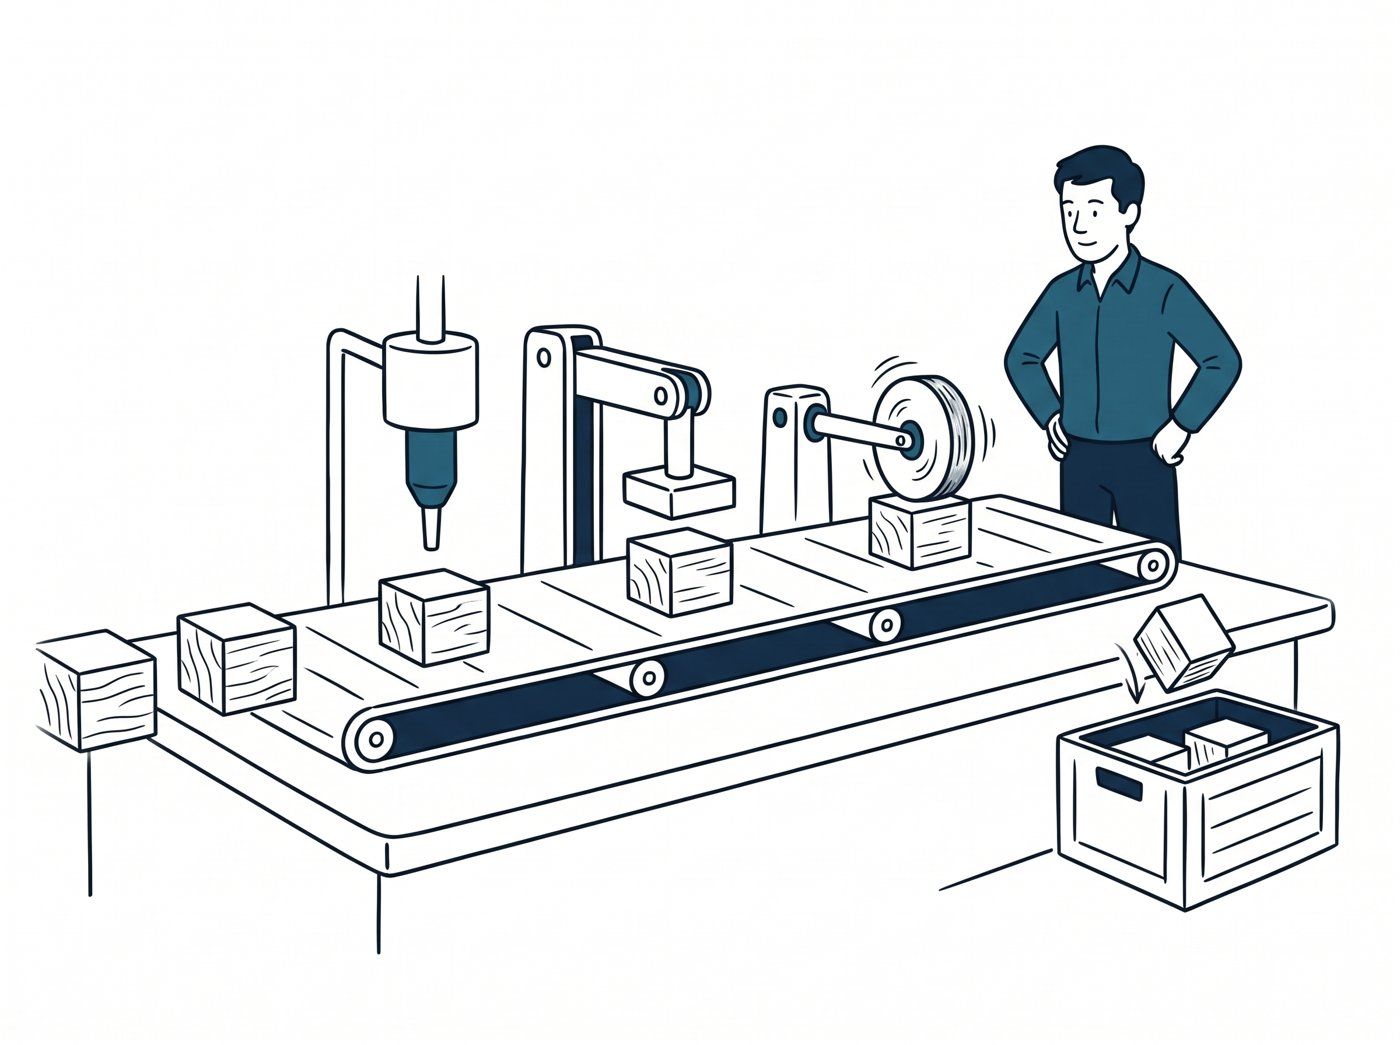<div style="text-align:center; color:#475569; font-size:0.92em; line-height:1.4; margin:-4px auto 14px; max-width:70%;">Eine Pipeline ist das Fließband: Jedes Werkstück durchläuft dieselben Stationen in derselben Reihenfolge, und keine Station wird von Hand bedient. `fit` richtet die Stationen einmal ein, `transform` lässt die Werkstücke durchlaufen.</div></div>

Die vier Zahlenspalten brauchen beide Schritte nacheinander: erst den Imputer, dann den Skalierer. Eine `Pipeline` hängt Transformer in dieser Reihenfolge aneinander und verhält sich nach außen selbst wie ein Transformer. Angelegt wird sie mit einer Liste von Tupeln. Jedes Tupel besteht aus einem Namen, den Sie frei wählen, und dem Objekt. Was die Pipeline bei den einzelnen Aufrufen genau tut, zeigt das Beispiel `num_pipe`:

- `num_pipe.fit(X)` ruft `fit_transform` des Imputers, gibt das gefüllte Ergebnis an den Skalierer und ruft dort nur `fit`. Der Imputer muss sein Ergebnis weitergeben, weil der Skalierer seine Parameter in unserer Pipeline aus den bereits gefüllten Trainingsdaten bestimmen soll. Der Skalierer ist der letzte Schritt, nach ihm kommt niemand mehr, der sein Ergebnis bräuchte. Deshalb lernt er bei `fit` nur und spart sich das Umformen. Das Gleiche gilt für jede Pipeline: Jeder Schritt vor dem letzten wird bei `fit` gefittet und transformiert, mit `fit_transform`, wenn der Schritt diese Methode hat, sonst mit `fit` und danach `transform`. Den letzten Schritt ruft die Pipeline nur mit `fit` auf. Hängt später ein Modell am Ende, lernt es bei `fit` aus dem Ergebnis der Vorverarbeitung und gibt selbst nichts weiter.
- `num_pipe.transform(X)` ruft `transform` beider Schritte nacheinander, erst füllen, dann skalieren.
- `num_pipe.fit_transform(X)` tut beides und liefert das vollständig umgeformte Ergebnis.

Die nächste Zelle legt `num_pipe` an, fittet sie auf den Trainingsteil und wendet sie auf beide Teile an.

In [ ]:
num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler())])
num_pipe.fit(X_train[num_cols])                        # lernt beide Schritte nacheinander, nur aus dem Trainingsteil
num_train = num_pipe.transform(X_train[num_cols])
num_test = num_pipe.transform(X_test[num_cols])
print(num_train.shape, num_test.shape)
print("Lücken danach:", int(np.isnan(num_train).sum()), int(np.isnan(num_test).sum()))
print("gelernte Mediane:", num_pipe["impute"].statistics_)
print("gelernte Mittelwerte:", num_pipe["scale"].mean_.round(3))
# Formen: X_train[num_cols] (1047, 4) -> num_train (1047, 4)
#         X_test[num_cols] (262, 4) -> num_test (262, 4)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">Pipeline([...])</code> nimmt eine Liste von Tupeln <code style="color:inherit;">(name, objekt)</code>. Die Namen dienen später dem Zugriff auf einzelne Schritte</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">num_pipe <span style="color: #666">=</span> Pipeline([(<span style="color: #BA2121">"impute"</span>, SimpleImputer(strategy<span style="color: #666">=</span><span style="color: #BA2121">"median"</span>)),
                     (<span style="color: #BA2121">"scale"</span>, StandardScaler())])
num_pipe<span style="color: #666">.</span>fit(X_train[num_cols])                        <span style="color: #3D7B7B; font-style: italic"># lernt beide Schritte nacheinander, nur aus dem Trainingsteil</span>
num_train <span style="color: #666">=</span> num_pipe<span style="color: #666">.</span>transform(X_train[num_cols])
num_test <span style="color: #666">=</span> num_pipe<span style="color: #666">.</span>transform(X_test[num_cols])
<span style="color: #008000">print</span>(num_train<span style="color: #666">.</span>shape, num_test<span style="color: #666">.</span>shape)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Lücken danach:"</span>, <span style="color: #008000">int</span>(np<span style="color: #666">.</span>isnan(num_train)<span style="color: #666">.</span>sum()), <span style="color: #008000">int</span>(np<span style="color: #666">.</span>isnan(num_test)<span style="color: #666">.</span>sum()))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">num_pipe[&quot;impute&quot;]</code> holt den Schritt über seinen Namen. Die gelernten Werte stehen in dem Objekt, das in der Pipeline steckt</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"gelernte Mediane:"</span>, num_pipe[<span style="color: #BA2121">"impute"</span>]<span style="color: #666">.</span>statistics_)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"gelernte Mittelwerte:"</span>, num_pipe[<span style="color: #BA2121">"scale"</span>]<span style="color: #666">.</span>mean_<span style="color: #666">.</span>round(<span style="color: #666">3</span>))
<span style="color: #3D7B7B; font-style: italic"># Formen: X_train[num_cols] (1047, 4) -&gt; num_train (1047, 4)</span>
<span style="color: #3D7B7B; font-style: italic">#         X_test[num_cols] (262, 4) -&gt; num_test (262, 4)</span></code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 5.3 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>In der nächsten Zelle fehlen der zweite Schritt der Pipeline <code style="color:inherit;">num_pipe_2</code> und die zwei Aufrufe von <code style="color:inherit;">transform</code>. Ergänzen Sie <code style="color:inherit;">second_step</code> als Tupel aus Name und Skalierer und wenden Sie die Pipeline nach dem <code style="color:inherit;">fit</code> auf <code style="color:inherit;">X_train[num_cols]</code> und <code style="color:inherit;">X_test[num_cols]</code> an. Die Prüfzelle kontrolliert die Formen und stellt sicher, dass keine Lücke übrig ist und beide Ergebnisse denen von <code style="color:inherit;">num_pipe</code> entsprechen. Solange <code style="color:inherit;">second_step</code> noch der Platzhalter <code style="color:inherit;">...</code> ist, bricht schon das <code style="color:inherit;">fit</code> mit einer Meldung zu <code style="color:inherit;">ellipsis</code> ab. Das ist kein Fehler in Ihrem Code, sondern der Platzhalter.</p>

</div>
</div>

In [ ]:
second_step = ...   # der zweite Schritt als Tupel (Name, Objekt)
num_pipe_2 = Pipeline([("impute", SimpleImputer(strategy="median")), second_step])
num_pipe_2.fit(X_train[num_cols])
num_train_2 = ...   # Trainingsteil umformen
num_test_2 = ...    # Testteil umformen

In [ ]:
# Prüfzelle — einfach ausführen
assert not isinstance(second_step, type(...)), "second_step ist noch der Platzhalter ..."
# `steps` ist die Liste der Tupel, mit der die Pipeline angelegt wurde; `steps[1][1]` ist das Objekt des zweiten Schritts
assert len(num_pipe_2.steps) == 2 and isinstance(num_pipe_2.steps[1][1], StandardScaler), "der zweite Schritt soll ein StandardScaler sein"
assert num_train_2.shape == (1047, 4) and num_test_2.shape == (262, 4), "vier Spalten, 1047 und 262 Zeilen"
assert not np.isnan(num_train_2).any() and not np.isnan(num_test_2).any(), "nach dem Imputer gibt es keine Lücke mehr"
assert np.allclose(num_train_2, num_train), "der Trainingsteil soll dem Ergebnis von num_pipe entsprechen"
assert np.allclose(num_test_2, num_test), "der Testteil soll mit den Werten des Trainingsteils umgeformt werden (transform, nicht fit_transform)"
print("erste Zeile des Trainingsteils, umgeformt:", num_train_2[0].round(3))
print("Alle Prüfungen bestanden ✓")

Jetzt schreiben Sie selbst einen Transformer. Er soll das tun, was `SimpleImputer(strategy="median")` tut, und er soll in `num_pipe` an dessen Stelle passen. Dafür braucht er nur die zwei Methoden aus der Definition. Eine Basisklasse, also eine Klasse, von der er Methoden übernimmt, braucht er nicht. Auf Basisklassen kommen wir im Kapitel <a href="#kap-dataset-und-dataloader-batches-auf-abruf">5.6</a> zurück. Für die Lösung brauchen Sie zwei NumPy-Funktionen: `np.nanmedian(a, axis=0)` berechnet den Median je Spalte und lässt dabei `NaN` aus, und `np.where(maske, a, b)` wählt je Eintrag aus `a`, wo die Maske wahr ist, sonst aus `b`.

In [ ]:
demo = np.array([[1.0, 10.0], [np.nan, 20.0], [3.0, np.nan]])
print("Median je Spalte ohne NaN:", np.nanmedian(demo, axis=0))
print(np.where(np.isnan(demo), [2.0, 15.0], demo))     # wo demo NaN ist, der Wert aus der Liste, sonst demo selbst

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">7 min</span>✏️ Aufgabe 5.3 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Vervollständigen Sie die Klasse <code style="color:inherit;">MedianImputer</code>. Der Klassenkopf, die beiden Signaturen, die Docstrings und <code style="color:inherit;">return self</code> sind vorgegeben, zwei Zeilen fehlen: In <code style="color:inherit;">fit</code> berechnen Sie mit <code style="color:inherit;">np.nanmedian</code> den Median je Spalte und speichern ihn in <code style="color:inherit;">self.medians_</code>. In <code style="color:inherit;">transform</code> ersetzen Sie mit <code style="color:inherit;">np.where</code> jede Lücke durch den gelernten Median ihrer Spalte und geben das Array zurück. Die Klasse soll Zahlenspalten verarbeiten, in denen je Spalte mindestens ein Wert vorhanden ist. Mehr muss sie nicht können. Die Prüfzelle arbeitet mit winzigen Trainings- und Testdaten, die sich absichtlich unterscheiden, und setzt die Klasse danach in eine Pipeline ein.</p>
<p>Wer früher fertig ist: Ergänzen Sie in einer neuen Zelle eine Fassung <code style="color:inherit;">MeanImputer</code>, die mit <code style="color:inherit;">np.nanmean</code> den Mittelwert verwendet, und vergleichen Sie an <code style="color:inherit;">small[["age"]]</code>, welche Werte beide Klassen einsetzen.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> <code style="color:inherit;">np.asarray(X, dtype=float)</code> am Anfang beider Methoden macht aus einer Tabelle ein Array, <code style="color:inherit;">np.isnan(X)</code> ist dann die Maske der Lücken, <code style="color:inherit;">self.medians_</code> hat je Spalte einen Wert, und <code style="color:inherit;">np.where</code> verteilt ihn über Broadcasting auf alle Zeilen. Verändern Sie <code style="color:inherit;">X</code> nicht direkt. Das Array aus <code style="color:inherit;">np.asarray</code> kann unter Copy-on-Write eine schreibgeschützte Sicht auf die Tabelle sein. <code style="color:inherit;">np.where</code> liefert dagegen ein neues Array.</p></div></details>
</div>
</div>

In [ ]:
class MedianImputer:
    """Füllt Lücken in Zahlenspalten mit dem Median, den fit aus den Trainingsdaten gelernt hat."""

    def fit(self, X, y=None):
        """Lernt je Spalte den Median der vorhandenen Werte und gibt das Objekt zurück."""
        X = np.asarray(X, dtype=float)
        self.medians_ = ...   # Median je Spalte, NaN ausgelassen
        return self

    def transform(self, X):
        """Ersetzt jede Lücke durch den gelernten Median ihrer Spalte und gibt ein Array zurück."""
        X = np.asarray(X, dtype=float)
        filled = ...   # Lücke wird Median, sonst der Wert
        return filled

In [ ]:
# Prüfzelle — einfach ausführen
tiny_train = pd.DataFrame({"age": [10.0, np.nan, 30.0], "fare": [1.0, 2.0, np.nan]})   # Mediane 20 und 1.5
tiny_test = pd.DataFrame({"age": [np.nan, 100.0], "fare": [np.nan, 100.0]})           # andere Werte, andere Mediane
mi = MedianImputer()
assert not hasattr(mi, "medians_"), "vor fit gibt es noch kein medians_"
assert mi.fit(tiny_train) is mi, "fit soll das Objekt selbst zurückgeben"
assert isinstance(mi.medians_, np.ndarray) and mi.medians_.shape == (2,), "medians_ soll ein Array mit einem Median je Spalte sein (np.nanmedian(X, axis=0)), kein Platzhalter und kein einzelner Wert"
assert np.allclose(mi.medians_, [20.0, 1.5]), f"medians_ soll [20.0, 1.5] sein, nicht {mi.medians_}"
out = mi.transform(tiny_test)
assert isinstance(out, np.ndarray) and out.shape == (2, 2), "transform liefert ein Array mit der Form der Eingabe"
assert np.allclose(out, [[20.0, 1.5], [100.0, 100.0]]), "Lücken im Testteil bekommen die Mediane des Trainingsteils, vorhandene Werte bleiben"
assert np.allclose(mi.medians_, [20.0, 1.5]), "transform darf medians_ nicht verändern"
assert tiny_test.isna().sum().sum() == 2, "die Eingabe bleibt unverändert"
own_pipe = Pipeline([("impute", MedianImputer()), ("scale", StandardScaler())]).fit(X_train[num_cols])
assert np.allclose(own_pipe.transform(X_test[num_cols]), num_test), "in der Pipeline soll dasselbe herauskommen wie mit SimpleImputer"
print("gelernte Mediane auf den Kursdaten:", own_pipe["impute"].medians_)
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen</span>
tiny_train <span style="color: #666">=</span> pd<span style="color: #666">.</span>DataFrame({<span style="color: #BA2121">"age"</span>: [<span style="color: #666">10.0</span>, np<span style="color: #666">.</span>nan, <span style="color: #666">30.0</span>], <span style="color: #BA2121">"fare"</span>: [<span style="color: #666">1.0</span>, <span style="color: #666">2.0</span>, np<span style="color: #666">.</span>nan]})   <span style="color: #3D7B7B; font-style: italic"># Mediane 20 und 1.5</span>
tiny_test <span style="color: #666">=</span> pd<span style="color: #666">.</span>DataFrame({<span style="color: #BA2121">"age"</span>: [np<span style="color: #666">.</span>nan, <span style="color: #666">100.0</span>], <span style="color: #BA2121">"fare"</span>: [np<span style="color: #666">.</span>nan, <span style="color: #666">100.0</span>]})           <span style="color: #3D7B7B; font-style: italic"># andere Werte, andere Mediane</span>
mi <span style="color: #666">=</span> MedianImputer()
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #008000">hasattr</span>(mi, <span style="color: #BA2121">"medians_"</span>), <span style="color: #BA2121">"vor fit gibt es noch kein medians_"</span>
<span style="color: #008000; font-weight: bold">assert</span> mi<span style="color: #666">.</span>fit(tiny_train) <span style="color: #A2F; font-weight: bold">is</span> mi, <span style="color: #BA2121">"fit soll das Objekt selbst zurückgeben"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">isinstance</span>(mi<span style="color: #666">.</span>medians_, np<span style="color: #666">.</span>ndarray) <span style="color: #A2F; font-weight: bold">and</span> mi<span style="color: #666">.</span>medians_<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">2</span>,), <span style="color: #BA2121">"medians_ soll ein Array mit einem Median je Spalte sein (np.nanmedian(X, axis=0)), kein Platzhalter und kein einzelner Wert"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(mi<span style="color: #666">.</span>medians_, [<span style="color: #666">20.0</span>, <span style="color: #666">1.5</span>]), <span style="color: #BA2121">f"medians_ soll [20.0, 1.5] sein, nicht </span><span style="color: #A45A77; font-weight: bold">{</span>mi<span style="color: #666">.</span>medians_<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
out <span style="color: #666">=</span> mi<span style="color: #666">.</span>transform(tiny_test)
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">isinstance</span>(out, np<span style="color: #666">.</span>ndarray) <span style="color: #A2F; font-weight: bold">and</span> out<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">2</span>, <span style="color: #666">2</span>), <span style="color: #BA2121">"transform liefert ein Array mit der Form der Eingabe"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(out, [[<span style="color: #666">20.0</span>, <span style="color: #666">1.5</span>], [<span style="color: #666">100.0</span>, <span style="color: #666">100.0</span>]]), <span style="color: #BA2121">"Lücken im Testteil bekommen die Mediane des Trainingsteils, vorhandene Werte bleiben"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(mi<span style="color: #666">.</span>medians_, [<span style="color: #666">20.0</span>, <span style="color: #666">1.5</span>]), <span style="color: #BA2121">"transform darf medians_ nicht verändern"</span>
<span style="color: #008000; font-weight: bold">assert</span> tiny_test<span style="color: #666">.</span>isna()<span style="color: #666">.</span>sum()<span style="color: #666">.</span>sum() <span style="color: #666">==</span> <span style="color: #666">2</span>, <span style="color: #BA2121">"die Eingabe bleibt unverändert"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; die Klasse ersetzt SimpleImputer in einer Pipeline. Dass das geht, liegt nur an ihren zwei Methoden. Ein <code style="color:inherit;">fit_transform</code> hat sie nicht, die Pipeline ruft dann <code style="color:inherit;">fit</code> und danach <code style="color:inherit;">transform</code></div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">own_pipe <span style="color: #666">=</span> Pipeline([(<span style="color: #BA2121">"impute"</span>, MedianImputer()), (<span style="color: #BA2121">"scale"</span>, StandardScaler())])<span style="color: #666">.</span>fit(X_train[num_cols])
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(own_pipe<span style="color: #666">.</span>transform(X_test[num_cols]), num_test), <span style="color: #BA2121">"in der Pipeline soll dasselbe herauskommen wie mit SimpleImputer"</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"gelernte Mediane auf den Kursdaten:"</span>, own_pipe[<span style="color: #BA2121">"impute"</span>]<span style="color: #666">.</span>medians_)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Alle Prüfungen bestanden ✓"</span>)</code></pre></details>

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung MedianImputer</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">class MedianImputer:&#10;    &quot;&quot;&quot;Füllt Lücken in Zahlenspalten mit dem Median, den fit aus den Trainingsdaten gelernt hat.&quot;&quot;&quot;&#10;&#10;    def fit(self, X, y=None):&#10;        &quot;&quot;&quot;Lernt je Spalte den Median der vorhandenen Werte und gibt das Objekt zurück.&quot;&quot;&quot;&#10;        self.medians_ = np.nanmedian(np.asarray(X, dtype=float), axis=0)&#10;        return self&#10;&#10;    def transform(self, X):&#10;        &quot;&quot;&quot;Ersetzt jede Lücke durch den gelernten Median ihrer Spalte und gibt ein Array zurück.&quot;&quot;&quot;&#10;        X = np.asarray(X, dtype=float)&#10;        return np.where(np.isnan(X), self.medians_, X)</pre></details>

Die Klasse läuft in der Pipeline, weil `fit` und `transform` passen. Sie hat aber eine Grenze: Ein `ColumnTransformer`, den Sie gleich kennenlernen, und eine `Pipeline` mit eingeschaltetem Zwischenspeicher (`memory=`) legen von ihren Transformern Kopien an, bevor sie sie fitten. Zum Kopieren brauchen sie die Methode `get_params`, und die hat `MedianImputer` nicht. Die nächste Zelle zeigt das.

In [ ]:
try:
    ColumnTransformer([("num", MedianImputer(), num_cols)]).fit(X_train)
except TypeError as e:
    print(type(e).__name__ + ":", str(e)[:60], "…")

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Die Bibliotheksfassung eines eigenen Transformers</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>scikit-learn stellt zwei Basisklassen bereit, die einem eigenen Transformer liefern, was die zwei Methoden allein nicht abdecken: <code style="color:inherit;">TransformerMixin</code> ergänzt <code style="color:inherit;">fit_transform</code>, <code style="color:inherit;">BaseEstimator</code> die Parameterverwaltung mit <code style="color:inherit;">get_params</code> und <code style="color:inherit;">set_params</code>, die das Kopieren braucht. Mit <code style="color:inherit;">class MedianImputer(TransformerMixin, BaseEstimator)</code> läuft die Klasse auch im <code style="color:inherit;">ColumnTransformer</code>.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Das Muster „die eigene Klasse übernimmt die Verwaltung von einer Basisklasse und schreibt nur die fachlichen Methoden selbst“ kommt im Kurs wieder: in Grundkurs Teil 4 beim Lehrmodell von <code style="color:inherit;">nn.Module</code> und in der nächsten Lerneinheit bei PyTorch selbst. Die Reihenfolge der beiden Basisklassen ist in scikit-learn Konvention: erst die Mixins, dann <code style="color:inherit;">BaseEstimator</code>. Die nächste Zelle zeigt diese Fassung. Die fachlichen Zeilen sind dieselben wie in Ihrer eigenen Klasse.</p></div></details>
</div>
</div>

In [ ]:
# Zur Vertiefung: die Bibliotheksfassung
from sklearn.base import TransformerMixin, BaseEstimator

class MedianImputerSk(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        self.medians_ = np.nanmedian(np.asarray(X, dtype=float), axis=0)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.where(np.isnan(X), self.medians_, X)

sk_ct = ColumnTransformer([("num", MedianImputerSk(), num_cols)]).fit(X_train)
print("im ColumnTransformer:", sk_ct.transform(X_test).shape, "| fit_transform vorhanden:", hasattr(MedianImputerSk(), "fit_transform"))

Der kategoriale Zweig folgt demselben Muster wie `num_pipe`: erst ein Imputer, der mit dem häufigsten Wert füllt, dann der Encoder mit `handle_unknown="ignore"`. Aus den drei Spalten `sex`, `embarked` und `pclass` werden 2 + 3 + 3 = 8 Spalten aus Nullen und Einsen. In den hier gezeigten Daten stehen in jeder Zeile genau drei Einsen, eine für jede der drei ursprünglichen Spalten, weil alle Werte dem Encoder bekannt sind.

In [ ]:
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
cat_pipe.fit(X_train[cat_cols])
cat_test = cat_pipe.transform(X_test[cat_cols])
print(cat_test.shape, "| Einsen je Zeile:", np.unique(cat_test.sum(axis=1)))
print("Kategorien:", [list(c) for c in cat_pipe["onehot"].categories_])
# Formen: X_test[cat_cols] (262, 3) -> cat_test (262, 8)

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Wie viele Spalten entstehen aus den sieben Spalten in <code style="color:inherit;">num_cols</code> und <code style="color:inherit;">cat_cols</code> zusammen?</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 5.3 #3</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Was kommt heraus? Die nächste Zelle wendet <code style="color:inherit;">cat_pipe</code> auf <code style="color:inherit;">small</code> an und enthält dazu vier Codezeilen. Schreiben Sie Ihre Vorhersage hinter das <code style="color:inherit;"># -&gt;</code>, führen Sie die Zelle aus und vergleichen Sie.</p>

</div>
</div>

In [ ]:
cat_small = cat_pipe.transform(small[cat_cols])
print(cat_small.shape)         # -> ?
print(cat_small.sum(axis=1))   # -> ?
print(cat_small[5])            # -> ?
print(cat_small[0, :2])        # -> ?

Beide Zweige liegen jetzt als fertige Bausteine vor. Der `ColumnTransformer` setzt sie zusammen. Auch er bekommt eine Liste von Tupeln, nur mit drei Einträgen: ein Name, das Objekt und die Liste der Spalten, die das Objekt bekommt. Er verarbeitet die Spaltengruppen getrennt und setzt die Ergebnisse nebeneinander. Die Pipeline dagegen verarbeitet Schritte nacheinander. Spalten, die in keiner Liste stehen, fallen weg (`remainder="drop"` ist der Standard). Deshalb können Sie dem `ColumnTransformer` auch eine Tabelle mit zusätzlichen Spalten übergeben.

In [ ]:
preprocessor = ColumnTransformer([("num", num_pipe, num_cols),
                                  ("cat", cat_pipe, cat_cols)])
preprocessor.fit(X_train)                                  # beide Zweige lernen aus dem Trainingsteil
X_train_num = preprocessor.transform(X_train)
X_test_num = preprocessor.transform(X_test)
print(X_train_num.shape, X_test_num.shape, X_train_num.dtype, "| Lücken:", int(np.isnan(X_train_num).sum()))
print(list(preprocessor.get_feature_names_out()))
# Formen: X_train (1047, 7) -> X_train_num (1047, 12);  X_test (262, 7) -> X_test_num (262, 12)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; die Tupel haben hier drei Einträge: <code style="color:inherit;">(name, objekt, spaltenliste)</code>. Jedes Objekt sieht nur seine Spalten</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">preprocessor <span style="color: #666">=</span> ColumnTransformer([(<span style="color: #BA2121">"num"</span>, num_pipe, num_cols),
                                  (<span style="color: #BA2121">"cat"</span>, cat_pipe, cat_cols)])
preprocessor<span style="color: #666">.</span>fit(X_train)                                  <span style="color: #3D7B7B; font-style: italic"># beide Zweige lernen aus dem Trainingsteil</span>
X_train_num <span style="color: #666">=</span> preprocessor<span style="color: #666">.</span>transform(X_train)
X_test_num <span style="color: #666">=</span> preprocessor<span style="color: #666">.</span>transform(X_test)
<span style="color: #008000">print</span>(X_train_num<span style="color: #666">.</span>shape, X_test_num<span style="color: #666">.</span>shape, X_train_num<span style="color: #666">.</span>dtype, <span style="color: #BA2121">"| Lücken:"</span>, <span style="color: #008000">int</span>(np<span style="color: #666">.</span>isnan(X_train_num)<span style="color: #666">.</span>sum()))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">get_feature_names_out()</code> nennt die Spalten des Ergebnisses: Zweigname, zwei Unterstriche, Spaltenname, bei Kategorien noch der Wert</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #008000">list</span>(preprocessor<span style="color: #666">.</span>get_feature_names_out()))
<span style="color: #3D7B7B; font-style: italic"># Formen: X_train (1047, 7) -&gt; X_train_num (1047, 12);  X_test (262, 7) -&gt; X_test_num (262, 12)</span></code></pre></details>

Die Grafik zeigt die beiden Zweige. Oben gehen die vier Zahlenspalten durch `num_pipe` und bleiben vier Spalten, unten gehen die drei Kategorien durch `cat_pipe` und werden acht Spalten. Rechts setzt der `ColumnTransformer` beides nebeneinander zu zwölf Spalten zusammen. Die Zahlen an den Pfeilen sind die Spaltenzahlen.

Im Array gehen die Spaltennamen verloren. `get_feature_names_out()` liefert sie nach. Wie das Ergebnis als Tabelle aussieht, zeigt eine Demo nach der nächsten Aufgabe.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">7 min</span>✏️ Aufgabe 5.3 #4</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie <code style="color:inherit;">make_preprocessor(num_cols, cat_cols)</code>. Die Funktion baut aus den zwei Spaltenlisten den <code style="color:inherit;">ColumnTransformer</code> mit den beiden Zweigen aus diesem Kapitel und gibt ihn zurück, noch nicht gefittet. Nach einem <code style="color:inherit;">fit</code> auf <code style="color:inherit;">X_train</code> sollen zwölf Zahlenspalten ohne Lücken entstehen, die vier skalierten zuerst. Die Prüfzelle kontrolliert außerdem, wie unbekannte Werte kodiert werden, ob bei winzigen Testdaten die gelernten Werte des Trainingsteils verwendet werden und ob die Funktion auch mit anderen Spaltenlisten arbeitet. Spätere Zellen bauen auf der Funktion auf.</p>
<p>Wer früher fertig ist: Rufen Sie in einer neuen Zelle <code style="color:inherit;">make_preprocessor(["age", "fare"], ["sex"])</code> auf, sagen Sie vorher, wie viele Spalten nach dem <code style="color:inherit;">fit</code> auf <code style="color:inherit;">X_train</code> entstehen, und prüfen Sie es mit <code style="color:inherit;">get_feature_names_out()</code>.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Die Zelle mit <code style="color:inherit;">num_pipe</code>, die Zelle mit <code style="color:inherit;">cat_pipe</code> und die Zelle mit <code style="color:inherit;">preprocessor</code> enthalten zusammen alle Zeilen, die die Funktion braucht. Legen Sie beide Pipelines in der Funktion neu an, damit jeder Aufruf frische Objekte liefert.</p></div></details>
</div>
</div>

In [ ]:
def make_preprocessor(num_cols, cat_cols):
    """Baut den ColumnTransformer: Zahlenspalten füllen und skalieren, Kategorien füllen und one-hot kodieren."""
    num_pipe = ...   # Zahlen
    cat_pipe = ...   # Kategorien
    prep = ...       # zwei Zweige
    return prep

In [ ]:
# Prüfzelle — einfach ausführen
prep = make_preprocessor(num_cols, cat_cols)
assert prep is not None, "make_preprocessor gibt noch nichts zurück (return vergessen?)"
assert prep is not ..., "make_preprocessor gibt noch den Platzhalter ... zurück"
assert isinstance(prep, ColumnTransformer), "das Ergebnis soll ein ColumnTransformer sein"
assert not hasattr(prep, "transformers_"), "die Funktion gibt den ColumnTransformer ungefittet zurück; fit kommt später"
prep.fit(X_train)
out = prep.transform(X_train)
assert out.shape == (1047, 12), f"Form (1047, 12) erwartet, nicht {out.shape}"
assert not np.isnan(out).any(), "nach der Vorverarbeitung darf keine Lücke übrig sein (Imputer in beiden Zweigen)"
expected_names = ["num__age", "num__sibsp", "num__parch", "num__fare", "cat__sex_female", "cat__sex_male",
                  "cat__embarked_C", "cat__embarked_Q", "cat__embarked_S", "cat__pclass_1", "cat__pclass_2", "cat__pclass_3"]
assert list(prep.get_feature_names_out()) == expected_names, "Zweig num mit den vier Zahlenspalten zuerst, dann Zweig cat"
assert np.allclose(out[:, :4].mean(axis=0), 0, atol=1e-9) and np.allclose(out[:, :4].std(axis=0), 1), "die vier Zahlenspalten sind skaliert (Mittelwert 0, Streuung 1 im Trainingsteil)"
assert np.allclose(prep.transform(X_test), X_test_num), "auf dem Testteil soll dasselbe herauskommen wie mit preprocessor"
odd = X_test.iloc[[0]].copy(); odd["embarked"] = "X"
row = prep.transform(odd)[0]
assert np.allclose(row[6:9], 0) and row[4:6].sum() == 1 and row[9:12].sum() == 1, "handle_unknown='ignore': nur der Hafenblock wird null"
tiny_train = pd.DataFrame({"age": [10.0, np.nan, 30.0], "sibsp": [0, 0, 0], "parch": [0, 0, 0], "fare": [1.0, 2.0, np.nan],
                           "sex": ["female", "male", "male"], "embarked": ["S", "S", "C"], "pclass": [1, 2, 3]})
tiny_test = pd.DataFrame({"age": [np.nan], "sibsp": [0], "parch": [0], "fare": [np.nan], "sex": ["female"], "embarked": [np.nan], "pclass": [2]})
tiny_prep = make_preprocessor(num_cols, cat_cols).fit(tiny_train)
tiny_out = tiny_prep.transform(tiny_test)[0]
assert np.isclose(tiny_out[0], 0.0) and np.isclose(tiny_out[3], 0.0), "age und fare bekommen die Mediane 20 und 1.5 des Trainingsteils, die skaliert genau 0 ergeben"
assert tiny_out[4] == 1 and tiny_out[7] == 1, "sex female und embarked S (häufigster Hafen des Trainingsteils; Spalten C, S) sind kodiert"
small_prep = make_preprocessor(["age"], ["sex"]).fit(X_train)
assert small_prep.transform(X_test).shape == (262, 3), "mit ['age'] und ['sex'] entstehen 1 + 2 = 3 Spalten"
print("Spaltennamen:", list(prep.get_feature_names_out())[:5], "…")
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen</span>
prep <span style="color: #666">=</span> make_preprocessor(num_cols, cat_cols)
<span style="color: #008000; font-weight: bold">assert</span> prep <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #008000; font-weight: bold">None</span>, <span style="color: #BA2121">"make_preprocessor gibt noch nichts zurück (return vergessen?)"</span>
<span style="color: #008000; font-weight: bold">assert</span> prep <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #666">...</span>, <span style="color: #BA2121">"make_preprocessor gibt noch den Platzhalter ... zurück"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">isinstance</span>(prep, ColumnTransformer), <span style="color: #BA2121">"das Ergebnis soll ein ColumnTransformer sein"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #008000">hasattr</span>(prep, <span style="color: #BA2121">"transformers_"</span>), <span style="color: #BA2121">"die Funktion gibt den ColumnTransformer ungefittet zurück; fit kommt später"</span>
prep<span style="color: #666">.</span>fit(X_train)
out <span style="color: #666">=</span> prep<span style="color: #666">.</span>transform(X_train)
<span style="color: #008000; font-weight: bold">assert</span> out<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">1047</span>, <span style="color: #666">12</span>), <span style="color: #BA2121">f"Form (1047, 12) erwartet, nicht </span><span style="color: #A45A77; font-weight: bold">{</span>out<span style="color: #666">.</span>shape<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #A2F; font-weight: bold">not</span> np<span style="color: #666">.</span>isnan(out)<span style="color: #666">.</span>any(), <span style="color: #BA2121">"nach der Vorverarbeitung darf keine Lücke übrig sein (Imputer in beiden Zweigen)"</span>
expected_names <span style="color: #666">=</span> [<span style="color: #BA2121">"num__age"</span>, <span style="color: #BA2121">"num__sibsp"</span>, <span style="color: #BA2121">"num__parch"</span>, <span style="color: #BA2121">"num__fare"</span>, <span style="color: #BA2121">"cat__sex_female"</span>, <span style="color: #BA2121">"cat__sex_male"</span>,
                  <span style="color: #BA2121">"cat__embarked_C"</span>, <span style="color: #BA2121">"cat__embarked_Q"</span>, <span style="color: #BA2121">"cat__embarked_S"</span>, <span style="color: #BA2121">"cat__pclass_1"</span>, <span style="color: #BA2121">"cat__pclass_2"</span>, <span style="color: #BA2121">"cat__pclass_3"</span>]
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">list</span>(prep<span style="color: #666">.</span>get_feature_names_out()) <span style="color: #666">==</span> expected_names, <span style="color: #BA2121">"Zweig num mit den vier Zahlenspalten zuerst, dann Zweig cat"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(out[:, :<span style="color: #666">4</span>]<span style="color: #666">.</span>mean(axis<span style="color: #666">=0</span>), <span style="color: #666">0</span>, atol<span style="color: #666">=1e-9</span>) <span style="color: #A2F; font-weight: bold">and</span> np<span style="color: #666">.</span>allclose(out[:, :<span style="color: #666">4</span>]<span style="color: #666">.</span>std(axis<span style="color: #666">=0</span>), <span style="color: #666">1</span>), <span style="color: #BA2121">"die vier Zahlenspalten sind skaliert (Mittelwert 0, Streuung 1 im Trainingsteil)"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(prep<span style="color: #666">.</span>transform(X_test), X_test_num), <span style="color: #BA2121">"auf dem Testteil soll dasselbe herauskommen wie mit preprocessor"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; eine Zeile mit unbekanntem Hafen: Nullen im Hafenblock (Spalten 6 bis 8), der Rest der Zeile bleibt</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">odd <span style="color: #666">=</span> X_test<span style="color: #666">.</span>iloc[[<span style="color: #666">0</span>]]<span style="color: #666">.</span>copy(); odd[<span style="color: #BA2121">"embarked"</span>] <span style="color: #666">=</span> <span style="color: #BA2121">"X"</span>
row <span style="color: #666">=</span> prep<span style="color: #666">.</span>transform(odd)[<span style="color: #666">0</span>]
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(row[<span style="color: #666">6</span>:<span style="color: #666">9</span>], <span style="color: #666">0</span>) <span style="color: #A2F; font-weight: bold">and</span> row[<span style="color: #666">4</span>:<span style="color: #666">6</span>]<span style="color: #666">.</span>sum() <span style="color: #666">==</span> <span style="color: #666">1</span> <span style="color: #A2F; font-weight: bold">and</span> row[<span style="color: #666">9</span>:<span style="color: #666">12</span>]<span style="color: #666">.</span>sum() <span style="color: #666">==</span> <span style="color: #666">1</span>, <span style="color: #BA2121">"handle_unknown='ignore': nur der Hafenblock wird null"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; winzige Daten: der Testteil wird mit den gelernten Werten des Trainingsteils umgeformt</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">tiny_train <span style="color: #666">=</span> pd<span style="color: #666">.</span>DataFrame({<span style="color: #BA2121">"age"</span>: [<span style="color: #666">10.0</span>, np<span style="color: #666">.</span>nan, <span style="color: #666">30.0</span>], <span style="color: #BA2121">"sibsp"</span>: [<span style="color: #666">0</span>, <span style="color: #666">0</span>, <span style="color: #666">0</span>], <span style="color: #BA2121">"parch"</span>: [<span style="color: #666">0</span>, <span style="color: #666">0</span>, <span style="color: #666">0</span>], <span style="color: #BA2121">"fare"</span>: [<span style="color: #666">1.0</span>, <span style="color: #666">2.0</span>, np<span style="color: #666">.</span>nan],
                           <span style="color: #BA2121">"sex"</span>: [<span style="color: #BA2121">"female"</span>, <span style="color: #BA2121">"male"</span>, <span style="color: #BA2121">"male"</span>], <span style="color: #BA2121">"embarked"</span>: [<span style="color: #BA2121">"S"</span>, <span style="color: #BA2121">"S"</span>, <span style="color: #BA2121">"C"</span>], <span style="color: #BA2121">"pclass"</span>: [<span style="color: #666">1</span>, <span style="color: #666">2</span>, <span style="color: #666">3</span>]})
tiny_test <span style="color: #666">=</span> pd<span style="color: #666">.</span>DataFrame({<span style="color: #BA2121">"age"</span>: [np<span style="color: #666">.</span>nan], <span style="color: #BA2121">"sibsp"</span>: [<span style="color: #666">0</span>], <span style="color: #BA2121">"parch"</span>: [<span style="color: #666">0</span>], <span style="color: #BA2121">"fare"</span>: [np<span style="color: #666">.</span>nan], <span style="color: #BA2121">"sex"</span>: [<span style="color: #BA2121">"female"</span>], <span style="color: #BA2121">"embarked"</span>: [np<span style="color: #666">.</span>nan], <span style="color: #BA2121">"pclass"</span>: [<span style="color: #666">2</span>]})
tiny_prep <span style="color: #666">=</span> make_preprocessor(num_cols, cat_cols)<span style="color: #666">.</span>fit(tiny_train)
tiny_out <span style="color: #666">=</span> tiny_prep<span style="color: #666">.</span>transform(tiny_test)[<span style="color: #666">0</span>]
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>isclose(tiny_out[<span style="color: #666">0</span>], <span style="color: #666">0.0</span>) <span style="color: #A2F; font-weight: bold">and</span> np<span style="color: #666">.</span>isclose(tiny_out[<span style="color: #666">3</span>], <span style="color: #666">0.0</span>), <span style="color: #BA2121">"age und fare bekommen die Mediane 20 und 1.5 des Trainingsteils, die skaliert genau 0 ergeben"</span>
<span style="color: #008000; font-weight: bold">assert</span> tiny_out[<span style="color: #666">4</span>] <span style="color: #666">==</span> <span style="color: #666">1</span> <span style="color: #A2F; font-weight: bold">and</span> tiny_out[<span style="color: #666">7</span>] <span style="color: #666">==</span> <span style="color: #666">1</span>, <span style="color: #BA2121">"sex female und embarked S (häufigster Hafen des Trainingsteils; Spalten C, S) sind kodiert"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; andere Spaltenlisten: die Funktion soll mit ihren Parametern arbeiten, nicht mit den globalen Listen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">small_prep <span style="color: #666">=</span> make_preprocessor([<span style="color: #BA2121">"age"</span>], [<span style="color: #BA2121">"sex"</span>])<span style="color: #666">.</span>fit(X_train)
<span style="color: #008000; font-weight: bold">assert</span> small_prep<span style="color: #666">.</span>transform(X_test)<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">262</span>, <span style="color: #666">3</span>), <span style="color: #BA2121">"mit ['age'] und ['sex'] entstehen 1 + 2 = 3 Spalten"</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Spaltennamen:"</span>, <span style="color: #008000">list</span>(prep<span style="color: #666">.</span>get_feature_names_out())[:<span style="color: #666">5</span>], <span style="color: #BA2121">"…"</span>)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Alle Prüfungen bestanden ✓"</span>)</code></pre></details>

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung make_preprocessor</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">def make_preprocessor(num_cols, cat_cols):&#10;    &quot;&quot;&quot;Baut den ColumnTransformer: Zahlenspalten füllen und skalieren, Kategorien füllen und one-hot kodieren.&quot;&quot;&quot;&#10;    num_pipe = Pipeline([(&quot;impute&quot;, SimpleImputer(strategy=&quot;median&quot;)),&#10;                         (&quot;scale&quot;, StandardScaler())])&#10;    cat_pipe = Pipeline([(&quot;impute&quot;, SimpleImputer(strategy=&quot;most_frequent&quot;)),&#10;                         (&quot;onehot&quot;, OneHotEncoder(handle_unknown=&quot;ignore&quot;, sparse_output=False))])&#10;    return ColumnTransformer([(&quot;num&quot;, num_pipe, num_cols),&#10;                              (&quot;cat&quot;, cat_pipe, cat_cols)])</pre></details>

Wenn Sie das Ergebnis der Vorverarbeitung als Tabelle sehen wollen, stellen Sie einen `ColumnTransformer` mit `set_output(transform="pandas")` um, am besten vor dem `fit`, damit die Schritte die Spaltennamen beim Lernen kennen. Die Umstellung wirkt auf alle Schritte, die in dem Objekt stecken. Deshalb verwendet die Demo ein eigenes Objekt aus `make_preprocessor`. `preprocessor` und die Pipelines aus den Zellen oben liefern weiterhin Arrays, denn für den Weg zum Tensor im übernächsten Kapitel brauchen wir ein Array.

In [ ]:
demo_prep = make_preprocessor(num_cols, cat_cols).set_output(transform="pandas").fit(X_train)
print(demo_prep.transform(small).round(2).T)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">set_output(transform=&quot;pandas&quot;)</code> stellt das Objekt um. Es gibt das Objekt zurück, deshalb lässt sich <code style="color:inherit;">.fit(...)</code> anhängen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">demo_prep <span style="color: #666">=</span> make_preprocessor(num_cols, cat_cols)<span style="color: #666">.</span>set_output(transform<span style="color: #666">=</span><span style="color: #BA2121">"pandas"</span>)<span style="color: #666">.</span>fit(X_train)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">.T</code> zeigt die Tabelle transponiert: eine Zeile je Ergebnisspalte, eine Spalte je Passagier, damit alle zwölf Spalten lesbar sind</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(demo_prep<span style="color: #666">.</span>transform(small)<span style="color: #666">.</span>round(<span style="color: #666">2</span>)<span style="color: #666">.</span>T)</code></pre></details>

Die Ausgabe zeigt `small` nach der Vorverarbeitung, transponiert: Die zwölf Ergebnisspalten stehen als Zeilen, die sechs Passagiere als Spalten 0 bis 5. Passagier 1 hat in `num__age` den Wert minus 0,12. Das ist der gelernte Median 28 des Trainingsteils nach der Skalierung, die Lücke wurde also gefüllt. Passagier 5 hat in `cat__embarked_S` eine 1, der Imputer hat die Lücke mit dem häufigsten Hafen des Trainingsteils gefüllt. Die Etiketten 0 bis 5 bleiben erhalten, weil `set_output` eine Tabelle liefert.

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Pipeline und ColumnTransformer</span></div>
<p><code style="color:inherit;">t1</code> und <code style="color:inherit;">t2</code> stehen für Transformer, <code style="color:inherit;">cols1</code> und <code style="color:inherit;">cols2</code> für Listen von Spaltennamen, <code style="color:inherit;">pipe</code> für eine Pipeline und <code style="color:inherit;">ct</code> für einen <code style="color:inherit;">ColumnTransformer</code>. Beide Objekte haben selbst <code style="color:inherit;">fit</code>, <code style="color:inherit;">transform</code> und <code style="color:inherit;">fit_transform</code> und fitten nur auf den Daten, die sie bekommen.</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:26%"><col style="width:44%"><col style="width:30%"></colgroup>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td>Schritte nacheinander</td>
<td><code style="color:inherit;">Pipeline([("a", t1), ("b", t2)])</code></td>
<td>ein Transformer, der erst <code style="color:inherit;">t1</code>, dann <code style="color:inherit;">t2</code> anwendet</td>
</tr>
<tr>
<td>Pipeline lernen</td>
<td><code style="color:inherit;">pipe.fit(X)</code></td>
<td><code style="color:inherit;">fit_transform</code> von <code style="color:inherit;">t1</code>, dann <code style="color:inherit;">fit</code> von <code style="color:inherit;">t2</code></td>
</tr>
<tr>
<td>Pipeline anwenden</td>
<td><code style="color:inherit;">pipe.transform(X)</code></td>
<td><code style="color:inherit;">transform</code> von <code style="color:inherit;">t1</code>, dann von <code style="color:inherit;">t2</code></td>
</tr>
<tr>
<td>einen Schritt holen</td>
<td><code style="color:inherit;">pipe["a"]</code></td>
<td>das Objekt <code style="color:inherit;">t1</code> mit seinen gelernten Werten</td>
</tr>
<tr>
<td>Spaltengruppen getrennt</td>
<td><code style="color:inherit;">ColumnTransformer([("num", t1, cols1), ("cat", t2, cols2)])</code></td>
<td><code style="color:inherit;">t1</code> sieht nur <code style="color:inherit;">cols1</code>, <code style="color:inherit;">t2</code> nur <code style="color:inherit;">cols2</code>, Ergebnisse nebeneinander</td>
</tr>
<tr>
<td>Ergebnisspalten benennen</td>
<td><code style="color:inherit;">ct.get_feature_names_out()</code></td>
<td>Array der Namen, <code style="color:inherit;">num__age</code>, <code style="color:inherit;">cat__sex_female</code>, …</td>
</tr>
<tr>
<td>einen Zweig holen</td>
<td><code style="color:inherit;">ct.named_transformers_["num"]</code></td>
<td>das gefittete Objekt des Zweigs</td>
</tr>
<tr>
<td>Ergebnis als Tabelle</td>
<td><code style="color:inherit;">ct.set_output(transform="pandas")</code></td>
<td><code style="color:inherit;">transform</code> liefert einen DataFrame, am besten vor dem <code style="color:inherit;">fit</code> umstellen</td>
</tr>
</tbody>
</table>
<p>Falle: Jeder Zweig des <code style="color:inherit;">ColumnTransformer</code> bekommt eine Liste von Spaltennamen (<code style="color:inherit;">cols1</code>, <code style="color:inherit;">cols2</code>). Spalten von <code style="color:inherit;">X</code>, die in keiner dieser Listen stehen, lässt der <code style="color:inherit;">ColumnTransformer</code> weg, das ist die Vorgabe <code style="color:inherit;">remainder="drop"</code>. Mit <code style="color:inherit;">remainder="passthrough"</code> würden sie unverändert hinten angehängt. Fehlerfall: Ein Objekt ohne <code style="color:inherit;">get_params</code>, wie unsere erste Fassung von <code style="color:inherit;">MedianImputer</code>, bricht im <code style="color:inherit;">ColumnTransformer</code> mit <code style="color:inherit;">TypeError: Cannot clone object</code> ab.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Dünnbesetzte Matrizen</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Ohne <code style="color:inherit;">sparse_output=False</code> liefert <code style="color:inherit;">OneHotEncoder</code> eine dünnbesetzte Matrix (sparse matrix). Sie speichert nur die von null verschiedenen Werte und Angaben zu deren Positionen. Beispiel: Die kodierte Spalte <code style="color:inherit;">sex</code> von <code style="color:inherit;">small</code> ist ein Array <code style="color:inherit;">(6, 2)</code> mit zwölf Zahlen, davon sechs Einsen. Als dünnbesetzte Matrix werden nur die sechs Einsen mit Zeile und Spalte gespeichert, <code style="color:inherit;">print</code> zeigt sie als Liste <code style="color:inherit;">(0, 0) 1.0</code>, <code style="color:inherit;">(1, 1) 1.0</code> und so weiter. Bei acht Spalten mit drei Einsen je Zeile spart das wenig, bei einer Spalte mit tausenden Kategorien (eine Postleitzahl, ein Produktcode) sehr viel: Von tausend Spalten je Zeile ist nur eine von null verschieden.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Eine dünnbesetzte Matrix ist kein NumPy-Array: <code style="color:inherit;">np.isnan</code> und viele andere Funktionen nehmen sie nicht an, und <code style="color:inherit;">torch.from_numpy</code> auch nicht. Der <code style="color:inherit;">ColumnTransformer</code> wandelt sein Ergebnis in ein gewöhnliches Array um, wenn der Anteil der Nullen klein genug ist (Parameter <code style="color:inherit;">sparse_threshold</code>). Mit <code style="color:inherit;">sparse_output=False</code> legen wir das Ergebnisformat fest, statt uns auf diese Schwelle zu verlassen. Für zwölf Spalten spielt der Speicher keine Rolle.</p></div></details>
</div>
</div>

## <a id="kap-modell-baseline-und-metrik"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">5.4&nbsp;&nbsp;Modell, Baseline und Metrik</span>

Die Vorverarbeitung ist fertig. Jetzt hängen wir das Modell als letzten Schritt an eine `Pipeline` an. Das Modell dieser Lerneinheit ist `LogisticRegression`. Es bildet aus den zwölf Merkmalen eine gewichtete Summe plus einen Achsenabschnitt und macht daraus eine Wahrscheinlichkeit dafür, dass `survived` gleich 1 ist. Die zwölf Gewichte und den Achsenabschnitt lernt es in `fit`. Sie stehen danach in `coef_` und `intercept_`. Die Vertiefung nach der Pipeline-Zelle leitet die Rechnung aus der linearen Regression her und zeigt die gelernten Gewichte. Diese Rechnung entspricht einem neuronalen Netz ohne verborgene Schicht, und die nächste Lerneinheit baut sie in PyTorch nach. Das Training läuft dort mit anderen Verfahren und Einstellungen, deshalb kommen dort nicht dieselben Gewichte heraus.

Mit dem Modell am Ende ändert sich, was die Pipeline bei ihren Aufrufen tut. `pipe.fit(X_train, y_train)` ruft `fit_transform` der Vorverarbeitung, die ihre Werte aus `X_train` lernt, und dann `fit` des Modells, das aus den umgeformten Merkmalen und den Zielwerten `y_train` lernt. `pipe.predict(X_test)` ruft `transform` der Vorverarbeitung und dann `predict` des Modells, beides wendet nur gespeicherte Werte an. Dass alles aus dem Trainingsteil gelernt wird, liegt allein daran, dass wir `X_train` und `y_train` übergeben. Die Pipeline schützt nicht davor, dass jemand `fit` mit allen Daten aufruft oder erst nach dem Lernen in Trainings- und Testteil trennt.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E75B6; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Genau verstehen: Was LogisticRegression rechnet</div>
<div style="background:#EAF2FA; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Für eine Zeile mit den zwölf vorverarbeiteten Merkmalen <code style="color:inherit;">x1</code> bis <code style="color:inherit;">x12</code> rechnet das Modell in zwei Schritten:</p>
<ol>
<li><code style="color:inherit;">z = w1*x1 + w2*x2 + … + w12*x12 + b</code>. Die zwölf Gewichte <code style="color:inherit;">w1</code> bis <code style="color:inherit;">w12</code> stehen in <code style="color:inherit;">coef_</code>, der Achsenabschnitt <code style="color:inherit;">b</code> in <code style="color:inherit;">intercept_</code>. <code style="color:inherit;">coef_</code> hat die Form <code style="color:inherit;">(1, 12)</code>: eine Zeile, weil das Modell bei zwei Klassen eine einzige Formel für <code style="color:inherit;">z</code> lernt, und ein Gewicht je Merkmalsspalte. <code style="color:inherit;">intercept_</code> ist entsprechend ein Array mit einem Eintrag. Bei drei oder mehr Klassen hätten beide eine Zeile beziehungsweise einen Eintrag je Klasse. <code style="color:inherit;">b</code> ist der Wert von <code style="color:inherit;">z</code>, wenn alle Merkmale 0 sind, also das Grundniveau, von dem aus die Gewichte nach oben oder unten verschieben. Da die Zahlenspalten skaliert sind, bedeutet 0 dort „durchschnittlich“.</li>
<li><code style="color:inherit;">p = 1 / (1 + exp(-z))</code>, die Sigmoidfunktion. Sie bildet <code style="color:inherit;">z</code> auf den Bereich 0 bis 1 ab, <code style="color:inherit;">p</code> ist die geschätzte Wahrscheinlichkeit für Klasse 1. <code style="color:inherit;">predict_proba</code> gibt <code style="color:inherit;">1 - p</code> und <code style="color:inherit;">p</code> aus, <code style="color:inherit;">predict</code> sagt 1, wenn <code style="color:inherit;">p</code> über 0,5 liegt, und das ist genau dann der Fall, wenn <code style="color:inherit;">z</code> über 0 liegt.</li>
</ol>
<p><code style="color:inherit;">fit</code> sucht die Werte für <code style="color:inherit;">w1</code> bis <code style="color:inherit;">w12</code> und <code style="color:inherit;">b</code>, bei denen <code style="color:inherit;">p</code> zu den Klassen des Trainingsteils am besten passt. Mehr dazu, einschließlich der gelernten Gewichte, in der Vertiefung nach der nächsten Zelle.</p>

</div>
</div>

In [ ]:
pipe = Pipeline([("prep", make_preprocessor(num_cols, cat_cols)),
                 ("model", LogisticRegression())])
pipe.fit(X_train, y_train)                                  # Vorverarbeitung und Modell lernen nur aus dem Trainingsteil
print("predict, erste fünf Testzeilen:   ", pipe.predict(X_test.head(5)))
print("predict_proba, erste Testzeile:   ", pipe.predict_proba(X_test.head(1)).round(3), "(Klasse 0, Klasse 1)")
print("tatsächlich, erste fünf Testzeilen:", y_test.head(5).tolist())
print("coef_:", pipe["model"].coef_.shape, "| intercept_:", pipe["model"].intercept_.round(3))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">pipe <span style="color: #666">=</span> Pipeline([(<span style="color: #BA2121">"prep"</span>, make_preprocessor(num_cols, cat_cols)),
                 (<span style="color: #BA2121">"model"</span>, LogisticRegression())])
pipe<span style="color: #666">.</span>fit(X_train, y_train)                                  <span style="color: #3D7B7B; font-style: italic"># Vorverarbeitung und Modell lernen nur aus dem Trainingsteil</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">predict(X)</code> gibt je Zeile die vorhergesagte Klasse zurück, 0 oder 1. <code style="color:inherit;">predict_proba(X)</code> liefert die Wahrscheinlichkeit je Klasse</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"predict, erste fünf Testzeilen:   "</span>, pipe<span style="color: #666">.</span>predict(X_test<span style="color: #666">.</span>head(<span style="color: #666">5</span>)))
<span style="color: #008000">print</span>(<span style="color: #BA2121">"predict_proba, erste Testzeile:   "</span>, pipe<span style="color: #666">.</span>predict_proba(X_test<span style="color: #666">.</span>head(<span style="color: #666">1</span>))<span style="color: #666">.</span>round(<span style="color: #666">3</span>), <span style="color: #BA2121">"(Klasse 0, Klasse 1)"</span>)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"tatsächlich, erste fünf Testzeilen:"</span>, y_test<span style="color: #666">.</span>head(<span style="color: #666">5</span>)<span style="color: #666">.</span>tolist())
<span style="color: #008000">print</span>(<span style="color: #BA2121">"coef_:"</span>, pipe[<span style="color: #BA2121">"model"</span>]<span style="color: #666">.</span>coef_<span style="color: #666">.</span>shape, <span style="color: #BA2121">"| intercept_:"</span>, pipe[<span style="color: #BA2121">"model"</span>]<span style="color: #666">.</span>intercept_<span style="color: #666">.</span>round(<span style="color: #666">3</span>))</code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Von der linearen zur logistischen Regression</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Die lineare Regression sagt eine Zahl vorher: <code style="color:inherit;">z = w1*x1 + w2*x2 + … + w12*x12 + b</code>, eine gewichtete Summe der Merkmale plus Achsenabschnitt <code style="color:inherit;">b</code>. Für eine Ja-Nein-Frage wie <code style="color:inherit;">survived</code> ist <code style="color:inherit;">z</code> noch keine Wahrscheinlichkeit, denn es kann jeden Wert von minus unendlich bis plus unendlich annehmen. Die logistische Regression schickt <code style="color:inherit;">z</code> deshalb durch die Sigmoidfunktion <code style="color:inherit;">p = 1 / (1 + exp(-z))</code>, die jede Zahl auf den Bereich 0 bis 1 abbildet: <code style="color:inherit;">z = 0</code> ergibt <code style="color:inherit;">p = 0,5</code>, große positive <code style="color:inherit;">z</code> ergeben <code style="color:inherit;">p</code> nahe 1, große negative nahe 0. <code style="color:inherit;">p</code> ist die geschätzte Wahrscheinlichkeit für Klasse 1, <code style="color:inherit;">predict_proba</code> gibt sie aus, und <code style="color:inherit;">predict</code> sagt 1, wenn <code style="color:inherit;">p</code> über 0,5 liegt.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Gelernt werden die Gewichte <code style="color:inherit;">w1</code> bis <code style="color:inherit;">w12</code> und <code style="color:inherit;">b</code>. <code style="color:inherit;">fit</code> sucht die Werte, bei denen die vorhergesagten Wahrscheinlichkeiten zu den tatsächlichen Klassen des Trainingsteils am besten passen, gemessen mit der logistischen Verlustfunktion (Log-Loss oder binäre Kreuzentropie), bei <code style="color:inherit;">LogisticRegression()</code> ergänzt um einen Regularisierungsterm, der große Gewichte bestraft. Die nächste Zelle zeigt die Gewichte des gelernten Modells, eines je Merkmalsspalte. Ein positives Gewicht erhöht <code style="color:inherit;">z</code> und damit <code style="color:inherit;">p</code>, ein negatives senkt beides. Bei einem Kategorienwechsel zählt die Differenz der zugehörigen Gewichte: Von <code style="color:inherit;">male</code> zu <code style="color:inherit;">female</code> geht eine Spalte von 1 auf 0 und eine andere von 0 auf 1. Bei sonst gleichen Eingaben sagt dieses Modell für <code style="color:inherit;">female</code> eine höhere Überlebenswahrscheinlichkeit voraus als für <code style="color:inherit;">male</code>. Eine allgemeine Rangliste der wichtigsten Merkmale lässt sich aus den einzelnen Gewichten nicht ablesen, und ein Gewicht ist keine Aussage über eine Ursache. Die Rechnung, Gewichte mal Merkmale plus <code style="color:inherit;">b</code>, ist in der nächsten Lerneinheit ein neuronales Netz mit einer Schicht und einem Ausgang. Das Netz gibt dort zunächst <code style="color:inherit;">z</code> aus, den sogenannten Logit. <code style="color:inherit;">BCEWithLogitsLoss</code> bekommt diese Logits und übernimmt die Sigmoid-Umrechnung innerhalb der Verlustberechnung. Die Wahrscheinlichkeit für die Ausgabe berechnen wir getrennt mit <code style="color:inherit;">sigmoid(z)</code>.</p></div></details>
</div>
</div>

In [ ]:
# Zur Vertiefung: die gelernten Gewichte
weights = pd.Series(pipe["model"].coef_[0], index=pipe["prep"].get_feature_names_out())
print(weights.round(2).to_string())
print("intercept_:", pipe["model"].intercept_.round(2))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Zur Vertiefung: die gelernten Gewichte</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">get_feature_names_out()</code> liefert die zwölf Spaltennamen in der Reihenfolge der Gewichte, <code style="color:inherit;">coef_[0]</code> die zwölf Gewichte als eine Zeile</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">weights <span style="color: #666">=</span> pd<span style="color: #666">.</span>Series(pipe[<span style="color: #BA2121">"model"</span>]<span style="color: #666">.</span>coef_[<span style="color: #666">0</span>], index<span style="color: #666">=</span>pipe[<span style="color: #BA2121">"prep"</span>]<span style="color: #666">.</span>get_feature_names_out())
<span style="color: #008000">print</span>(weights<span style="color: #666">.</span>round(<span style="color: #666">2</span>)<span style="color: #666">.</span>to_string())
<span style="color: #008000">print</span>(<span style="color: #BA2121">"intercept_:"</span>, pipe[<span style="color: #BA2121">"model"</span>]<span style="color: #666">.</span>intercept_<span style="color: #666">.</span>round(<span style="color: #666">2</span>))</code></pre></details>

Bevor wir das Modell bewerten, kommen wir noch einmal auf den Grund für die Trennung zurück. Der Fehler, den sie verhindert, heißt Leakage. In LE04 haben die Spalten `boat` und `body` das Überleben verraten, weil Information in die Merkmale geraten war, die zum Zeitpunkt der Vorhersage nicht vorliegt. Hier geht es um eine zweite Form: Wird ein Füllwert oder eine Skalierung aus allen Daten berechnet, beeinflusst der Testteil schon die Vorverarbeitung. Die spätere Bewertung ist dann keine unabhängige Prüfung mehr und kann die Leistung auf neuen Daten überschätzen. Genau das hat die Demo an `small` im Kapitel <a href="#kap-ein-transformer-zwei-methoden">5.2</a> gezeigt: Der Imputer, der alle sechs Zeilen gesehen hatte, füllte die Lücke mit 29 statt 40.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Erst <code style="color:inherit;">train_test_split</code> und dann <code style="color:inherit;">fit</code> des Imputers, oder umgekehrt? Und woran würden Sie an <code style="color:inherit;">small</code> bemerken, dass die Reihenfolge falsch war?</p>

</div>

Für die Bewertung brauchen wir zwei Dinge: eine Metrik und einen Vergleichswert. Die Metrik ist die Accuracy, der Vergleichswert die Baseline, das einfachste denkbare Modell, an dem sich jedes andere messen lassen muss.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#C62828; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Definition: Accuracy</div>
<div style="background:#FDECEA; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Die Accuracy (Trefferquote) ist der Anteil der richtigen Vorhersagen an allen Vorhersagen: <code style="color:inherit;">Accuracy = richtige Vorhersagen / alle Vorhersagen</code>, eine Zahl zwischen 0 und 1. Sagt ein Modell für die sechs Passagiere von <code style="color:inherit;">small</code> die Werte <code style="color:inherit;">1, 0, 1, 1, 0, 0</code> vorher und die tatsächlichen Werte sind <code style="color:inherit;">1, 0, 0, 1, 0, 1</code>, dann stimmen vier von sechs Vorhersagen, die Accuracy ist 4/6, also 0,667.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#C62828; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #C6282855"><p>Die Accuracy zählt nur richtig oder falsch, sie unterscheidet nicht, welche Fehler passieren. Sie lässt sich deshalb erst mit einem Vergleichswert einordnen: Überleben im Testteil 38 Prozent der Passagiere, dann erreicht ein Modell, das immer „nicht überlebt“ sagt, schon 0,62. Bei einer seltenen Klasse (1 Prozent Betrugsfälle) kommt ein Modell, das nie Betrug meldet, auf 0,99 und ist trotzdem nutzlos. Die Vertiefung am Ende des Kapitels zeigt, wie die Konfusionsmatrix die Fehlerarten auseinanderhält.</p></div></details>
</div>
</div>

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Welche Accuracy hat ein Modell, das für jeden Passagier „nicht überlebt“ sagt?</p>

</div>

<div style="border:2px solid #156082; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#156082; font-weight:bold; font-size:1.08em;">Wozu eine Baseline?</span></div>
<p>Die Accuracy gibt an, welcher Anteil der Vorhersagen stimmt. Ob ein Wert wie 0,805 gut ist, lässt sich erst im Vergleich beurteilen. Die Baseline liefert den Vergleichswert: das Ergebnis eines Modells, das die Eingabemerkmale nicht verwendet. Sie erfüllt drei Aufgaben:</p>
<ul>
<li><strong>Maßstab.</strong> Sie zeigt, wie viel das Modell unter dieser Metrik über eine Vorhersage ohne Merkmale hinaus erreicht. Bei zwei gleich großen Klassen läge die Mehrheitsvorhersage bei 0,5, hier liegt sie bei 0,618, weil die Klassen ungleich groß sind. Der Abstand zur Baseline ist ein hilfreicher Vergleich, aber kein vollständiges Maß für die Qualität eines Modells.</li>
<li><strong>Kontrolle.</strong> Erreicht ein Modell keinen besseren Wert als die Baseline, lohnt sich eine Prüfung von Datenverarbeitung, Modell und Einstellungen, etwa auf vertauschte Spalten oder eine Zielspalte, die nicht zu den Merkmalen passt. Aus der Accuracy allein lässt sich die Ursache nicht bestimmen.</li>
<li><strong>Blick auf die Klassen.</strong> Die Baseline macht das Ungleichgewicht der Klassen sichtbar. Je seltener eine Klasse ist, desto höher liegt die Baseline und desto mehr Kontext braucht die Accuracy. Zwei Modelle mit gleicher Accuracy können außerdem verschiedene Fehler machen, das zeigt die Vertiefung zur Konfusionsmatrix.</li>
</ul>
<p><code style="color:inherit;">DummyClassifier</code> stellt solche Vergleichsmodelle bereit. Es verwendet die Eingabemerkmale nicht, sondern nur die Zielwerte, die es beim <code style="color:inherit;">fit</code> in <code style="color:inherit;">y_train</code> sieht. Mit <code style="color:inherit;">strategy="most_frequent"</code> sagt es immer die häufigste Klasse aus <code style="color:inherit;">y_train</code> vorher, mit <code style="color:inherit;">"stratified"</code> zieht es zufällig im Verhältnis der Klassen, mit <code style="color:inherit;">"uniform"</code> zufällig gleichverteilt, mit <code style="color:inherit;">"constant"</code> einen festen Wert. Es hat <code style="color:inherit;">fit</code>, <code style="color:inherit;">predict</code> und <code style="color:inherit;">score</code> wie jedes andere Modell und passt deshalb an dieselbe Stelle der Pipeline. Dieser Kurs verwendet die Mehrheitsvorhersage, weil sie am einfachsten ist und zeigt, wie weit schon eine konstante Antwort kommt.</p>

</div>

`accuracy_score(y_test, vorhersage)` berechnet die Accuracy aus fertigen Vorhersagen. `pipe.score(X_test, y_test)` erledigt Vorhersage und Bewertung in einem Aufruf. Bei den Klassifikatoren dieser Lerneinheit ist `score` die Accuracy. Bei Regressionsmodellen, die eine Größe vorhersagen, ist `score` in der Regel das Bestimmtheitsmaß R², also eine andere Bewertungsgröße. Die Baseline liefert `DummyClassifier(strategy="most_frequent")` aus dem Kasten oben.

In [ ]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Baseline, Accuracy im Testteil:", round(accuracy_score(y_test, baseline.predict(X_test)), 3),
      "| Anteil Nichtüberlebender im Testteil:", round(1 - y_test.mean(), 3))
print("Modell, Accuracy im Testteil:   ", round(pipe.score(X_test, y_test), 3))
print("Modell, Accuracy im Trainingsteil:", round(pipe.score(X_train, y_train), 3))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">baseline <span style="color: #666">=</span> DummyClassifier(strategy<span style="color: #666">=</span><span style="color: #BA2121">"most_frequent"</span>)<span style="color: #666">.</span>fit(X_train, y_train)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Baseline, Accuracy im Testteil:"</span>, <span style="color: #008000">round</span>(accuracy_score(y_test, baseline<span style="color: #666">.</span>predict(X_test)), <span style="color: #666">3</span>),
      <span style="color: #BA2121">"| Anteil Nichtüberlebender im Testteil:"</span>, <span style="color: #008000">round</span>(<span style="color: #666">1</span> <span style="color: #666">-</span> y_test<span style="color: #666">.</span>mean(), <span style="color: #666">3</span>))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">score(X, y)</code> ruft <code style="color:inherit;">predict(X)</code> auf und vergleicht mit <code style="color:inherit;">y</code>. Für Klassifikatoren ist das die Accuracy</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"Modell, Accuracy im Testteil:   "</span>, <span style="color: #008000">round</span>(pipe<span style="color: #666">.</span>score(X_test, y_test), <span style="color: #666">3</span>))
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Modell, Accuracy im Trainingsteil:"</span>, <span style="color: #008000">round</span>(pipe<span style="color: #666">.</span>score(X_train, y_train), <span style="color: #666">3</span>))</code></pre></details>

Auf diesem Testteil erreicht das Modell mit 0,805 eine höhere Accuracy als die Mehrheitsvorhersage mit 0,618. Mehr als diese zwei Zahlen und ihren Abstand liefert die Bewertung nicht, für diese Lerneinheit reicht das aber. Die Baseline ist dabei die Untergrenze: Ein Modell, das darunter liegt, bietet nach dieser Metrik keinen Vorteil gegenüber der einfachen Mehrheitsvorhersage. Dass die Accuracy im Trainingsteil hier etwas niedriger liegt als im Testteil, kann am Zufall dieses einen Splits liegen. Aus den zwei Zahlen allein lässt sich die Ursache nicht ableiten.

Zum Schluss verwenden wir das Modell für den Zweck, für den es gebaut ist: eine Vorhersage für eine neue Beobachtung, deren Zielwert wir nicht kennen. Eine 30-jährige Passagierin reist allein in der zweiten Klasse, hat 15 für die Fahrt bezahlt und ist in Southampton an Bord gegangen. Wir übergeben sie als einzeilige Tabelle mit denselben Eingabespalten an die trainierte Pipeline. Ein erneutes `fit` oder eine eigene Vorverarbeitung ist nicht nötig, denn `predict` wendet die gelernten Umformungen und das gelernte Modell an.

In [ ]:
new_passenger = pd.DataFrame([{"age": 30.0, "sibsp": 0, "parch": 0, "fare": 15.0,
                               "sex": "female", "embarked": "S", "pclass": 2}])
print("Vorhersage:", pipe.predict(new_passenger), "| vom Modell geschätzte Überlebenswahrscheinlichkeit:", pipe.predict_proba(new_passenger)[0, 1].round(3))

Auf Teile der Pipeline greifen Sie über die Namen zu: `pipe["prep"]` ist der gefittete `ColumnTransformer`, `pipe["model"]` das Modell, und `pipe[:-1]` ist die Pipeline ohne ihren letzten Schritt, also nur die Vorverarbeitung. Genau diese Vorverarbeitung braucht das nächste Kapitel.

In [ ]:
print(type(pipe["prep"]).__name__, "|", type(pipe["model"]).__name__, "|", [name for name, _ in pipe[:-1].steps])
print("gelernte Mediane im Zweig num:", pipe["prep"].named_transformers_["num"]["impute"].statistics_)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">steps</code> ist die Liste der Tupel, mit der eine Pipeline angelegt wurde. <code style="color:inherit;">pipe[:-1].steps</code> hat deshalb nur noch den Schritt <code style="color:inherit;">prep</code></div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #008000">type</span>(pipe[<span style="color: #BA2121">"prep"</span>])<span style="color: #666">.</span><span style="color: #19177C">__name__</span>, <span style="color: #BA2121">"|"</span>, <span style="color: #008000">type</span>(pipe[<span style="color: #BA2121">"model"</span>])<span style="color: #666">.</span><span style="color: #19177C">__name__</span>, <span style="color: #BA2121">"|"</span>, [name <span style="color: #008000; font-weight: bold">for</span> name, _ <span style="color: #A2F; font-weight: bold">in</span> pipe[:<span style="color: #666">-1</span>]<span style="color: #666">.</span>steps])</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">named_transformers_</code> holt aus einem gefitteten ColumnTransformer einen Zweig über seinen Namen. Danach geht es mit dem Schrittnamen weiter</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"gelernte Mediane im Zweig num:"</span>, pipe[<span style="color: #BA2121">"prep"</span>]<span style="color: #666">.</span>named_transformers_[<span style="color: #BA2121">"num"</span>][<span style="color: #BA2121">"impute"</span>]<span style="color: #666">.</span>statistics_)</code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">7 min</span>✏️ Aufgabe 5.4 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie <code style="color:inherit;">fit_and_score(model, X_train, y_train, X_test, y_test)</code>. Die Funktion baut eine <code style="color:inherit;">Pipeline</code> aus <code style="color:inherit;">make_preprocessor(num_cols, cat_cols)</code> und dem übergebenen Modell, fittet sie auf dem Trainingsteil und gibt die gefittete Pipeline und ihre Accuracy auf dem Testteil als Tupel zurück. Rufen Sie sie zweimal auf, mit <code style="color:inherit;">DummyClassifier(strategy="most_frequent")</code> und mit <code style="color:inherit;">LogisticRegression()</code>. Die Prüfzelle vergleicht die Accuracy der Baseline mit dem Anteil der Mehrheitsklasse im Testteil und prüft, ob die Accuracy des Modells zwischen 0,78 und 0,83 liegt. An winzigen Trainings- und Testdaten kontrolliert sie außerdem, ob die Pipeline nur aus dem Trainingsteil gelernt hat. Eine Pipeline, die auf allen Daten gelernt hat, fällt dort durch.</p>
<p>Wer früher fertig ist: Rufen Sie <code style="color:inherit;">fit_and_score</code> in einer neuen Zelle mit <code style="color:inherit;">KNeighborsClassifier()</code> aus <code style="color:inherit;">sklearn.neighbors</code> auf, einem Modell, das die Klasse aus den fünf ähnlichsten Trainingszeilen ableitet. Beachten Sie dabei: Der Testteil ist für die abschließende Bewertung gedacht, nicht für die Auswahl zwischen Modellen. Warum, steht in der Vertiefung „Wenn der Testteil zur Entwicklung wird“ nach dem Überblick.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Die ersten zwei Zeilen der Funktion finden Sie in der Zelle, die <code style="color:inherit;">pipe</code> anlegt. Die Accuracy liefert <code style="color:inherit;">score</code>. Solange <code style="color:inherit;">pipe</code> in der Funktion noch der Platzhalter <code style="color:inherit;">...</code> ist, bricht der Aufruf unter der Funktion mit <code style="color:inherit;">'ellipsis' object has no attribute 'fit'</code> ab. Das ist der Platzhalter, kein Fehler in Ihrem Code. Verwenden Sie in der Funktion die Parameter <code style="color:inherit;">X_train</code>, <code style="color:inherit;">y_train</code>, <code style="color:inherit;">X_test</code>, <code style="color:inherit;">y_test</code>, nicht die globalen Namen.</p></div></details>
</div>
</div>

In [ ]:
def fit_and_score(model, X_train, y_train, X_test, y_test):
    """Baut Vorverarbeitung plus Modell als Pipeline, fittet auf dem Trainingsteil, bewertet auf dem Testteil."""
    pipe = ...   # Vorverarbeitung + Modell
    pipe.fit(X_train, y_train)                                  # lernen nur aus dem Trainingsteil
    acc = ...    # Accuracy im Testteil
    return pipe, acc

base_pipe, base_acc = fit_and_score(DummyClassifier(strategy="most_frequent"), X_train, y_train, X_test, y_test)
model_pipe, model_acc = fit_and_score(LogisticRegression(), X_train, y_train, X_test, y_test)

In [ ]:
# Prüfzelle — einfach ausführen
assert "base_pipe" in globals() and "model_pipe" in globals(), "die zwei Aufrufe unter der Funktion sind noch nicht gelaufen (erst das Gerüst füllen)"
assert isinstance(base_pipe, Pipeline) and isinstance(model_pipe, Pipeline), "die Funktion gibt die Pipeline als erstes Element zurück"
assert np.isclose(base_acc, (y_test == 0).mean()), f"die Baseline trifft genau den Anteil der Mehrheitsklasse im Testteil ({(y_test == 0).mean():.3f})"
assert 0.78 <= model_acc <= 0.83, f"die logistische Regression liegt auf diesem Split bei etwa 0,805, nicht {model_acc:.3f}"
assert model_acc > base_acc, "das Modell muss über der Baseline liegen"
tiny_train = pd.DataFrame({"age": [10.0, 20.0, 30.0, 40.0], "sibsp": [0, 1, 0, 1], "parch": [0, 0, 1, 1], "fare": [1.0, 2.0, 3.0, 4.0],
                           "sex": ["female", "male", "female", "male"], "embarked": ["S", "S", "C", "C"], "pclass": [1, 2, 1, 2]})
tiny_y = pd.Series([1, 0, 1, 0])
tiny_test = pd.DataFrame({"age": [90.0, 95.0], "sibsp": [3, 3], "parch": [3, 3], "fare": [50.0, 60.0],
                          "sex": ["female", "male"], "embarked": ["Q", "Q"], "pclass": [3, 3]})
tiny_pipe, tiny_acc = fit_and_score(DummyClassifier(strategy="most_frequent"), tiny_train, tiny_y, tiny_test, pd.Series([1, 1]))
assert tiny_pipe["prep"] is not preprocessor and tiny_pipe["prep"] is not pipe["prep"], "die Funktion soll mit make_preprocessor ein neues Objekt anlegen, nicht das globale verwenden"
# `named_transformers_` holt den gefitteten Zweig über seinen Namen, danach den Schritt über seinen Namen
scale = tiny_pipe["prep"].named_transformers_["num"]["scale"]
assert np.allclose(scale.mean_, [25.0, 0.5, 0.5, 2.5]), "mean_ des Skalierers soll aus dem Trainingsteil stammen (age 25), nicht aus allen Daten"
ports = list(tiny_pipe["prep"].named_transformers_["cat"]["onehot"].categories_[1])
assert ports == ["C", "S"], "categories_ von embarked kennt nur die Häfen des Trainingsteils, Q nicht"
print("Baseline:", round(base_acc, 3), "| logistische Regression:", round(model_acc, 3))
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #BA2121">"base_pipe"</span> <span style="color: #A2F; font-weight: bold">in</span> <span style="color: #008000">globals</span>() <span style="color: #A2F; font-weight: bold">and</span> <span style="color: #BA2121">"model_pipe"</span> <span style="color: #A2F; font-weight: bold">in</span> <span style="color: #008000">globals</span>(), <span style="color: #BA2121">"die zwei Aufrufe unter der Funktion sind noch nicht gelaufen (erst das Gerüst füllen)"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">isinstance</span>(base_pipe, Pipeline) <span style="color: #A2F; font-weight: bold">and</span> <span style="color: #008000">isinstance</span>(model_pipe, Pipeline), <span style="color: #BA2121">"die Funktion gibt die Pipeline als erstes Element zurück"</span>
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>isclose(base_acc, (y_test <span style="color: #666">==</span> <span style="color: #666">0</span>)<span style="color: #666">.</span>mean()), <span style="color: #BA2121">f"die Baseline trifft genau den Anteil der Mehrheitsklasse im Testteil (</span><span style="color: #A45A77; font-weight: bold">{</span>(y_test<span style="color: #BBB"> </span><span style="color: #666">==</span><span style="color: #BBB"> </span><span style="color: #666">0</span>)<span style="color: #666">.</span>mean()<span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">.3f</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">)"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #666">0.78</span> <span style="color: #666">&lt;=</span> model_acc <span style="color: #666">&lt;=</span> <span style="color: #666">0.83</span>, <span style="color: #BA2121">f"die logistische Regression liegt auf diesem Split bei etwa 0,805, nicht </span><span style="color: #A45A77; font-weight: bold">{</span>model_acc<span style="color: #A45A77; font-weight: bold">:</span><span style="color: #BA2121">.3f</span><span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000; font-weight: bold">assert</span> model_acc <span style="color: #666">&gt;</span> base_acc, <span style="color: #BA2121">"das Modell muss über der Baseline liegen"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; winzige Daten: Trainings- und Testteil sind verschieden. Die Pipeline muss die gelernten Werte des Trainingsteils verwenden</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">tiny_train <span style="color: #666">=</span> pd<span style="color: #666">.</span>DataFrame({<span style="color: #BA2121">"age"</span>: [<span style="color: #666">10.0</span>, <span style="color: #666">20.0</span>, <span style="color: #666">30.0</span>, <span style="color: #666">40.0</span>], <span style="color: #BA2121">"sibsp"</span>: [<span style="color: #666">0</span>, <span style="color: #666">1</span>, <span style="color: #666">0</span>, <span style="color: #666">1</span>], <span style="color: #BA2121">"parch"</span>: [<span style="color: #666">0</span>, <span style="color: #666">0</span>, <span style="color: #666">1</span>, <span style="color: #666">1</span>], <span style="color: #BA2121">"fare"</span>: [<span style="color: #666">1.0</span>, <span style="color: #666">2.0</span>, <span style="color: #666">3.0</span>, <span style="color: #666">4.0</span>],
                           <span style="color: #BA2121">"sex"</span>: [<span style="color: #BA2121">"female"</span>, <span style="color: #BA2121">"male"</span>, <span style="color: #BA2121">"female"</span>, <span style="color: #BA2121">"male"</span>], <span style="color: #BA2121">"embarked"</span>: [<span style="color: #BA2121">"S"</span>, <span style="color: #BA2121">"S"</span>, <span style="color: #BA2121">"C"</span>, <span style="color: #BA2121">"C"</span>], <span style="color: #BA2121">"pclass"</span>: [<span style="color: #666">1</span>, <span style="color: #666">2</span>, <span style="color: #666">1</span>, <span style="color: #666">2</span>]})
tiny_y <span style="color: #666">=</span> pd<span style="color: #666">.</span>Series([<span style="color: #666">1</span>, <span style="color: #666">0</span>, <span style="color: #666">1</span>, <span style="color: #666">0</span>])
tiny_test <span style="color: #666">=</span> pd<span style="color: #666">.</span>DataFrame({<span style="color: #BA2121">"age"</span>: [<span style="color: #666">90.0</span>, <span style="color: #666">95.0</span>], <span style="color: #BA2121">"sibsp"</span>: [<span style="color: #666">3</span>, <span style="color: #666">3</span>], <span style="color: #BA2121">"parch"</span>: [<span style="color: #666">3</span>, <span style="color: #666">3</span>], <span style="color: #BA2121">"fare"</span>: [<span style="color: #666">50.0</span>, <span style="color: #666">60.0</span>],
                          <span style="color: #BA2121">"sex"</span>: [<span style="color: #BA2121">"female"</span>, <span style="color: #BA2121">"male"</span>], <span style="color: #BA2121">"embarked"</span>: [<span style="color: #BA2121">"Q"</span>, <span style="color: #BA2121">"Q"</span>], <span style="color: #BA2121">"pclass"</span>: [<span style="color: #666">3</span>, <span style="color: #666">3</span>]})
tiny_pipe, tiny_acc <span style="color: #666">=</span> fit_and_score(DummyClassifier(strategy<span style="color: #666">=</span><span style="color: #BA2121">"most_frequent"</span>), tiny_train, tiny_y, tiny_test, pd<span style="color: #666">.</span>Series([<span style="color: #666">1</span>, <span style="color: #666">1</span>]))
<span style="color: #008000; font-weight: bold">assert</span> tiny_pipe[<span style="color: #BA2121">"prep"</span>] <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #A2F; font-weight: bold">not</span> preprocessor <span style="color: #A2F; font-weight: bold">and</span> tiny_pipe[<span style="color: #BA2121">"prep"</span>] <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #A2F; font-weight: bold">not</span> pipe[<span style="color: #BA2121">"prep"</span>], <span style="color: #BA2121">"die Funktion soll mit make_preprocessor ein neues Objekt anlegen, nicht das globale verwenden"</span>
<span style="color: #3D7B7B; font-style: italic"># `named_transformers_` holt den gefitteten Zweig über seinen Namen, danach den Schritt über seinen Namen</span>
scale <span style="color: #666">=</span> tiny_pipe[<span style="color: #BA2121">"prep"</span>]<span style="color: #666">.</span>named_transformers_[<span style="color: #BA2121">"num"</span>][<span style="color: #BA2121">"scale"</span>]
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(scale<span style="color: #666">.</span>mean_, [<span style="color: #666">25.0</span>, <span style="color: #666">0.5</span>, <span style="color: #666">0.5</span>, <span style="color: #666">2.5</span>]), <span style="color: #BA2121">"mean_ des Skalierers soll aus dem Trainingsteil stammen (age 25), nicht aus allen Daten"</span>
ports <span style="color: #666">=</span> <span style="color: #008000">list</span>(tiny_pipe[<span style="color: #BA2121">"prep"</span>]<span style="color: #666">.</span>named_transformers_[<span style="color: #BA2121">"cat"</span>][<span style="color: #BA2121">"onehot"</span>]<span style="color: #666">.</span>categories_[<span style="color: #666">1</span>])
<span style="color: #008000; font-weight: bold">assert</span> ports <span style="color: #666">==</span> [<span style="color: #BA2121">"C"</span>, <span style="color: #BA2121">"S"</span>], <span style="color: #BA2121">"categories_ von embarked kennt nur die Häfen des Trainingsteils, Q nicht"</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Baseline:"</span>, <span style="color: #008000">round</span>(base_acc, <span style="color: #666">3</span>), <span style="color: #BA2121">"| logistische Regression:"</span>, <span style="color: #008000">round</span>(model_acc, <span style="color: #666">3</span>))
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Alle Prüfungen bestanden ✓"</span>)</code></pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Trennen, lernen, bewerten</span></div>
<p><code style="color:inherit;">X</code>, <code style="color:inherit;">y</code> sind Merkmale und Zielgröße, <code style="color:inherit;">pipe</code> eine Pipeline mit einem Modell als letztem Schritt, <code style="color:inherit;">model</code> ein Modell mit <code style="color:inherit;">fit</code> und <code style="color:inherit;">predict</code>.</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:26%"><col style="width:44%"><col style="width:30%"></colgroup>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td>Daten in Trainings- und Testteil trennen</td>
<td><code style="color:inherit;">train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)</code></td>
<td><code style="color:inherit;">X_train, X_test, y_train, y_test</code>; ein Fünftel im Testteil, Klassenanteile erhalten, <code style="color:inherit;">random_state</code> macht die Zufallsauswahl wiederholbar</td>
</tr>
<tr>
<td>eine Baseline zum Vergleich bauen</td>
<td><code style="color:inherit;">DummyClassifier(strategy="most_frequent")</code></td>
<td>Modell, das immer die häufigste Klasse vorhersagt; <code style="color:inherit;">fit</code> und <code style="color:inherit;">predict</code> wie bei jedem Modell</td>
</tr>
<tr>
<td>Vorverarbeitung und Modell lernen</td>
<td><code style="color:inherit;">pipe.fit(X_train, y_train)</code></td>
<td>beides gelernt, nur aus <code style="color:inherit;">X_train</code> und <code style="color:inherit;">y_train</code></td>
</tr>
<tr>
<td>Klassen für neue Zeilen vorhersagen</td>
<td><code style="color:inherit;">pipe.predict(X_test)</code></td>
<td>Array aus 0 und 1, Form <code style="color:inherit;">(262,)</code></td>
</tr>
<tr>
<td>Wahrscheinlichkeiten je Klasse holen</td>
<td><code style="color:inherit;">pipe.predict_proba(X_test)</code></td>
<td>Array <code style="color:inherit;">(262, 2)</code>, je Zeile Klasse 0 und Klasse 1</td>
</tr>
<tr>
<td>Accuracy auf dem Testteil messen</td>
<td><code style="color:inherit;">pipe.score(X_test, y_test)</code></td>
<td>Anteil richtiger Vorhersagen, hier 0,805</td>
</tr>
<tr>
<td>Accuracy aus fertigen Vorhersagen</td>
<td><code style="color:inherit;">accuracy_score(y_test, vorhersage)</code></td>
<td>derselbe Wert</td>
</tr>
<tr>
<td>einen Teil der Pipeline ansprechen</td>
<td><code style="color:inherit;">pipe["prep"]</code>, <code style="color:inherit;">pipe["model"]</code>, <code style="color:inherit;">pipe[:-1]</code></td>
<td>ein Schritt, das Modell, alles außer dem letzten Schritt</td>
</tr>
</tbody>
</table>
<p>Falle: <code style="color:inherit;">pipe.fit(X, y)</code> auf allen Daten lernt auch aus dem Testteil, und die Accuracy auf <code style="color:inherit;">X_test</code> ist dann keine unabhängige Schätzung der Leistung auf neuen Daten mehr.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: Wenn der Testteil zur Entwicklung wird</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Der Testteil soll zeigen, wie gut das Modell auf Daten abschneidet, die es nie gesehen hat. Sobald Sie ihn wiederholt verwenden, um zwischen Modellen, Merkmalen oder Einstellungen zu wählen, fließt er in diese Entscheidungen ein: Sie behalten, was auf dem Testteil gut aussieht, und die gemessene Accuracy kann dadurch zu optimistisch ausfallen, weil sie die Auswahl mitgemacht hat.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Die übliche Lösung ist ein dritter Teil. Die Daten werden in Trainingsteil, Validierungsteil und Testteil geteilt, etwa 60, 20 und 20 Prozent. Gelernt wird auf dem Trainingsteil, verglichen und ausgewählt wird auf dem Validierungsteil, und der Testteil wird genau einmal am Ende angefasst. Mit <code style="color:inherit;">train_test_split</code> entsteht der Validierungsteil durch eine zweite Teilung des Trainingsteils. Beim Training neuronaler Netze ist der Validierungsteil üblich, etwa für die Auswahl von Einstellungen oder um das Training rechtzeitig zu beenden. Sind die Daten knapp, ersetzt die Kreuzvalidierung (nächste Vertiefung) den festen Validierungsteil.</p></div></details>
</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Kreuzvalidierung</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Ein einzelner Split hängt vom Zufall ab: Mit <code style="color:inherit;">random_state=1</code> käme eine etwas andere Accuracy heraus. Die Kreuzvalidierung teilt die Daten mehrfach, trainiert und bewertet je Teilung und mittelt die Ergebnisse.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p><code style="color:inherit;">cross_val_score(pipe, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=0))</code> teilt den Trainingsteil in fünf Teile, trainiert fünfmal auf vier Teilen und bewertet auf dem fünften, und gibt fünf Accuracy-Werte zurück (hier zwischen 0,74 und 0,82). Der Testteil bleibt dabei unangetastet und dient wie in der Vertiefung davor nur der abschließenden Bewertung. <code style="color:inherit;">shuffle=True</code> mischt vor dem Teilen. Bei <code style="color:inherit;">X_train</code> ist das nur eine Vorsichtsmaßnahme, denn <code style="color:inherit;">train_test_split</code> hat schon gemischt. Auf der Gesamttabelle <code style="color:inherit;">df</code>, die nach <code style="color:inherit;">pclass</code> sortiert ist, wäre es Pflicht, denn ohne Mischen bestünde jeder Teil überwiegend aus anderen Fahrklassen, und die Werte lägen zwischen 0,51 und 0,73. Die Pipeline wird je Durchlauf neu gefittet, sodass auch die Vorverarbeitung jedes Mal nur die Trainingsteile sieht. In diesem Kurs bleiben wir bei einem einzelnen Split. Die Dokumentation <a href="https://scikit-learn.org/stable/modules/cross_validation.html">Cross-validation</a> erklärt das Verfahren.</p></div></details>
</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right"><span style="border:1px solid rgba(255,255,255,0.85); color:#fff; font-size:0.72em; font-weight:bold; padding:1px 9px; border-radius:10px; margin-left:8px; vertical-align:1px;">NICHT PRÜFUNGSRELEVANT</span></span>Vertiefung: Was Accuracy nicht sieht: die Konfusionsmatrix</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Accuracy zählt richtige Antworten, ohne zu unterscheiden, welche Fehler passieren. Ein Modell, das viele Überlebende als Nichtüberlebende einstuft, kann dieselbe Accuracy haben wie eines mit dem umgekehrten Fehler. Die Konfusionsmatrix hält die vier Fälle auseinander:</p>
<table>
<thead>
<tr>
<th></th>
<th>vorhergesagt 0</th>
<th>vorhergesagt 1</th>
</tr>
</thead>
<tbody>
<tr>
<td><strong>tatsächlich 0</strong></td>
<td>richtig negativ (TN)</td>
<td>falsch positiv (FP)</td>
</tr>
<tr>
<td><strong>tatsächlich 1</strong></td>
<td>falsch negativ (FN)</td>
<td>richtig positiv (TP)</td>
</tr>
</tbody>
</table>
<p>Drei Kennzahlen lesen die Matrix aus:</p>
<ul>
<li>Accuracy = <code style="color:inherit;">(TP + TN) / (TP + TN + FP + FN)</code>: der Anteil richtiger Vorhersagen an allen.</li>
<li>Precision = <code style="color:inherit;">TP / (TP + FP)</code>: wie verlässlich eine vorhergesagte 1 ist (Spalte „vorhergesagt 1“).</li>
<li>Recall = <code style="color:inherit;">TP / (TP + FN)</code>: welcher Anteil der tatsächlichen 1 gefunden wird (Zeile „tatsächlich 1“).</li>
</ul>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Die nächste Zelle berechnet die Matrix für unser Modell auf dem Testteil. <code style="color:inherit;">confusion_matrix(y_test, vorhersage)</code> liefert sie als Array <code style="color:inherit;">(2, 2)</code> in der Anordnung der Tabelle, Zeilen sind die tatsächlichen Klassen. Von den 100 Überlebenden im Testteil findet das Modell 69 (Recall 0,69), von den 89 als Überlebende vorhergesagten Passagieren stimmen 69 (Precision 0,775). Welche der beiden Kennzahlen wichtiger ist, hängt von der Anwendung ab: Bei einer Krankheitserkennung ist meist der Recall besonders wichtig (keinen Kranken übersehen), bei einem Spamfilter die Precision (keine echte Mail verwerfen). Die Dokumentation <a href="https://scikit-learn.org/stable/modules/model_evaluation.html">Metrics and scoring</a> ordnet die Kennzahlen ein.</p></div></details>
</div>
</div>

In [ ]:
# Zur Vertiefung: die Konfusionsmatrix
from sklearn.metrics import confusion_matrix, precision_score, recall_score
vorhersage = pipe.predict(X_test)
print(confusion_matrix(y_test, vorhersage))
print("Precision:", round(precision_score(y_test, vorhersage), 3))
print("Recall:", round(recall_score(y_test, vorhersage), 3))

## <a id="kap-vom-array-zum-tensor"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">5.5&nbsp;&nbsp;Vom Array zum Tensor</span>

Die nächste Lerneinheit trainiert ein neuronales Netz mit PyTorch, und PyTorch rechnet nicht mit NumPy-Arrays, sondern mit Tensoren. In dieser Lerneinheit ist der Tensor nur ein Container, der die Daten für PyTorch hält. Was er darüber hinaus kann (Device, Sichten, automatische Ableitungen), kommt in der nächsten Lerneinheit. Ausgangspunkt ist das Array aus der Vorverarbeitung, `pipe[:-1].transform(X_train)`, mit der Form `(1047, 12)` und dem Datentyp `float64`.

In [ ]:
X_train_num = pipe[:-1].transform(X_train)             # nur die Vorverarbeitung, ohne das Modell
X_test_num = pipe[:-1].transform(X_test)
print(type(X_train_num).__name__, X_train_num.shape, X_train_num.dtype, "| Lücken:", int(np.isnan(X_train_num).sum()))
# Formen: X_train (1047, 7) -> X_train_num (1047, 12);  X_test (262, 7) -> X_test_num (262, 12)

Zwei Wege führen vom Array zum Tensor. `torch.from_numpy(a)` legt einen Tensor an, der denselben Speicher verwendet wie das Array. Eine Änderung am Array ist im Tensor sichtbar und umgekehrt. `torch.tensor(a)` kopiert die Daten. Beide übernehmen den Datentyp des Arrays. Die nächste Zelle zeigt das an einem eigenen kleinen Array, damit die Trainingsdaten unberührt bleiben.

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader, TensorDataset
a = np.array([[1.0, 2.0], [3.0, 4.0]])
t_shared = torch.from_numpy(a)
t_copy = torch.tensor(a)
print(t_shared.dtype, t_copy.dtype)
a[0, 0] = 99.0                                   # Änderung am Array
print("nach a[0, 0] = 99: geteilt", t_shared[0, 0].item(), "| kopiert", t_copy[0, 0].item())
print(t_shared.shape, t_shared.dtype, t_shared.device)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">import</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">torch</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">Dataset</code>, <code style="color:inherit;">DataLoader</code> und <code style="color:inherit;">TensorDataset</code> aus <code style="color:inherit;">torch.utils.data</code> braucht das letzte Kapitel. Der Import steht hier bei den Vorgaben</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">from</span><span style="color: #BBB"> </span><span style="color: #00F; font-weight: bold">torch.utils.data</span><span style="color: #BBB"> </span><span style="color: #008000; font-weight: bold">import</span> Dataset, DataLoader, TensorDataset
a <span style="color: #666">=</span> np<span style="color: #666">.</span>array([[<span style="color: #666">1.0</span>, <span style="color: #666">2.0</span>], [<span style="color: #666">3.0</span>, <span style="color: #666">4.0</span>]])</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">torch.from_numpy(a)</code> teilt den Speicher mit <code style="color:inherit;">a</code>. <code style="color:inherit;">torch.tensor(a)</code> kopiert. Beide übernehmen den Datentyp</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">t_shared <span style="color: #666">=</span> torch<span style="color: #666">.</span>from_numpy(a)
t_copy <span style="color: #666">=</span> torch<span style="color: #666">.</span>tensor(a)
<span style="color: #008000">print</span>(t_shared<span style="color: #666">.</span>dtype, t_copy<span style="color: #666">.</span>dtype)
a[<span style="color: #666">0</span>, <span style="color: #666">0</span>] <span style="color: #666">=</span> <span style="color: #666">99.0</span>                                   <span style="color: #3D7B7B; font-style: italic"># Änderung am Array</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; <code style="color:inherit;">.item()</code> holt aus einem Tensor mit einem Eintrag die Python-Zahl</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"nach a[0, 0] = 99: geteilt"</span>, t_shared[<span style="color: #666">0</span>, <span style="color: #666">0</span>]<span style="color: #666">.</span>item(), <span style="color: #BA2121">"| kopiert"</span>, t_copy[<span style="color: #666">0</span>, <span style="color: #666">0</span>]<span style="color: #666">.</span>item())</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>④</b>&nbsp; <code style="color:inherit;">shape</code>, <code style="color:inherit;">dtype</code> und <code style="color:inherit;">device</code> sind die drei Attribute, die einen Tensor als Container beschreiben. <code style="color:inherit;">device</code> ist hier die CPU</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(t_shared<span style="color: #666">.</span>shape, t_shared<span style="color: #666">.</span>dtype, t_shared<span style="color: #666">.</span>device)</code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 5.5 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Was kommt heraus? Die nächste Zelle enthält vier Codezeilen mit eigenen kleinen Arrays. Schreiben Sie Ihre Vorhersage hinter das <code style="color:inherit;"># -&gt;</code>, führen Sie die Zelle aus und vergleichen Sie.</p>

</div>
</div>

In [ ]:
b = np.zeros((6, 12))
t_b = torch.from_numpy(b)
print(torch.from_numpy(np.array([1.0, 2.0])).dtype)   # -> ?
print(torch.tensor([1.0, 2.0]).dtype)                 # -> ?
print(t_b.shape)                                      # -> ?
b[0, 0] = 7.0
print(t_b[0, 0].item())                               # -> ?

Beide Wege behalten den Datentyp `float64` bei. PyTorch-Modelle rechnen aber standardmäßig mit `float32`. Diesen Typ haben wir in der Kurzübung bei `torch.tensor([1.0, 2.0])` gesehen. Deshalb wandeln wir das Array vor dem Übergang mit `astype(np.float32)` um, und `from_numpy` übernimmt dann `float32`. Die Zielspalte wandeln wir ebenfalls in `float32` um und bringen sie in die Form `(N, 1)`, also eine Spalte mit einem Wert je Zeile statt `(N,)`. Diese Form ist keine allgemeine Vorgabe von PyTorch. Wir brauchen sie, weil die Verlustfunktion im Training der nächsten Lerneinheit Vorhersage und Ziel in derselben Form erwartet. `reshape(-1, 1)` stellt die Form her, so wie `keepdims` in LE03 eine Achse der Länge 1 behalten hat. Und weil `X_train` und `y_train` aus demselben Split stammen, gehört Zeile `i` von `X_train_t` zu Eintrag `i` von `y_train_t`. Ab hier läuft die Zuordnung nur noch über die Position, denn Tensoren haben keine Etiketten.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Welchen <code style="color:inherit;">dtype</code> hat <code style="color:inherit;">torch.from_numpy(X_train_num)</code>, und warum ist das für die nächste Lerneinheit ein Problem?</p>

</div>

In [ ]:
y_arr = y_train.to_numpy()
y_arr32 = y_arr.astype(np.float32)
print("beschreibbar: to_numpy()", y_arr.flags["WRITEABLE"], "| astype(np.float32)", y_arr32.flags["WRITEABLE"])

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">to_numpy()</code> liefert unter Copy-on-Write eine schreibgeschützte Sicht auf die Daten der Spalte (LE04). <code style="color:inherit;">astype</code> erzeugt eine neue, beschreibbare Kopie</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">y_arr <span style="color: #666">=</span> y_train<span style="color: #666">.</span>to_numpy()
y_arr32 <span style="color: #666">=</span> y_arr<span style="color: #666">.</span>astype(np<span style="color: #666">.</span>float32)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"beschreibbar: to_numpy()"</span>, y_arr<span style="color: #666">.</span>flags[<span style="color: #BA2121">"WRITEABLE"</span>], <span style="color: #BA2121">"| astype(np.float32)"</span>, y_arr32<span style="color: #666">.</span>flags[<span style="color: #BA2121">"WRITEABLE"</span>])</code></pre></details>

Die Zelle zeigt eine kleine Falle: `y_train.to_numpy()` ist unter Copy-on-Write schreibgeschützt, und `torch.from_numpy` warnt bei einem schreibgeschützten Array, weil ein Tensor beschreibbar sein soll. `astype(np.float32)` erzeugt eine neue, beschreibbare Kopie und löst damit beides, Datentyp und Schreibschutz, in einem Schritt.

In [ ]:
X_train_t = torch.from_numpy(X_train_num.astype(np.float32))
y_train_t = torch.from_numpy(y_train.to_numpy().astype(np.float32)).reshape(-1, 1)
print(X_train_t.shape, X_train_t.dtype)
print(y_train_t.shape, y_train_t.dtype)
print("Lücken:", torch.isnan(X_train_t).sum().item())
print("Anteil überlebt:", round(y_train_t.mean().item(), 3))
# Formen: X_train_num (1047, 12) -> X_train_t (1047, 12)
#         y_train (1047,) -> y_train_t (1047, 1)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">X_train_t <span style="color: #666">=</span> torch<span style="color: #666">.</span>from_numpy(X_train_num<span style="color: #666">.</span>astype(np<span style="color: #666">.</span>float32))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">reshape(-1, 1)</code> macht aus <code style="color:inherit;">(N,)</code> die Form <code style="color:inherit;">(N, 1)</code>. Die -1 heißt: diese Achse so wählen, dass alle Einträge Platz finden</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">y_train_t <span style="color: #666">=</span> torch<span style="color: #666">.</span>from_numpy(y_train<span style="color: #666">.</span>to_numpy()<span style="color: #666">.</span>astype(np<span style="color: #666">.</span>float32))<span style="color: #666">.</span>reshape(<span style="color: #666">-1</span>, <span style="color: #666">1</span>)
<span style="color: #008000">print</span>(X_train_t<span style="color: #666">.</span>shape, X_train_t<span style="color: #666">.</span>dtype)
<span style="color: #008000">print</span>(y_train_t<span style="color: #666">.</span>shape, y_train_t<span style="color: #666">.</span>dtype)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Lücken:"</span>, torch<span style="color: #666">.</span>isnan(X_train_t)<span style="color: #666">.</span>sum()<span style="color: #666">.</span>item())
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Anteil überlebt:"</span>, <span style="color: #008000">round</span>(y_train_t<span style="color: #666">.</span>mean()<span style="color: #666">.</span>item(), <span style="color: #666">3</span>))
<span style="color: #3D7B7B; font-style: italic"># Formen: X_train_num (1047, 12) -&gt; X_train_t (1047, 12)</span>
<span style="color: #3D7B7B; font-style: italic">#         y_train (1047,) -&gt; y_train_t (1047, 1)</span></code></pre></details>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">5 min</span>✏️ Aufgabe 5.5 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie <code style="color:inherit;">to_tensors(prep, X_df, y)</code>. Die Funktion bekommt einen gefitteten Preprocessor, eine Tabelle mit den sieben Merkmalsspalten und die zugehörige Zielspalte als Series. Sie gibt <code style="color:inherit;">X_t</code> (<code style="color:inherit;">float32</code>, Form <code style="color:inherit;">(N, 12)</code>) und <code style="color:inherit;">y_t</code> (<code style="color:inherit;">float32</code>, Form <code style="color:inherit;">(N, 1)</code>) als Tupel zurück. Spätere Zellen bauen darauf auf. Die Prüfzelle kontrolliert Datentyp und Form und stellt sicher, dass keine Lücken vorhanden sind, die Werte mit <code style="color:inherit;">prep.transform</code> übereinstimmen, <code style="color:inherit;">y_t</code> die Werte von <code style="color:inherit;">y</code> (nur 0 und 1) in derselben Reihenfolge enthält und <code style="color:inherit;">X_df</code> unverändert bleibt. Mit einem zweiten Preprocessor prüft sie, dass die Funktion den Parameter <code style="color:inherit;">prep</code> verwendet.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> Die drei Zeilen stehen in den zwei Zellen oben: <code style="color:inherit;">prep.transform(X_df)</code>, dann <code style="color:inherit;">astype(np.float32)</code> und <code style="color:inherit;">torch.from_numpy</code>, für <code style="color:inherit;">y</code> dazu <code style="color:inherit;">to_numpy()</code> und <code style="color:inherit;">reshape(-1, 1)</code>.</p></div></details>
</div>
</div>

In [ ]:
def to_tensors(prep, X_df, y):
    """Wandelt eine Tabelle über den trainierten Preprocessor in X_t (float32, (N, 12)) und y_t (float32, (N, 1)) um."""
    X_num = ...   # Array float32 (N, 12)
    X_t = ...     # Tensor, derselbe Speicher
    y_t = ...     # Ziel float32 (N, 1)
    return X_t, y_t

In [ ]:
# Prüfzelle — einfach ausführen
before = X_test.copy()
result = to_tensors(pipe["prep"], X_test, y_test)
assert result is not None, "to_tensors gibt noch nichts zurück (return vergessen?)"
X_t, y_t = result
assert isinstance(X_t, torch.Tensor) and isinstance(y_t, torch.Tensor), "beide Ergebnisse sollen Tensoren sein"
assert X_t.dtype == torch.float32 and y_t.dtype == torch.float32, f"beide float32, nicht {X_t.dtype} und {y_t.dtype}"
assert X_t.shape == (262, 12), f"X_t: Form (262, 12) erwartet, nicht {tuple(X_t.shape)}"
assert y_t.shape == (262, 1), f"y_t: Form (262, 1) erwartet, nicht {tuple(y_t.shape)} (reshape(-1, 1))"
assert not torch.isnan(X_t).any(), "keine Lücken im Tensor"
assert np.allclose(X_t.numpy(), X_test_num, atol=1e-6), "die Werte sollen denen von prep.transform entsprechen"
assert set(y_t.unique().tolist()) == {0.0, 1.0} and np.array_equal(y_t.numpy().ravel(), y_test.to_numpy()), "y_t: die Werte von y in derselben Reihenfolge"
assert X_test.equals(before), "X_df bleibt unverändert"
prep_2 = make_preprocessor(num_cols, cat_cols).fit(X_train.iloc[:300])
X_small_t2, y_small_t2 = to_tensors(prep_2, small[num_cols + cat_cols], small["survived"])
assert np.allclose(X_small_t2.numpy(), prep_2.transform(small[num_cols + cat_cols]), atol=1e-6), "die Funktion soll den übergebenen Preprocessor prep verwenden, nicht pipe['prep']"
X_train_t, y_train_t = to_tensors(pipe["prep"], X_train, y_train)
print("Trainingsteil:", tuple(X_train_t.shape), tuple(y_train_t.shape), "| Testteil:", tuple(X_t.shape), tuple(y_t.shape))
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen</span>
before <span style="color: #666">=</span> X_test<span style="color: #666">.</span>copy()
result <span style="color: #666">=</span> to_tensors(pipe[<span style="color: #BA2121">"prep"</span>], X_test, y_test)
<span style="color: #008000; font-weight: bold">assert</span> result <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #008000; font-weight: bold">None</span>, <span style="color: #BA2121">"to_tensors gibt noch nichts zurück (return vergessen?)"</span>
X_t, y_t <span style="color: #666">=</span> result
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">isinstance</span>(X_t, torch<span style="color: #666">.</span>Tensor) <span style="color: #A2F; font-weight: bold">and</span> <span style="color: #008000">isinstance</span>(y_t, torch<span style="color: #666">.</span>Tensor), <span style="color: #BA2121">"beide Ergebnisse sollen Tensoren sein"</span>
<span style="color: #008000; font-weight: bold">assert</span> X_t<span style="color: #666">.</span>dtype <span style="color: #666">==</span> torch<span style="color: #666">.</span>float32 <span style="color: #A2F; font-weight: bold">and</span> y_t<span style="color: #666">.</span>dtype <span style="color: #666">==</span> torch<span style="color: #666">.</span>float32, <span style="color: #BA2121">f"beide float32, nicht </span><span style="color: #A45A77; font-weight: bold">{</span>X_t<span style="color: #666">.</span>dtype<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> und </span><span style="color: #A45A77; font-weight: bold">{</span>y_t<span style="color: #666">.</span>dtype<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000; font-weight: bold">assert</span> X_t<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">262</span>, <span style="color: #666">12</span>), <span style="color: #BA2121">f"X_t: Form (262, 12) erwartet, nicht </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">tuple</span>(X_t<span style="color: #666">.</span>shape)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000; font-weight: bold">assert</span> y_t<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">262</span>, <span style="color: #666">1</span>), <span style="color: #BA2121">f"y_t: Form (262, 1) erwartet, nicht </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">tuple</span>(y_t<span style="color: #666">.</span>shape)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> (reshape(-1, 1))"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #A2F; font-weight: bold">not</span> torch<span style="color: #666">.</span>isnan(X_t)<span style="color: #666">.</span>any(), <span style="color: #BA2121">"keine Lücken im Tensor"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">t.numpy()</code> gibt den Tensor als NumPy-Array zurück (geteilter Speicher), <code style="color:inherit;">t.unique()</code> die verschiedenen Werte als Tensor</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(X_t<span style="color: #666">.</span>numpy(), X_test_num, atol<span style="color: #666">=1e-6</span>), <span style="color: #BA2121">"die Werte sollen denen von prep.transform entsprechen"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">set</span>(y_t<span style="color: #666">.</span>unique()<span style="color: #666">.</span>tolist()) <span style="color: #666">==</span> {<span style="color: #666">0.0</span>, <span style="color: #666">1.0</span>} <span style="color: #A2F; font-weight: bold">and</span> np<span style="color: #666">.</span>array_equal(y_t<span style="color: #666">.</span>numpy()<span style="color: #666">.</span>ravel(), y_test<span style="color: #666">.</span>to_numpy()), <span style="color: #BA2121">"y_t: die Werte von y in derselben Reihenfolge"</span>
<span style="color: #008000; font-weight: bold">assert</span> X_test<span style="color: #666">.</span>equals(before), <span style="color: #BA2121">"X_df bleibt unverändert"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; ein zweiter Preprocessor, nur auf den ersten 300 Trainingszeilen gefittet und deshalb mit anderen gelernten Werten: die Funktion muss den übergebenen <code style="color:inherit;">prep</code> verwenden, nicht den globalen</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">prep_2 <span style="color: #666">=</span> make_preprocessor(num_cols, cat_cols)<span style="color: #666">.</span>fit(X_train<span style="color: #666">.</span>iloc[:<span style="color: #666">300</span>])
X_small_t2, y_small_t2 <span style="color: #666">=</span> to_tensors(prep_2, small[num_cols <span style="color: #666">+</span> cat_cols], small[<span style="color: #BA2121">"survived"</span>])
<span style="color: #008000; font-weight: bold">assert</span> np<span style="color: #666">.</span>allclose(X_small_t2<span style="color: #666">.</span>numpy(), prep_2<span style="color: #666">.</span>transform(small[num_cols <span style="color: #666">+</span> cat_cols]), atol<span style="color: #666">=1e-6</span>), <span style="color: #BA2121">"die Funktion soll den übergebenen Preprocessor prep verwenden, nicht pipe['prep']"</span>
X_train_t, y_train_t <span style="color: #666">=</span> to_tensors(pipe[<span style="color: #BA2121">"prep"</span>], X_train, y_train)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Trainingsteil:"</span>, <span style="color: #008000">tuple</span>(X_train_t<span style="color: #666">.</span>shape), <span style="color: #008000">tuple</span>(y_train_t<span style="color: #666">.</span>shape), <span style="color: #BA2121">"| Testteil:"</span>, <span style="color: #008000">tuple</span>(X_t<span style="color: #666">.</span>shape), <span style="color: #008000">tuple</span>(y_t<span style="color: #666">.</span>shape))
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Alle Prüfungen bestanden ✓"</span>)</code></pre></details>

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung to_tensors</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">def to_tensors(prep, X_df, y):&#10;    &quot;&quot;&quot;Wandelt eine Tabelle über den trainierten Preprocessor in X_t (float32, (N, 12)) und y_t (float32, (N, 1)) um.&quot;&quot;&quot;&#10;    X_num = prep.transform(X_df).astype(np.float32)&#10;    X_t = torch.from_numpy(X_num)&#10;    y_t = torch.from_numpy(y.to_numpy().astype(np.float32)).reshape(-1, 1)&#10;    return X_t, y_t</pre></details>

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Vom Array zum Tensor</span></div>
<p><code style="color:inherit;">a</code> ist ein NumPy-Array, <code style="color:inherit;">t</code> ein Tensor, <code style="color:inherit;">y_arr</code> die Zielspalte als <code style="color:inherit;">float32</code>-Array (<code style="color:inherit;">y.to_numpy().astype(np.float32)</code>).</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:26%"><col style="width:44%"><col style="width:30%"></colgroup>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td>ein Array als Tensor verwenden, ohne zu kopieren</td>
<td><code style="color:inherit;">torch.from_numpy(a)</code></td>
<td>Tensor, Datentyp wie <code style="color:inherit;">a</code>, Änderungen beidseitig sichtbar</td>
</tr>
<tr>
<td>ein Array in einen Tensor kopieren</td>
<td><code style="color:inherit;">torch.tensor(a)</code></td>
<td>Tensor, Datentyp wie <code style="color:inherit;">a</code>, eigener Speicher</td>
</tr>
<tr>
<td>den Datentyp vor dem Übergang festlegen</td>
<td><code style="color:inherit;">torch.from_numpy(a.astype(np.float32))</code></td>
<td><code style="color:inherit;">float32</code>-Tensor aus einer beschreibbaren Kopie</td>
</tr>
<tr>
<td>die Zielspalte in die Form <code style="color:inherit;">(N, 1)</code> bringen</td>
<td><code style="color:inherit;">torch.from_numpy(y_arr).reshape(-1, 1)</code></td>
<td>Form <code style="color:inherit;">(N, 1)</code></td>
</tr>
<tr>
<td>einen Tensor beschreiben</td>
<td><code style="color:inherit;">t.shape</code>, <code style="color:inherit;">t.dtype</code>, <code style="color:inherit;">t.device</code></td>
<td><code style="color:inherit;">torch.Size([...])</code>, <code style="color:inherit;">torch.float32</code>, <code style="color:inherit;">cpu</code></td>
</tr>
<tr>
<td>zurück zum Array wechseln</td>
<td><code style="color:inherit;">t.numpy()</code></td>
<td>Array mit geteiltem Speicher</td>
</tr>
</tbody>
</table>
<p>Falle: <code style="color:inherit;">from_numpy</code> auf einem <code style="color:inherit;">float64</code>-Array liefert <code style="color:inherit;">float64</code>, die Modelle der nächsten Lerneinheit erwarten <code style="color:inherit;">float32</code>.</p>

</div>

## <a id="kap-dataset-und-dataloader-batches-auf-abruf"></a><span class="zwischentitel" style="display:block; color:#0E2841; color:var(--vscode-foreground, #0E2841); border-bottom:3px solid #156082; padding-bottom:4px;  padding-top:26px;">5.6&nbsp;&nbsp;Dataset und DataLoader: Batches auf Abruf</span>

Unser PyTorch-Training in der nächsten Lerneinheit verarbeitet die Daten nicht alle auf einmal, sondern in kleinen Portionen, sogenannten Mini-Batches, zum Beispiel jeweils 64 Zeilen. Den Grund erklärt die nächste Lerneinheit. PyTorch bringt dafür zwei Objekte mit. Ein `Dataset` beantwortet zwei Fragen: Wie viele Beispiele gibt es? Und wie lautet das Beispiel mit der Nummer `i`? Ein `DataLoader` holt sich daraus Beispiele und stapelt sie zu Batches.

Die zwei Fragen beantwortet eine Klasse mit den Sondermethoden `__len__` und `__getitem__`, denselben, die `Corpus` in LE02 hatte: `len(ds)` ruft `__len__`, `ds[i]` ruft `__getitem__(i)`. Für unsere Daten gibt `__getitem__` ein Tupel aus der Merkmalszeile `i` und dem Zieleintrag `i` zurück. Wir schreiben die Klasse als Unterklasse von `torch.utils.data.Dataset`. `class TitanicDataset(Dataset)` heißt, dass unsere Klasse alles übernimmt, was `Dataset` mitbringt, und um eigene Methoden ergänzt. `super().__init__()` in `__init__` ruft die `__init__`-Methode der Basisklasse auf, damit auch deren Teil des Objekts eingerichtet wird. Grundkurs Teil 4 erklärt Vererbung und `super()` ausführlich. Hier genügt es, das Muster zu übernehmen.

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">7 min</span>✏️ Aufgabe 5.6 #1</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Vervollständigen Sie die Klasse <code style="color:inherit;">TitanicDataset</code>. <code style="color:inherit;">__init__</code> bekommt die zwei Tensoren und legt sie als Attribute <code style="color:inherit;">self.X</code> und <code style="color:inherit;">self.y</code> ab. <code style="color:inherit;">__len__</code> gibt die Anzahl der Zeilen von <code style="color:inherit;">self.X</code> zurück. <code style="color:inherit;">__getitem__(self, i)</code> gibt das Tupel aus der Zeile <code style="color:inherit;">i</code> von <code style="color:inherit;">self.X</code> und dem Eintrag <code style="color:inherit;">i</code> von <code style="color:inherit;">self.y</code> zurück. Spätere Zellen bauen darauf auf. Die Prüfzelle legt ein zweites Objekt mit eigenen Daten an und prüft <code style="color:inherit;">len</code>, die Formen eines Beispiels, die Werte und das Verhalten bei einem Index außerhalb des Bereichs.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> <code style="color:inherit;">self.X.shape[0]</code> ist die Anzahl der Zeilen, <code style="color:inherit;">self.X[i]</code> ist die Zeile <code style="color:inherit;">i</code> mit der Form <code style="color:inherit;">(12,)</code>, <code style="color:inherit;">self.y[i]</code> der Eintrag <code style="color:inherit;">i</code> mit der Form <code style="color:inherit;">(1,)</code>. Greifen Sie in den Methoden auf <code style="color:inherit;">self.X</code> und <code style="color:inherit;">self.y</code> zu, nicht auf die globalen Namen.</p></div></details>
</div>
</div>

In [ ]:
class TitanicDataset(Dataset):
    """Hält Merkmale und Ziel als Tensoren und gibt sie beispielweise heraus."""

    def __init__(self, X_t, y_t):
        super().__init__()
        self.X = ...   # Merkmale (N, 12)
        self.y = ...   # Ziel (N, 1)

    def __len__(self):
        n = ...   # Anzahl der Beispiele
        return n

    def __getitem__(self, i):
        example = ...   # Beispiel i: Merkmalszeile und Zieleintrag
        return example

In [ ]:
# Prüfzelle — einfach ausführen
ds = TitanicDataset(X_train_t, y_train_t)
assert isinstance(ds.X, torch.Tensor) and isinstance(ds.y, torch.Tensor), "self.X und self.y sind noch der Platzhalter ..."
assert ds.__len__() is not ..., "__len__ gibt noch den Platzhalter ... zurück"
assert len(ds) == 1047, f"len(ds) soll 1047 sein, nicht {len(ds)}"
x0, y0 = ds[0]
assert x0.shape == (12,) and y0.shape == (1,), f"ein Beispiel hat die Formen (12,) und (1,), nicht {tuple(x0.shape)} und {tuple(y0.shape)}"
assert torch.equal(x0, X_train_t[0]) and torch.equal(y0, y_train_t[0]), "ds[0] soll Zeile 0 von X_train_t und Eintrag 0 von y_train_t liefern"
other = TitanicDataset(torch.arange(30, dtype=torch.float32).reshape(5, 6), torch.ones(5, 1))
assert len(other) == 5, "das zweite Objekt hat fünf Beispiele; __len__ muss self.X verwenden"
assert torch.equal(other[2][0], torch.arange(12, 18, dtype=torch.float32)) and other[2][1].item() == 1.0, "other[2] soll die Zeile 2 des zweiten Objekts liefern"
try:
    other[5]
    raise AssertionError("ein Index außerhalb des Bereichs soll mit IndexError abbrechen")
except IndexError:
    pass
print("Beispiel 0:", x0[:4].numpy().round(2), "… | Ziel:", y0.item())
print("Alle Prüfungen bestanden ✓")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #3D7B7B; font-style: italic"># Prüfzelle — einfach ausführen</span>
ds <span style="color: #666">=</span> TitanicDataset(X_train_t, y_train_t)
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">isinstance</span>(ds<span style="color: #666">.</span>X, torch<span style="color: #666">.</span>Tensor) <span style="color: #A2F; font-weight: bold">and</span> <span style="color: #008000">isinstance</span>(ds<span style="color: #666">.</span>y, torch<span style="color: #666">.</span>Tensor), <span style="color: #BA2121">"self.X und self.y sind noch der Platzhalter ..."</span>
<span style="color: #008000; font-weight: bold">assert</span> ds<span style="color: #666">.</span><span style="color: #00F">__len__</span>() <span style="color: #A2F; font-weight: bold">is</span> <span style="color: #A2F; font-weight: bold">not</span> <span style="color: #666">...</span>, <span style="color: #BA2121">"__len__ gibt noch den Platzhalter ... zurück"</span>
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">len</span>(ds) <span style="color: #666">==</span> <span style="color: #666">1047</span>, <span style="color: #BA2121">f"len(ds) soll 1047 sein, nicht </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">len</span>(ds)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
x0, y0 <span style="color: #666">=</span> ds[<span style="color: #666">0</span>]
<span style="color: #008000; font-weight: bold">assert</span> x0<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">12</span>,) <span style="color: #A2F; font-weight: bold">and</span> y0<span style="color: #666">.</span>shape <span style="color: #666">==</span> (<span style="color: #666">1</span>,), <span style="color: #BA2121">f"ein Beispiel hat die Formen (12,) und (1,), nicht </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">tuple</span>(x0<span style="color: #666">.</span>shape)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121"> und </span><span style="color: #A45A77; font-weight: bold">{</span><span style="color: #008000">tuple</span>(y0<span style="color: #666">.</span>shape)<span style="color: #A45A77; font-weight: bold">}</span><span style="color: #BA2121">"</span>
<span style="color: #008000; font-weight: bold">assert</span> torch<span style="color: #666">.</span>equal(x0, X_train_t[<span style="color: #666">0</span>]) <span style="color: #A2F; font-weight: bold">and</span> torch<span style="color: #666">.</span>equal(y0, y_train_t[<span style="color: #666">0</span>]), <span style="color: #BA2121">"ds[0] soll Zeile 0 von X_train_t und Eintrag 0 von y_train_t liefern"</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; zweites Objekt mit eigenen Daten, damit auffällt, wenn eine Methode die globalen Tensoren statt <code style="color:inherit;">self.X</code> verwendet. <code style="color:inherit;">torch.arange</code> und <code style="color:inherit;">torch.ones</code> sind die Gegenstücke zu <code style="color:inherit;">np.arange</code> und <code style="color:inherit;">np.ones</code>, <code style="color:inherit;">torch.equal</code> prüft zwei Tensoren auf gleiche Werte</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">other <span style="color: #666">=</span> TitanicDataset(torch<span style="color: #666">.</span>arange(<span style="color: #666">30</span>, dtype<span style="color: #666">=</span>torch<span style="color: #666">.</span>float32)<span style="color: #666">.</span>reshape(<span style="color: #666">5</span>, <span style="color: #666">6</span>), torch<span style="color: #666">.</span>ones(<span style="color: #666">5</span>, <span style="color: #666">1</span>))
<span style="color: #008000; font-weight: bold">assert</span> <span style="color: #008000">len</span>(other) <span style="color: #666">==</span> <span style="color: #666">5</span>, <span style="color: #BA2121">"das zweite Objekt hat fünf Beispiele; __len__ muss self.X verwenden"</span>
<span style="color: #008000; font-weight: bold">assert</span> torch<span style="color: #666">.</span>equal(other[<span style="color: #666">2</span>][<span style="color: #666">0</span>], torch<span style="color: #666">.</span>arange(<span style="color: #666">12</span>, <span style="color: #666">18</span>, dtype<span style="color: #666">=</span>torch<span style="color: #666">.</span>float32)) <span style="color: #A2F; font-weight: bold">and</span> other[<span style="color: #666">2</span>][<span style="color: #666">1</span>]<span style="color: #666">.</span>item() <span style="color: #666">==</span> <span style="color: #666">1.0</span>, <span style="color: #BA2121">"other[2] soll die Zeile 2 des zweiten Objekts liefern"</span>
<span style="color: #008000; font-weight: bold">try</span>:
    other[<span style="color: #666">5</span>]
    <span style="color: #008000; font-weight: bold">raise</span> <span style="color: #CB3F38; font-weight: bold">AssertionError</span>(<span style="color: #BA2121">"ein Index außerhalb des Bereichs soll mit IndexError abbrechen"</span>)
<span style="color: #008000; font-weight: bold">except</span> <span style="color: #CB3F38; font-weight: bold">IndexError</span>:
    <span style="color: #008000; font-weight: bold">pass</span>
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Beispiel 0:"</span>, x0[:<span style="color: #666">4</span>]<span style="color: #666">.</span>numpy()<span style="color: #666">.</span>round(<span style="color: #666">2</span>), <span style="color: #BA2121">"… | Ziel:"</span>, y0<span style="color: #666">.</span>item())
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Alle Prüfungen bestanden ✓"</span>)</code></pre></details>

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Anschlusslösung TitanicDataset</summary><div style="color:#475569; margin:6px 0 4px;">Wenn Ihre eigene Lösung nach der Besprechung noch nicht läuft: Kopieren Sie diese Fassung in Ihre Aufgabenzelle und führen Sie die Zelle aus.</div><pre style="background:#F6F8FA; color:#1F2937; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; font-size:0.9em; line-height:1.4; overflow-x:auto;">class TitanicDataset(Dataset):&#10;    &quot;&quot;&quot;Hält Merkmale und Ziel als Tensoren und gibt sie beispielweise heraus.&quot;&quot;&quot;&#10;&#10;    def __init__(self, X_t, y_t):&#10;        super().__init__()&#10;        self.X = X_t&#10;        self.y = y_t&#10;&#10;    def __len__(self):&#10;        return self.X.shape[0]&#10;&#10;    def __getitem__(self, i):&#10;        return self.X[i], self.y[i]</pre></details>

<div style="break-inside:avoid; page-break-inside:avoid;">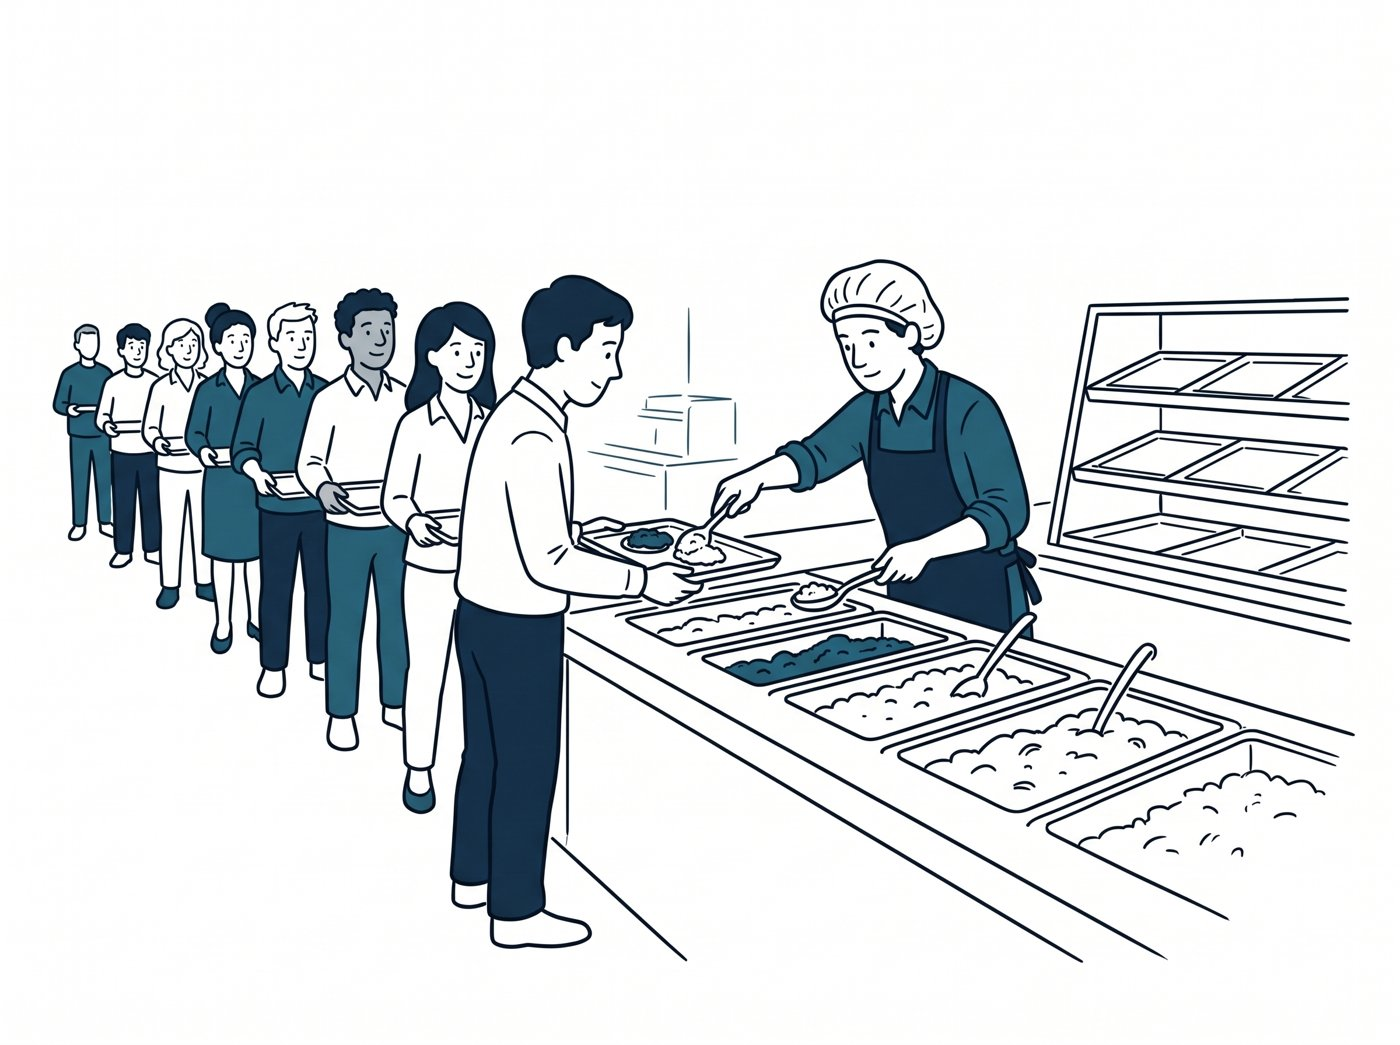<div style="text-align:center; color:#475569; font-size:0.92em; line-height:1.4; margin:-4px auto 14px; max-width:70%;">Der `DataLoader` ist die Mensaausgabe: Kein Batch liegt fertig bereit, jeder entsteht erst beim Abruf mit `next`, und am Ende der Schlange ist Schluss (`StopIteration`).</div></div>

Der `DataLoader` bekommt das Dataset und die Batchgröße. Er holt sich 64 Beispiele über `__getitem__` und stapelt die 64 Merkmalszeilen zu einem Tensor `(64, 12)` und die 64 Zieleinträge zu `(64, 1)`. `shuffle=True` mischt die Reihenfolge der Beispiele bei jedem Durchlauf neu, `torch.manual_seed(0)` macht die Mischung reproduzierbar. `len(loader)` ist die Anzahl der Batches.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Wie viele Batches liefert ein <code style="color:inherit;">DataLoader</code> mit <code style="color:inherit;">batch_size=64</code> über 1047 Beispiele, und wie groß ist der letzte?</p>

</div>

Bevor der Loader seinen ersten Batch liefert, sehen wir uns das Protokoll dahinter an einem vertrauten Objekt an, einer Liste. Eine Liste ist iterierbar, das heißt, sie hat die Methode `__iter__`. `iter(liste)` liefert einen Iterator. Das ist ein anderes Objekt, das die Methode `__next__` hat. `next(iterator)` gibt das nächste Element zurück, und nach dem letzten Element meldet `__next__` mit `StopIteration`, dass nichts mehr kommt. Jede `for`-Schleife macht genau das: Sie ruft einmal `iter` auf und dann so lange `next`, bis `StopIteration` kommt.

In [ ]:
numbers = [10, 20, 30]
numbers_it = iter(numbers)
print(hasattr(numbers, "__next__"), hasattr(numbers_it, "__next__"))
print(next(numbers_it), next(numbers_it), next(numbers_it))
try:
    next(numbers_it)
except StopIteration:
    print("StopIteration: nichts mehr da")

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">numbers <span style="color: #666">=</span> [<span style="color: #666">10</span>, <span style="color: #666">20</span>, <span style="color: #666">30</span>]</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">iter(liste)</code> liefert einen Iterator über die Liste. Die Liste selbst hat kein <code style="color:inherit;">__next__</code></div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">numbers_it <span style="color: #666">=</span> <span style="color: #008000">iter</span>(numbers)
<span style="color: #008000">print</span>(<span style="color: #008000">hasattr</span>(numbers, <span style="color: #BA2121">"__next__"</span>), <span style="color: #008000">hasattr</span>(numbers_it, <span style="color: #BA2121">"__next__"</span>))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; jedes <code style="color:inherit;">next(numbers_it)</code> liefert das nächste Element. Der Iterator rückt dabei eine Position weiter, die Liste bleibt unverändert</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #008000">next</span>(numbers_it), <span style="color: #008000">next</span>(numbers_it), <span style="color: #008000">next</span>(numbers_it))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>③</b>&nbsp; nach dem letzten Element löst <code style="color:inherit;">next</code> die Ausnahme <code style="color:inherit;">StopIteration</code> aus. Die <code style="color:inherit;">for</code>-Schleife fängt sie ab und endet</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000; font-weight: bold">try</span>:
    <span style="color: #008000">next</span>(numbers_it)
<span style="color: #008000; font-weight: bold">except</span> <span style="color: #CB3F38; font-weight: bold">StopIteration</span>:
    <span style="color: #008000">print</span>(<span style="color: #BA2121">"StopIteration: nichts mehr da"</span>)</code></pre></details>

In [ ]:
torch.manual_seed(0)
loader = DataLoader(ds, batch_size=64, shuffle=True)
print("Batches:", len(loader), "| Beispiele:", len(ds))
loader_it = iter(loader)
xb, yb = next(loader_it)
print("erster Batch:", xb.shape, yb.shape, xb.dtype)
print("Loader hat __next__:", hasattr(loader, "__next__"), "| Iterator hat __next__:", hasattr(loader_it, "__next__"))
# Formen: ds (1047 Beispiele) -> xb (64, 12), yb (64, 1)

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">torch<span style="color: #666">.</span>manual_seed(<span style="color: #666">0</span>)</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">DataLoader(ds, batch_size=64, shuffle=True)</code> legt den Loader an. Er holt Beispiele erst, wenn ein Batch abgerufen wird</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">loader <span style="color: #666">=</span> DataLoader(ds, batch_size<span style="color: #666">=64</span>, shuffle<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">True</span>)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Batches:"</span>, <span style="color: #008000">len</span>(loader), <span style="color: #BA2121">"| Beispiele:"</span>, <span style="color: #008000">len</span>(ds))</code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">iter(loader)</code> erzeugt einen Iterator, <code style="color:inherit;">next(loader_it)</code> holt den nächsten Batch. Ein Batch ist eine Liste aus zwei Tensoren</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">loader_it <span style="color: #666">=</span> <span style="color: #008000">iter</span>(loader)
xb, yb <span style="color: #666">=</span> <span style="color: #008000">next</span>(loader_it)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"erster Batch:"</span>, xb<span style="color: #666">.</span>shape, yb<span style="color: #666">.</span>shape, xb<span style="color: #666">.</span>dtype)
<span style="color: #008000">print</span>(<span style="color: #BA2121">"Loader hat __next__:"</span>, <span style="color: #008000">hasattr</span>(loader, <span style="color: #BA2121">"__next__"</span>), <span style="color: #BA2121">"| Iterator hat __next__:"</span>, <span style="color: #008000">hasattr</span>(loader_it, <span style="color: #BA2121">"__next__"</span>))
<span style="color: #3D7B7B; font-style: italic"># Formen: ds (1047 Beispiele) -&gt; xb (64, 12), yb (64, 1)</span></code></pre></details>

Der Loader verhält sich wie die Liste. Das ist das dritte Beispiel für die Idee aus der Einleitung, dass ein Objekt über seine Methoden passt und nicht über seine Klasse. Diesmal sind zwei Objekte beteiligt. Der Loader ist iterierbar: Er hat `__iter__`, und `iter(loader)` ruft diese Methode auf und bekommt einen Iterator zurück. Der Iterator `loader_it` ist ein anderes Objekt mit der Methode `__next__`, und `next(loader_it)` ruft sie auf und bekommt den nächsten Batch. Der Loader selbst hat kein `__next__`, deshalb geht `next(loader)` nicht. `for xb, yb in loader:` ruft `iter(loader)` einmal und dann `next` so lange, bis `StopIteration` kommt.

<div style="border:2px solid #E97132; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#E97132; font-weight:bold; font-size:1.08em;">💭 Kurz überlegen</span></div>
<p>Was passiert bei <code style="color:inherit;">next(loader_it)</code>, nachdem der Iterator den siebzehnten Batch geliefert hat?</p>

</div>

Batches entstehen auf Abruf. In der hier verwendeten Konfiguration (`num_workers=0`, der Standard) hält der Loader keine Batches vor, erst `next` holt die 64 Beispiele und stapelt sie. Mit mehreren Arbeitsprozessen (`num_workers` größer 0) kann der Loader Batches im Voraus laden, das kommt in der nächsten Lerneinheit.

Für den einfachen Fall, dass Merkmale und Ziel schon als Tensoren vorliegen, bringt PyTorch das Dataset fertig mit: `TensorDataset(X_t, y_t)` tut dasselbe wie `TitanicDataset`. Und eine Klasse, die nur die zwei Sondermethoden hat und nicht von `Dataset` erbt, funktioniert im `DataLoader` genauso, wie die nächste Zelle zeigt. Das ist dieselbe Idee wie bei `fit` und `transform`, und auch hier reichen die Methodennamen allein nicht: `__getitem__` muss etwas liefern, das der Loader stapeln kann, hier ein Tupel aus Tensoren. Ein beliebiges Objekt kann er nicht stapeln.

In [ ]:
class PlainDataset:
    def __init__(self, X_t, y_t):
        self.X, self.y = X_t, y_t
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, i):
        return self.X[i], self.y[i]

plain_loader = DataLoader(PlainDataset(X_train_t, y_train_t), batch_size=64)
tensor_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64)
print("ohne Basisklasse:", len(plain_loader), next(iter(plain_loader))[0].shape)
print("TensorDataset:   ", len(tensor_loader), next(iter(tensor_loader))[0].shape)

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">Kurzübung</span>✏️ Aufgabe 5.6 #2</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Was kommt heraus? Die nächste Zelle schickt die sechs Zeilen von <code style="color:inherit;">small</code> durch die Vorverarbeitung und <code style="color:inherit;">to_tensors</code>, baut daraus <code style="color:inherit;">ds_small</code> und enthält dazu vier Codezeilen. Schreiben Sie Ihre Vorhersage hinter das <code style="color:inherit;"># -&gt;</code>, führen Sie die Zelle aus und vergleichen Sie.</p>

</div>
</div>

In [ ]:
X_small_t, y_small_t = to_tensors(pipe["prep"], small[num_cols + cat_cols], small["survived"])
ds_small = TitanicDataset(X_small_t, y_small_t)
loader_small = DataLoader(ds_small, batch_size=4)
print(len(ds_small))                       # -> ?
print(ds_small[0][0].shape)                # -> ?
print(len(loader_small))                   # -> ?
print(next(iter(loader_small))[0].shape)   # -> ?

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#2E7D32; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;"><span style="float:right; font-weight:600; font-size:0.85em; opacity:0.95;">5 min</span>✏️ Aufgabe 5.6 #3</div>
<div style="background:#EAF4EB; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Schreiben Sie <code style="color:inherit;">batch_shapes(loader)</code>. Die Funktion geht mit einer <code style="color:inherit;">for</code>-Schleife über alle Batches des Loaders und gibt eine Liste zurück, die je Batch das Tupel <code style="color:inherit;">(xb.shape, yb.shape)</code> enthält. Die Prüfzelle erwartet 17 Einträge: sechzehnmal <code style="color:inherit;">(64, 12)</code> und <code style="color:inherit;">(64, 1)</code> und zuletzt <code style="color:inherit;">(23, 12)</code> und <code style="color:inherit;">(23, 1)</code>. Die Zelle danach prüft getrennt davon, dass ein Loader mit <code style="color:inherit;">shuffle=True</code> jedes Beispiel genau einmal liefert.</p>
<p>Wer früher fertig ist: Der Loader <code style="color:inherit;">id_loader</code> wird in der Zelle nach der Prüfzelle angelegt. Sammeln Sie in einer neuen Zelle die Nummern aus zwei Durchläufen über diesen Loader und zeigen Sie, dass die Reihenfolge verschieden ist, die Menge der Nummern aber gleich.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#2E7D32; font-weight:600; font-size:0.9em">Hinweis anzeigen</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #2E7D3255"><p><strong>Hinweis:</strong> <code style="color:inherit;">for xb, yb in loader:</code> liefert je Durchgang einen Batch als zwei Tensoren, und <code style="color:inherit;">shapes.append((xb.shape, yb.shape))</code> sammelt.</p></div></details>
</div>
</div>

In [ ]:
def batch_shapes(loader):
    """Sammelt je Batch des Loaders die Formen von Merkmalen und Ziel."""
    shapes = []
    # TODO: Ihre Lösung hier
    ...
    return shapes

In [ ]:
# Prüfzelle — einfach ausführen
shapes = batch_shapes(loader)
assert len(shapes) == 17, f"17 Batches erwartet, nicht {len(shapes)}"
assert all(s == (torch.Size([64, 12]), torch.Size([64, 1])) for s in shapes[:16]), "die ersten 16 Batches haben die Formen (64, 12) und (64, 1)"
assert shapes[16] == (torch.Size([23, 12]), torch.Size([23, 1])), "der letzte Batch hat 23 Beispiele"
assert batch_shapes(DataLoader(ds, batch_size=64, drop_last=True)) == shapes[:16], "mit drop_last=True fehlt der unvollständige Batch"
print("erster Batch:", shapes[0], "| letzter Batch:", shapes[-1])
print("Alle Prüfungen bestanden ✓")

Dass ein Loader mit `shuffle=True` jedes Beispiel genau einmal liefert, lässt sich an den Kursdaten schlecht prüfen, weil Zeilen einander gleichen können. Die nächste Zelle nimmt deshalb ein kleines Dataset, dessen einziges Merkmal die Beispielnummer 0 bis 99 ist, sammelt die Nummern aus allen Batches ein und sortiert sie: Kommt genau die Folge 0 bis 99 heraus, fehlt kein Beispiel und keines ist doppelt.

In [ ]:
ids = torch.arange(100, dtype=torch.float32).reshape(-1, 1)
id_loader = DataLoader(TensorDataset(ids, ids), batch_size=16, shuffle=True)
seen = []
for xb, yb in id_loader:
    seen.extend(xb[:, 0].tolist())                  # die Nummern dieses Batches anhängen
print("Batches:", len(id_loader), "| eingesammelt:", len(seen), "| erste zehn in Loader-Reihenfolge:", [int(v) for v in seen[:10]])
print("jedes Beispiel genau einmal:", sorted(seen) == list(range(100)))

<details style="margin:4px 0 10px"><summary style="cursor:pointer; color:#156082; font-weight:600;">Code Schritt für Schritt</summary><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>①</b>&nbsp; <code style="color:inherit;">torch.arange(100, dtype=torch.float32)</code> ist das Gegenstück zu <code style="color:inherit;">np.arange</code>. <code style="color:inherit;">.reshape(-1, 1)</code> macht eine Spalte daraus</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;">ids <span style="color: #666">=</span> torch<span style="color: #666">.</span>arange(<span style="color: #666">100</span>, dtype<span style="color: #666">=</span>torch<span style="color: #666">.</span>float32)<span style="color: #666">.</span>reshape(<span style="color: #666">-1</span>, <span style="color: #666">1</span>)
id_loader <span style="color: #666">=</span> DataLoader(TensorDataset(ids, ids), batch_size<span style="color: #666">=16</span>, shuffle<span style="color: #666">=</span><span style="color: #008000; font-weight: bold">True</span>)
seen <span style="color: #666">=</span> []
<span style="color: #008000; font-weight: bold">for</span> xb, yb <span style="color: #A2F; font-weight: bold">in</span> id_loader:
    seen<span style="color: #666">.</span>extend(xb[:, <span style="color: #666">0</span>]<span style="color: #666">.</span>tolist())                  <span style="color: #3D7B7B; font-style: italic"># die Nummern dieses Batches anhängen</span></code></pre><div style="margin:8px 0 2px; color:#475569; color:var(--vscode-foreground, #475569);"><b>②</b>&nbsp; <code style="color:inherit;">sorted(seen)</code> ordnet die eingesammelten Nummern. <code style="color:inherit;">== list(range(100))</code> prüft, ob es genau 0 bis 99 sind</div><pre style="background:#F6F8FA; color:#1a1a1a; border:1px solid #E2E8F0; border-radius:4px; padding:7px 10px; box-sizing:border-box; font-size:0.82em; line-height:1.4; overflow-x:auto; margin:2px 0 8px; text-align:left;"><code style="color:inherit;"><span style="color: #008000">print</span>(<span style="color: #BA2121">"Batches:"</span>, <span style="color: #008000">len</span>(id_loader), <span style="color: #BA2121">"| eingesammelt:"</span>, <span style="color: #008000">len</span>(seen), <span style="color: #BA2121">"| erste zehn in Loader-Reihenfolge:"</span>, [<span style="color: #008000">int</span>(v) <span style="color: #008000; font-weight: bold">for</span> v <span style="color: #A2F; font-weight: bold">in</span> seen[:<span style="color: #666">10</span>]])
<span style="color: #008000">print</span>(<span style="color: #BA2121">"jedes Beispiel genau einmal:"</span>, <span style="color: #008000">sorted</span>(seen) <span style="color: #666">==</span> <span style="color: #008000">list</span>(<span style="color: #008000">range</span>(<span style="color: #666">100</span>)))</code></pre></details>

Die Grafik zeigt beide Objekte. Links liegen die Tensoren `X_train_t` mit `(1047, 12)` und `y_train_t` mit `(1047, 1)`. Das `Dataset` in der Mitte beantwortet `len(ds)` mit 1047 und `ds[i]` mit der Zeile `i` aus beiden Tensoren. Der `DataLoader` rechts ruft `ds[i]` für 64 Nummern auf und stapelt die Antworten zu den Tensoren `(64, 12)` und `(64, 1)`. Die drei dunklen Streifen in den Tensoren sind drei Beispiele, die der Loader gerade herausgreift. Die Nummern kommen bei `shuffle=True` in zufälliger Reihenfolge, jede genau einmal je Durchlauf.

<div style="border:2px solid #475569; background:#fff; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; border-radius:6px; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="overflow:hidden; margin-bottom:4px;"><span style="color:#475569; font-weight:bold; font-size:1.08em;">Überblick: Dataset, DataLoader und das Iterationsprotokoll</span></div>
<p><code style="color:inherit;">X_t</code>, <code style="color:inherit;">y_t</code> sind die Tensoren aus <code style="color:inherit;">to_tensors</code>, <code style="color:inherit;">ds</code> ein Dataset, <code style="color:inherit;">loader</code> ein DataLoader.</p>
<table style="table-layout:fixed; width:100%;"><colgroup><col style="width:26%"><col style="width:44%"><col style="width:30%"></colgroup>
<thead>
<tr>
<th>Absicht</th>
<th>Code</th>
<th>Ergebnis</th>
</tr>
</thead>
<tbody>
<tr>
<td>ein eigenes Dataset schreiben</td>
<td><code style="color:inherit;">class TitanicDataset(Dataset)</code> mit <code style="color:inherit;">__len__</code> und <code style="color:inherit;">__getitem__</code></td>
<td><code style="color:inherit;">len(ds)</code> Anzahl, <code style="color:inherit;">ds[i]</code> Tupel <code style="color:inherit;">(X_t[i], y_t[i])</code></td>
</tr>
<tr>
<td>ein Dataset aus fertigen Tensoren bauen</td>
<td><code style="color:inherit;">TensorDataset(X_t, y_t)</code></td>
<td>dasselbe ohne eigene Klasse</td>
</tr>
<tr>
<td>Batches aus einem Dataset liefern lassen</td>
<td><code style="color:inherit;">DataLoader(ds, batch_size=64, shuffle=True)</code></td>
<td>liefert Batches, mischt je Durchlauf</td>
</tr>
<tr>
<td>die Anzahl der Batches erfragen</td>
<td><code style="color:inherit;">len(loader)</code></td>
<td>17 bei 1047 Beispielen, 16 mit <code style="color:inherit;">drop_last=True</code></td>
</tr>
<tr>
<td>einen einzelnen Batch holen</td>
<td><code style="color:inherit;">xb, yb = next(iter(loader))</code></td>
<td>Tensoren <code style="color:inherit;">(64, 12)</code> und <code style="color:inherit;">(64, 1)</code></td>
</tr>
<tr>
<td>alle Batches durchlaufen</td>
<td><code style="color:inherit;">for xb, yb in loader:</code></td>
<td>ruft <code style="color:inherit;">iter</code> einmal und <code style="color:inherit;">next</code> bis <code style="color:inherit;">StopIteration</code></td>
</tr>
<tr>
<td>die Mischung reproduzierbar machen</td>
<td><code style="color:inherit;">torch.manual_seed(0)</code> vor dem Anlegen des Iterators</td>
<td>gleicher Seed und gleiche Aufruffolge ergeben dieselbe Mischung, weitere Durchläufe mischen neu</td>
</tr>
</tbody>
</table>
<p>Falle: <code style="color:inherit;">next(loader)</code> geht nicht, weil der Loader kein <code style="color:inherit;">__next__</code> hat. Erst <code style="color:inherit;">iter(loader)</code> liefert den Iterator.</p>

</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#107C72; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Vertiefung: num_workers und pin_memory</div>
<div style="background:#E7F4F2; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<p>Zwei Parameter des <code style="color:inherit;">DataLoader</code> betreffen die Geschwindigkeit, nicht die Daten: <code style="color:inherit;">num_workers</code> legt fest, wie viele Arbeitsprozesse Batches im Voraus zusammenstellen, und <code style="color:inherit;">pin_memory</code> bereitet die Batches für den schnelleren Transfer auf eine GPU vor.</p>
<details style="margin-top:10px"><summary style="cursor:pointer; color:#107C72; font-weight:600; font-size:0.9em">Mehr dazu</summary><div style="margin-top:8px; padding-top:8px; border-top:1px dashed #107C7255"><p>Beide sind in dieser Lerneinheit auf ihren Standardwerten (<code style="color:inherit;">0</code> und <code style="color:inherit;">False</code>), und bei 1047 Zeilen aus zwölf Zahlen spielen sie keine Rolle. Sobald in einer späteren Lerneinheit eine GPU dazukommt und wir messen, wie viel Zeit Laden und Rechnen kosten, kommen beide wieder vor.</p></div></details>
</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">➡️ Nächste Schritte</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<ul>
<li>Beenden Sie die Aufgaben, die im Termin offen geblieben sind. Zur Schlusskontrolle starten Sie die Laufzeit neu und führen alle Zellen aus: Alle Prüfzellen sollten mit Ihren eigenen Lösungen durchlaufen.</li>
<li>Grundkurs Teil 4 (Klassen, Signaturen und Stil) ist der Begleiter dieser Lerneinheit. Er erklärt, was hier nur benannt wurde: Vererbung, <code style="color:inherit;">super().__init__()</code> und <code style="color:inherit;">__call__</code>, an einem Lehrmodell nach dem Muster von <code style="color:inherit;">nn.Module</code>.</li>
<li>Die Referenzkarte „scikit-learn und der Übergang zu PyTorch“ (<code style="color:inherit;">LE05_referenzkarte_sklearn_dataloader.pdf</code>) fasst die Werkzeuge dieser Lerneinheit zusammen.</li>
</ul>
<p><strong>→ Ausblick:</strong> In der nächsten Lerneinheit trainieren wir mit genau diesem <code style="color:inherit;">DataLoader</code> ein neuronales Netz. Dazu gehören Tensoren auf CPU und GPU, das Messen von Laufzeiten und der Trainings-Loop aus Vorhersage, Verlust, Ableitung und Schritt.</p>

</div>
</div>

<div style="border-radius:6px; overflow:hidden; margin:2px 0; margin-right:-20px; margin-right:calc(var(--jp-cell-padding, 0px) * -4);">
<div style="background:#E8B029; color:#fff; padding:6px 16px; box-sizing:border-box; font-weight:bold; font-size:1.08em; margin:0; overflow:hidden;">Quellen und Referenzen</div>
<div style="background:#FDF6E3; color:#1a1a1a; padding:12px 16px; box-sizing:border-box; margin:0;">
<ul>
<li>scikit-learn-Dokumentation: <a href="https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html">Column Transformer with Mixed Types</a> (das Beispiel mit dem Titanic-Datensatz, Vorlage für den Aufbau der Vorverarbeitung), <a href="https://scikit-learn.org/stable/developers/develop.html">Developing scikit-learn estimators</a>, <a href="https://scikit-learn.org/stable/modules/compose.html">Pipelines and composite estimators</a>, <a href="https://scikit-learn.org/stable/common_pitfalls.html#data-leakage">Common pitfalls: Data leakage</a>, <a href="https://scikit-learn.org/stable/modules/cross_validation.html">Cross-validation</a>, <a href="https://scikit-learn.org/stable/modules/model_evaluation.html">Metrics and scoring</a>.</li>
<li>A. Géron: <em>Hands-On Machine Learning with Scikit-Learn and PyTorch</em>, Kapitel 2 (Scikit-Learn Design, Pipelines).</li>
<li>J. VanderPlas: <em>Python Data Science Handbook</em>, 2. Auflage, Kapitel 38 bis 40, jakevdp.github.io/PythonDataScienceHandbook.</li>
<li>S. Raschka, Y. Liu, V. Mirjalili: <em>Machine Learning with PyTorch and Scikit-Learn</em>, Kapitel 12 (Dataset und DataLoader).</li>
<li>PyTorch-Dokumentation: <a href="https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html">Datasets &amp; DataLoaders</a>, <a href="https://docs.pytorch.org/docs/stable/data.html">torch.utils.data</a>, <a href="https://docs.pytorch.org/docs/stable/generated/torch.from_numpy.html">torch.from_numpy</a>, <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html">BCEWithLogitsLoss</a>.</li>
<li>Python-Dokumentation: <a href="https://docs.python.org/3/library/stdtypes.html#iterator-types">Iterator Types</a>.</li>
<li>Datengrundlage: Titanic-Passagierliste, F. E. Harrell Jr. und T. Cason, Vanderbilt University Department of Biostatistics, auf <a href="https://www.openml.org/d/40945">OpenML als Datensatz 40945</a>, Lizenz Public. <code style="color:inherit;">titanic_clean.csv</code> ist die in LE04 bereinigte Kursfassung, Herkunft und Prüfsummen stehen im Datenblatt <code style="color:inherit;">DATENBLATT_titanic.md</code>.</li>
</ul>
<p style="font-size:0.88em; font-style:italic; color:#5a6472; margin:12px 0 0;">Dieses Material wurde mit Unterstützung von KI-Werkzeugen entwickelt (Text und Code: Claude und ChatGPT, Karikaturen: Google Gemini). Alle Inhalte sind von Prof. Dr. Stephan Kurpjuweit konzipiert, geprüft und verantwortet.</p>

</div>
</div>